# Financial sentiment with early-exit FinBERT

**Question:** Can we classify financial headlines faster by stopping FinBERT early, while keeping macro-F1 within 1 percentage point of the full model?

Run this notebook from top to bottom in a **Colab GPU runtime**. Data and pretrained weights download automatically. No Kaggle account or additional Python uploads are needed.

## Read this first

1. **Prepare the data.** Keep single-entity headlines and separate similar headlines into the same split.
2. **Train the teacher.** Fine-tune the normal 12-layer FinBERT model for 3 epochs.
3. **Train the exits.** Freeze the teacher and train small classifiers after layers 2, 4, and 8 for 5 epochs.
4. **Calibrate confidence.** Fit temperatures on a separate calibration split.
5. **Choose a policy.** Use validation results to choose a confidence threshold and compare full, fixed-depth, and dynamic inference.
6. **Evaluate once.** Freeze the choice before measuring held-out test quality and actual GPU latency.

| Term | Meaning in this notebook |
|---|---|
| Teacher / backbone | The ordinary 12-layer FinBERT model |
| Exit head | A small sentiment classifier attached to an intermediate layer |
| Static exit | Always stop at one fixed layer |
| Dynamic exit | Stop at the first exit whose calibrated confidence reaches the threshold |
| Calibration | Rescale confidence without changing the head's predicted class |
| Macro-F1 | Average F1 across positive, negative, and neutral, with equal class weight |
| p50 / p95 latency | Median / 95th-percentile prediction time |

**What to edit:** the configuration cell. The two implementation cells contain the tested helper code; you can expand them later. Start with `EarlyExitFinBERT.predict_one()` to understand actual layer skipping, and `train_stage()` to understand training.

This run uses **all retained single-entity headlines**, one training seed, teacher 3 epochs, heads 5 epochs, and training batches of 16. Inference latency is measured at batch size 1. A faster dynamic model is a hypothesis, not an assumed result.

In [ ]:
# Install pinned dependencies in a fresh runtime; keep Colab's CUDA-enabled PyTorch.
%pip -q install "transformers==4.48.3" "numpy>=1.26,<3" "pandas>=2.2,<3" "scikit-learn>=1.4,<2" "scipy>=1.13,<2" "matplotlib>=3.8,<4" "requests>=2.31,<3" "tqdm>=4.66,<5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


## Implementation files (advanced; expand when needed)

The next two cells write the Python modules embedded in this notebook. They make the notebook self-contained.

- `early_exit_finbert.py`: the model, exit heads, training loss, actual early-return inference, and checkpoint loading.
- `sentfin_pipeline.py`: data cleaning, splits, training, calibration, benchmarking, and charts.

Transformers is pinned to 4.48.3 because the implementation calls BERT's internal layer API. Training may use mixed precision; **all reported inference uses FP32 and eager attention**.

In [ ]:
%%writefile early_exit_finbert.py
"""A small, batch-size-one early-exit BERT research implementation.

Intermediate heads must be trained. The backbone and its final head stay frozen.
Uses Transformers 4.48.3's BERT layer API and eager attention.
"""

import copy
import math
from collections.abc import Iterable
from pathlib import Path

import torch
from torch import nn
from torch.nn import functional as F
from transformers import BertForSequenceClassification


class EarlyExitFinBERT(nn.Module):
    def __init__(self, backbone: BertForSequenceClassification, exit_layers=(2, 4, 8)):
        super().__init__()
        self.backbone = backbone
        self.depth = backbone.config.num_hidden_layers
        self.exit_layers = tuple(sorted(set(exit_layers)))
        if not self.exit_layers or any(k < 1 or k >= self.depth for k in self.exit_layers):
            raise ValueError("Exit layers must be between 1 and depth - 1.")
        if backbone.config.is_decoder or backbone.config._attn_implementation != "eager":
            raise ValueError("Use an encoder BERT loaded with attn_implementation='eager'.")

        # A separate pooler and classifier for each intermediate representation.
        # Copying the final head initializes these heads; it does NOT train them.
        self.heads = nn.ModuleDict({
            str(k): nn.Sequential(
                copy.deepcopy(backbone.bert.pooler),
                copy.deepcopy(backbone.dropout),
                copy.deepcopy(backbone.classifier),
            )
            for k in self.exit_layers
        })
        self.heads.requires_grad_(True)
        self.backbone.requires_grad_(False)
        self.backbone.eval()
        self.training_steps = 0
        self.register_buffer("temperatures", torch.ones(self.depth + 1))

    def set_temperatures(self, temperatures):
        """Apply head temperatures fitted on an independent calibration split."""
        for layer, value in temperatures.items():
            layer, value = int(layer), float(value)
            if layer not in (*self.exit_layers, self.depth) or not math.isfinite(value) or value <= 0:
                raise ValueError("Expected a valid exit layer and a finite positive temperature.")
            self.temperatures[layer] = value
        return self

    def train(self, mode=True):
        super().train(mode)
        # Keep the frozen teacher deterministic, including during head training.
        self.backbone.eval()
        return self

    def all_logits(self, **inputs):
        """Full computation for training/evaluation, NOT accelerated inference."""
        with torch.no_grad():
            teacher = self.backbone(**inputs, output_hidden_states=True, return_dict=True)
        # hidden_states[0] is embeddings; hidden_states[k] is AFTER layer k.
        logits = {k: self.heads[str(k)](teacher.hidden_states[k]) for k in self.exit_layers}
        logits[self.depth] = teacher.logits
        return logits

    def training_loss(self, labels, *, temperature=2.0, alpha=0.5, **inputs):
        """Gold-label CE plus KL distillation from the final classifier."""
        if temperature <= 0 or not 0 <= alpha <= 1:
            raise ValueError("Require temperature > 0 and alpha in [0, 1].")
        logits = self.all_logits(**inputs)
        teacher_probs = F.softmax(logits[self.depth] / temperature, dim=-1)
        losses = []
        for k in self.exit_layers:
            ce = F.cross_entropy(logits[k], labels)
            kd = F.kl_div(
                F.log_softmax(logits[k] / temperature, dim=-1),
                teacher_probs,
                reduction="batchmean",
            ) * temperature**2
            losses.append(alpha * ce + (1 - alpha) * kd)
        return torch.stack(losses).mean()

    @torch.inference_mode()
    def predict_one(self, input_ids, attention_mask=None, token_type_ids=None, *, threshold=0.95):
        """Return (logits, executed_layers), stopping before deeper layers run.

        threshold=math.inf disables exits; confidence uses stored temperatures.
        Batch size is deliberately one: mixed-depth batching needs active-row routing.
        """
        if input_ids.ndim != 2 or input_ids.shape[0] != 1:
            raise ValueError("predict_one supports batch size 1 only.")
        if not (0 <= threshold <= 1 or threshold == math.inf):
            raise ValueError("threshold must be in [0, 1], or +inf to disable exits.")
        if threshold != math.inf and self.training_steps == 0:
            raise RuntimeError("Train intermediate heads before enabling early exits.")
        if self.training:
            self.eval()
        bert = self.backbone.bert
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        hidden = bert.embeddings(input_ids=input_ids, token_type_ids=token_type_ids)
        mask = bert.get_extended_attention_mask(attention_mask, input_ids.shape)

        for k, layer in enumerate(bert.encoder.layer, start=1):
            hidden = layer(hidden, attention_mask=mask)[0]
            if threshold != math.inf and k in self.exit_layers:
                logits = self.heads[str(k)](hidden) / self.temperatures[k]
                # .item() synchronizes GPU -> CPU: include this in latency measurements.
                confidence = logits.softmax(dim=-1).amax().item()
                if confidence >= threshold:
                    return logits, k

        pooled = bert.pooler(hidden)
        logits = self.backbone.classifier(self.backbone.dropout(pooled))
        return logits / self.temperatures[self.depth], self.depth

    @torch.inference_mode()
    def predict_static_one(self, input_ids, attention_mask=None, token_type_ids=None, *, exit_layer):
        """Fixed-depth baseline, without checking earlier exit heads."""
        if input_ids.ndim != 2 or input_ids.shape[0] != 1:
            raise ValueError("predict_static_one supports batch size 1 only.")
        if exit_layer not in self.exit_layers or self.training_steps == 0:
            raise ValueError("Choose a trained intermediate exit layer.")
        if self.training:
            self.eval()
        bert = self.backbone.bert
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        hidden = bert.embeddings(input_ids=input_ids, token_type_ids=token_type_ids)
        mask = bert.get_extended_attention_mask(attention_mask, input_ids.shape)
        for k, layer in enumerate(bert.encoder.layer, 1):
            hidden = layer(hidden, attention_mask=mask)[0]
            if k == exit_layer:
                return self.heads[str(k)](hidden) / self.temperatures[k], k
        raise AssertionError("Unreachable exit layer.")

    def save(self, directory, tokenizer, *, max_length=128):
        """Save a self-contained local checkpoint, including the original backbone."""
        import json

        if self.training_steps == 0:
            raise RuntimeError("No trained heads to save.")
        directory = Path(directory)
        directory.mkdir(parents=True, exist_ok=False)
        self.backbone.save_pretrained(directory / "backbone")
        tokenizer.save_pretrained(directory)
        torch.save(self.heads.state_dict(), directory / "exit_heads.pt")
        metadata = {
            "exit_layers": self.exit_layers,
            "training_steps": self.training_steps,
            "max_length": max_length,
            "temperatures": {str(k): self.temperatures[k].item() for k in (*self.exit_layers, self.depth)},
        }
        (directory / "early_exit.json").write_text(json.dumps(metadata, indent=2))

    @classmethod
    def load(cls, directory, *, device="cpu"):
        import json
        from transformers import AutoTokenizer

        directory = Path(directory)
        metadata = json.loads((directory / "early_exit.json").read_text())
        backbone = BertForSequenceClassification.from_pretrained(
            directory / "backbone", attn_implementation="eager", local_files_only=True
        )
        model = cls(backbone, metadata["exit_layers"])
        weights = torch.load(directory / "exit_heads.pt", map_location="cpu", weights_only=True)
        model.heads.load_state_dict(weights)
        model.training_steps = metadata["training_steps"]
        model.set_temperatures(metadata.get("temperatures", {}))
        tokenizer = AutoTokenizer.from_pretrained(directory, local_files_only=True)
        return model.to(device).eval(), tokenizer, metadata["max_length"]


def train_heads(model, batches: Iterable, *, epochs=3, learning_rate=1e-4):
    """batches yields dictionaries of tokenized tensors plus a 'labels' tensor."""
    if epochs < 1 or learning_rate <= 0:
        raise ValueError("epochs and learning_rate must be positive.")
    optimizer = torch.optim.AdamW(model.heads.parameters(), lr=learning_rate)
    device = next(model.parameters()).device
    history = []
    for _ in range(epochs):
        model.train()
        total, count = 0.0, 0
        for batch in batches:
            batch = {key: value.to(device) for key, value in batch.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = model.training_loss(**batch)
            loss.backward()
            optimizer.step()
            model.training_steps += 1
            total += loss.item()
            count += 1
        if not count:
            raise ValueError("Training requires a nonempty, reiterable batch loader.")
        history.append(total / count)
    model.eval()
    return history

Writing early_exit_finbert.py


In [ ]:
%%writefile sentfin_pipeline.py
"""Reproducible SEntFiN single-entity experiment used by the Colab notebook."""

import ast
import hashlib
import json
import math
import platform
import random
import re
import time
import unicodedata
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import torch
from scipy.optimize import minimize_scalar
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.neighbors import NearestNeighbors
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoTokenizer, BertForSequenceClassification, DataCollatorWithPadding
from transformers import get_linear_schedule_with_warmup

from early_exit_finbert import EarlyExitFinBERT


DATA_COMMIT = "eba43610fe3cb57a3e5773cd6c037da1f8992ad5"
DATA_URL = f"https://raw.githubusercontent.com/pyRis/SEntFiN/{DATA_COMMIT}/SEntFiN.csv"
DATA_SHA256 = "570af7ba58f724f3fcc414dd5ba80da5b1a3b342134d76c6ebdf53a32c54a92f"
MODEL_REVISION = "0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031"
LABEL2ID = {"positive": 0, "negative": 1, "neutral": 2}
ID2LABEL = {v: k for k, v in LABEL2ID.items()}


@dataclass
class ExperimentConfig:
    seed: int = 42
    split_seed: int = 20261023
    model_id: str = "ProsusAI/finbert"
    model_revision: str | None = MODEL_REVISION
    max_length: int = 96
    batch_size: int = 16
    teacher_epochs: int = 3
    head_epochs: int = 5
    teacher_lr: float = 2e-5
    head_lr: float = 1e-4
    exit_layers: tuple = (2, 4, 8)
    distillation_temperature: float = 2.0
    gold_weight: float = 0.5
    near_duplicate_similarity: float = 0.90
    thresholds: tuple = (0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.925, 0.95, 0.975, 0.99, 0.995)
    f1_drop_budget: float = 0.01
    validation_latency_samples: int = 128
    test_latency_samples: int = 512
    timing_repeats: int = 2
    warmup: int = 10
    bootstrap_samples: int = 500
    amp_training: bool = True
    cpu_threads: int = 1
    show_progress: bool = True


def save_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, ensure_ascii=False, allow_nan=False), encoding="utf-8")


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False


def download_sentfin(directory):
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    path = directory / "SEntFiN.csv"
    if not path.exists():
        response = requests.get(DATA_URL, timeout=60)
        response.raise_for_status()
        path.write_bytes(response.content)
    digest = hashlib.sha256(path.read_bytes()).hexdigest()
    if digest != DATA_SHA256:
        raise ValueError("SEntFiN SHA256 mismatch. Use the pinned dataset revision or a new data directory.")
    save_json(directory / "source.json", {"url": DATA_URL, "commit": DATA_COMMIT, "sha256": digest})
    return path


def parse_decisions(value, *, with_audit=False):
    """No eval. Handle the release's unescaped apostrophes with a strict fallback."""
    repaired = False
    try:
        decisions = ast.literal_eval(value)
    except (SyntaxError, ValueError):
        repaired = True
        if not isinstance(value, str) or not value.strip().startswith("{") or not value.strip().endswith("}"):
            raise ValueError("Malformed Decisions field.") from None
        body = value.strip()[1:-1]
        pattern = re.compile(r'''\s*(['"])(.*?)\1\s*:\s*(['"])(positive|negative|neutral)\3\s*(?:,|$)''')
        decisions, position = {}, 0
        while position < len(body):
            match = pattern.match(body, position)
            if match is None:
                raise ValueError("Unrecognized Decisions field; no partial parsing allowed.")
            decisions[match.group(2)] = match.group(4)
            position = match.end()
    if not isinstance(decisions, dict) or not decisions:
        raise ValueError("Expected a nonempty entity-to-label dictionary.")
    if any(not isinstance(k, str) or not k.strip() or v not in LABEL2ID for k, v in decisions.items()):
        raise ValueError("Invalid entity or label in Decisions.")
    return (decisions, repaired) if with_audit else decisions


def normalize_headline(text, *, mask_numbers=False):
    text = unicodedata.normalize("NFKC", str(text)).casefold()
    if mask_numbers:
        text = re.sub(r"\d+(?:[.,]\d+)*", " number ", text)
    return " ".join(re.findall(r"\w+", text, flags=re.UNICODE))


def prepare_sentfin(csv_path):
    raw = pd.read_csv(csv_path)
    if not {"Title", "Decisions"}.issubset(raw.columns):
        raise ValueError("Expected the original SEntFiN Title/Decisions columns.")
    records, rejected, repaired_ids, multi_entity = [], [], [], 0
    for index, row in raw.iterrows():
        try:
            decisions, repaired = parse_decisions(row["Decisions"], with_audit=True)
            if repaired:
                repaired_ids.append(int(index))
            if len(decisions) != 1:
                multi_entity += 1
                continue
            entity, label = next(iter(decisions.items()))
            if not isinstance(row["Title"], str) or not row["Title"].strip():
                raise ValueError("Empty headline.")
            records.append({
                "row_id": int(index), "text": row["Title"].strip(), "entity": entity,
                "label": LABEL2ID[label], "normalized": normalize_headline(row["Title"]),
            })
        except (ValueError, TypeError):
            rejected.append(int(index))
    frame = pd.DataFrame(records)
    # Drop all conflicting exact-text labels instead of choosing a convenient label.
    conflicts = frame.groupby("normalized")["label"].nunique()
    conflict_keys = set(conflicts[conflicts > 1].index)
    conflicting_count = int(frame["normalized"].isin(conflict_keys).sum())
    frame = frame[~frame["normalized"].isin(conflict_keys)].copy()
    before = len(frame)
    frame = frame.drop_duplicates("normalized").reset_index(drop=True)
    audit = {
        "raw_headlines": len(raw), "single_entity_before_dedup": len(records),
        "excluded_multi_entity": multi_entity, "rejected_row_ids": rejected,
        "safely_repaired_decisions_row_ids": repaired_ids,
        "conflicting_exact_text_rows_removed": conflicting_count,
        "exact_duplicate_rows_removed": before - len(frame), "retained": len(frame),
        "task": "single-entity, three-class headline sentiment; no timestamp field",
    }
    return frame, audit


def assign_duplicate_groups(frame, similarity=0.90):
    """Group numeric variants plus character-ngram near duplicates, transitively.

    This reduces text leakage. It does not establish event or chronological isolation.
    No labels are used in grouping. Chunk neighbors to avoid a dense N-by-N matrix.
    """
    if not 0 < similarity <= 1:
        raise ValueError("similarity must be in (0, 1].")
    frame = frame.copy().reset_index(drop=True)
    parent = np.arange(len(frame))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(i, j):
        a, b = root(i), root(j)
        parent[max(a, b)] = min(a, b)

    templates = {}
    for i, text in enumerate(frame.text):
        key = normalize_headline(text, mask_numbers=True)
        if key in templates:
            union(i, templates[key])
        else:
            templates[key] = i
    features = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), dtype=np.float32).fit_transform(frame.normalized)
    neighbors = NearestNeighbors(metric="cosine", algorithm="brute", n_jobs=1).fit(features)
    for start in range(0, len(frame), 128):
        matches = neighbors.radius_neighbors(
            features[start:start + 128], radius=1 - similarity + 1e-7, return_distance=False
        )
        for offset, indices in enumerate(matches):
            for j in indices:
                union(start + offset, int(j))
    frame["group_id"] = [f"group_{root(i):05d}" for i in range(len(frame))]
    return frame


def make_splits(frame, directory, *, seed=20261023):
    """Ten grouped stratified folds -> approximately 60/10/10/20 percent."""
    frame = frame.copy()
    if frame.label.value_counts().min() < 10 or frame.group_id.nunique() < 10:
        raise ValueError("Need at least 10 rows per class and 10 duplicate groups for this split.")
    splitter = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    frame["split"] = ""
    for fold, (_, heldout) in enumerate(splitter.split(frame, frame.label, frame.group_id)):
        name = "train" if fold < 6 else "validation" if fold == 6 else "calibration" if fold == 7 else "test"
        frame.loc[frame.index[heldout], "split"] = name
    if frame.groupby("group_id").split.nunique().max() != 1:
        raise AssertionError("A duplicate group crossed split boundaries.")
    if frame.groupby("normalized").split.nunique().max() != 1:
        raise AssertionError("An exact headline crossed split boundaries.")
    splits = {name: part.reset_index(drop=True) for name, part in frame.groupby("split")}
    if set(splits) != {"train", "validation", "calibration", "test"}:
        raise ValueError("Empty split; inspect duplicate groups.")
    for name, part in splits.items():
        if set(part.label) != {0, 1, 2}:
            raise ValueError(f"{name} lacks a class; inspect grouping or increase data.")
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    frame.to_csv(directory / "split_manifest.csv", index=False)
    for name, part in splits.items():
        part.to_json(directory / f"{name}.jsonl", orient="records", lines=True, force_ascii=False)
    summary = pd.crosstab(frame.split, frame.label).rename(columns=ID2LABEL)
    summary["total"] = summary.sum(axis=1)
    summary["groups"] = frame.groupby("split").group_id.nunique()
    summary.to_csv(directory / "split_counts.csv")
    return splits, summary


class HeadlineDataset(Dataset):
    def __init__(self, frame, tokenizer, max_length):
        self.tokens = tokenizer(frame.text.tolist(), truncation=True, max_length=max_length)
        self.labels = frame.label.astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, index):
        return {**{k: v[index] for k, v in self.tokens.items()}, "labels": self.labels[index]}


def make_loader(frame, tokenizer, cfg, *, shuffle=False):
    generator = torch.Generator().manual_seed(cfg.seed)
    return DataLoader(
        HeadlineDataset(frame, tokenizer, cfg.max_length), batch_size=cfg.batch_size,
        shuffle=shuffle, num_workers=0, generator=generator,
        collate_fn=DataCollatorWithPadding(tokenizer),
    )


def to_device(batch, device):
    return {k: v.to(device) for k, v in batch.items()}


def classification_scores(labels, predicted):
    return {
        "accuracy": float(accuracy_score(labels, predicted)),
        "macro_f1": float(f1_score(labels, predicted, labels=[0, 1, 2], average="macro", zero_division=0)),
    }


@torch.inference_mode()
def collect_teacher_logits(model, loader, device):
    model.eval()
    logits, labels = [], []
    for batch in loader:
        batch = to_device(batch, device)
        labels.append(batch.pop("labels").cpu())
        logits.append(model(**batch).logits.float().cpu())
    return torch.cat(logits), torch.cat(labels)


@torch.inference_mode()
def collect_exit_logits(model, loader, device):
    """Cached FULL-depth logits for offline quality scoring, not timing."""
    model.eval()
    outputs = {k: [] for k in (*model.exit_layers, model.depth)}
    labels = []
    for batch in loader:
        batch = to_device(batch, device)
        labels.append(batch.pop("labels").cpu())
        for k, logits in model.all_logits(**batch).items():
            outputs[k].append(logits.float().cpu())
    return {k: torch.cat(v) for k, v in outputs.items()}, torch.cat(labels)


def train_stage(model, train_loader, val_loader, cfg, directory, device, *, stage):
    """Checkpoint every best epoch. A completed stage can be reused after reconnect."""
    directory = Path(directory)
    marker = directory / f"{stage}_complete.json"
    weights_path = directory / "best_heads.pt"
    if marker.exists():
        info = json.loads(marker.read_text())
        if stage == "heads":
            model.heads.load_state_dict(torch.load(weights_path, weights_only=True, map_location=device))
            model.training_steps = info["training_steps"]
            return model.eval(), pd.DataFrame(info["history"])
        loaded = BertForSequenceClassification.from_pretrained(directory / "teacher", attn_implementation="eager", local_files_only=True)
        return loaded.to(device).eval(), pd.DataFrame(info["history"])
    is_heads = stage == "heads"
    stage_seed = cfg.seed + (100 if is_heads else 0)
    seed_everything(stage_seed)
    if train_loader.generator is not None:
        train_loader.generator.manual_seed(stage_seed)
    epochs, lr = (cfg.head_epochs, cfg.head_lr) if is_heads else (cfg.teacher_epochs, cfg.teacher_lr)
    if epochs < 1 or lr <= 0:
        raise ValueError("Require positive epochs and learning rate.")
    parameters = list(model.heads.parameters()) if is_heads else list(model.parameters())
    optimizer = torch.optim.AdamW(parameters, lr=lr, weight_decay=0.01)
    steps = epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(steps * 0.1), steps)
    amp = cfg.amp_training and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    history, best = [], -math.inf
    for epoch in range(epochs):
        model.train()
        total, count = 0.0, 0
        for batch in tqdm(train_loader, desc=f"{stage} {epoch + 1}/{epochs}", disable=not cfg.show_progress):
            batch = to_device(batch, device)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                if is_heads:
                    loss = model.training_loss(**batch, temperature=cfg.distillation_temperature, alpha=cfg.gold_weight)
                else:
                    loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise FloatingPointError("Nonfinite training loss. Disable AMP or reduce learning rate.")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            previous_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= previous_scale:
                scheduler.step()
            if is_heads:
                model.training_steps += 1
            total += loss.item() * len(batch["labels"])
            count += len(batch["labels"])
        if is_heads:
            logits, labels = collect_exit_logits(model, val_loader, device)
            score = float(np.mean([classification_scores(labels, logits[k].argmax(-1))["macro_f1"] for k in model.exit_layers]))
        else:
            logits, labels = collect_teacher_logits(model, val_loader, device)
            score = classification_scores(labels, logits.argmax(-1))["macro_f1"]
        row = {"epoch": epoch + 1, "train_loss": total / count, "validation_macro_f1": score}
        history.append(row)
        if cfg.show_progress:
            print(row)
        if score > best:
            best = score
            if is_heads:
                torch.save(model.heads.state_dict(), weights_path)
            else:
                model.save_pretrained(directory / "teacher", safe_serialization=True)
        pd.DataFrame(history).to_csv(directory / f"{stage}_history.csv", index=False)
    info = {"history": history, "training_steps": model.training_steps if is_heads else steps}
    # Release optimizer memory before loading the best full model.
    del optimizer, scheduler, scaler
    if is_heads:
        model.heads.load_state_dict(torch.load(weights_path, weights_only=True, map_location=device))
    else:
        model.to("cpu")
        model = BertForSequenceClassification.from_pretrained(directory / "teacher", attn_implementation="eager", local_files_only=True).to(device)
    save_json(marker, info)
    return model.eval(), pd.DataFrame(history)


def probability_metrics(logits, labels, *, bins=15):
    logits, labels = logits.float(), labels.long()
    probabilities = logits.softmax(-1)
    confidence, predicted = probabilities.max(-1)
    correct = predicted.eq(labels).float()
    ece = 0.0
    for lower, upper in zip(np.linspace(0, 1, bins + 1)[:-1], np.linspace(0, 1, bins + 1)[1:]):
        mask = (confidence > lower) & (confidence <= upper)
        if mask.any():
            ece += mask.float().mean().item() * abs(correct[mask].mean().item() - confidence[mask].mean().item())
    one_hot = torch.nn.functional.one_hot(labels, num_classes=3)
    return {
        "nll": torch.nn.functional.cross_entropy(logits, labels).item(),
        "ece": ece,
        "brier": (probabilities - one_hot).square().sum(-1).mean().item(),
    }


def fit_temperature(logits, labels):
    """One positive scalar per head, fitted ONLY on calibration labels."""
    logits, labels = logits.detach().double().cpu(), labels.long().cpu()

    def objective(log_temperature):
        return torch.nn.functional.cross_entropy(logits / math.exp(log_temperature), labels).item()

    solution = minimize_scalar(objective, bounds=(math.log(0.05), math.log(20.0)), method="bounded")
    temperature = math.exp(solution.x)
    # Including T=1 protects against a failed numerical fit.
    if not solution.success or objective(solution.x) > objective(0.0):
        temperature = 1.0
    return temperature


def calibrate_heads(raw_logits, labels):
    temperatures, rows = {}, []
    for layer, logits in raw_logits.items():
        temperature = fit_temperature(logits, labels)
        temperatures[layer] = temperature
        before, after = probability_metrics(logits, labels), probability_metrics(logits / temperature, labels)
        rows.append({
            "layer": layer, "temperature": temperature,
            **{f"before_{k}": v for k, v in before.items()},
            **{f"after_{k}": v for k, v in after.items()},
        })
    return temperatures, pd.DataFrame(rows)


def apply_temperatures(raw_logits, temperatures):
    return {k: logits / temperatures[k] for k, logits in raw_logits.items()}


def make_policies(exit_layers, thresholds):
    if any(not math.isfinite(t) or not 0 <= t <= 1 for t in thresholds):
        raise ValueError("Threshold grid must contain finite values in [0, 1].")
    return [
        {"name": "full", "kind": "full", "layer": None, "threshold": None},
        *[{"name": f"static_{k}", "kind": "static", "layer": k, "threshold": None} for k in exit_layers],
        *[{"name": f"dynamic_{t:g}", "kind": "dynamic", "layer": None, "threshold": t} for t in thresholds],
    ]


def cached_policy_outputs(logits, policy, exit_layers):
    """Simulate decisions from cached logits for accuracy, never for timing."""
    final_layer = max(logits)
    if policy["kind"] != "dynamic":
        layer = final_layer if policy["kind"] == "full" else policy["layer"]
        selected = logits[layer].clone()
        depths = torch.full((len(selected),), layer, dtype=torch.long)
        return selected, depths
    selected = logits[final_layer].clone()
    depths = torch.full((len(selected),), final_layer, dtype=torch.long)
    active = torch.ones(len(selected), dtype=torch.bool)
    for layer in exit_layers:
        take = active & (logits[layer].softmax(-1).amax(-1) >= policy["threshold"])
        selected[take] = logits[layer][take]
        depths[take] = layer
        active[take] = False
    return selected, depths


def score_policies(logits, labels, policies, exit_layers):
    rows, predictions, exit_depths = [], {}, {}
    final_layer = max(logits)
    teacher_predictions = logits[final_layer].argmax(-1)
    for policy in policies:
        selected, depths = cached_policy_outputs(logits, policy, exit_layers)
        predicted = selected.argmax(-1)
        predictions[policy["name"]] = predicted.numpy()
        exit_depths[policy["name"]] = depths.numpy()
        rows.append({
            **policy, **classification_scores(labels, predicted),
            **probability_metrics(selected, labels), "n_quality": len(labels),
            "mean_layers": depths.float().mean().item(),
            "early_exit_fraction": (depths < final_layer).float().mean().item(),
            "disagreement_with_full": predicted.ne(teacher_predictions).float().mean().item(),
        })
    return pd.DataFrame(rows), predictions, exit_depths


def synchronize(device):
    if device.type == "cuda":
        torch.cuda.synchronize(device)
    elif device.type == "mps":
        torch.mps.synchronize()


@torch.inference_mode()
def infer_policy(model, tokens, policy):
    if policy["kind"] == "full":
        return model.backbone(**tokens).logits / model.temperatures[model.depth], model.depth
    if policy["kind"] == "static":
        return model.predict_static_one(**tokens, exit_layer=policy["layer"])
    return model.predict_one(**tokens, threshold=policy["threshold"])


@torch.inference_mode()
def measure_latency(model, tokenizer, frame, policies, cfg, *, samples, repeats=None):
    """Batch-one serial wall time. Randomize policy order to reduce drift bias.

    model: pretokenized, device-resident tensors; includes routing and argmax.
    e2e: tokenizer + transfer + model + routing + argmax. Excludes feed/network.
    No AMP, no cached logits, no model loading or warmup in either timer.
    """
    model.eval()
    device = next(model.parameters()).device
    rng = np.random.default_rng(cfg.seed + 1701)
    n = min(samples, len(frame)) if samples is not None else len(frame)
    if n < 1:
        raise ValueError("Latency sample count must be positive.")
    repeats = cfg.timing_repeats if repeats is None else repeats
    if repeats < 1 or cfg.warmup < 0:
        raise ValueError("Require repeats >= 1 and warmup >= 0.")
    indices = rng.choice(len(frame), size=n, replace=False)
    texts = frame.iloc[indices].text.tolist()

    def encode(text):
        return to_device(tokenizer(text, truncation=True, max_length=cfg.max_length, return_tensors="pt"), device)

    resident = [encode(text) for text in texts]
    for policy in policies:
        for i in range(cfg.warmup):
            logits, _ = infer_policy(model, resident[i % n], policy)
            logits.argmax(-1).item()
    synchronize(device)
    records = []
    for mode in ["model", "e2e"]:
        for repeat in range(repeats):
            for i in tqdm(rng.permutation(n), desc=f"latency {mode} {repeat + 1}/{repeats}", disable=not cfg.show_progress):
                for policy_index in rng.permutation(len(policies)):
                    policy = policies[policy_index]
                    synchronize(device)
                    started = time.perf_counter_ns()
                    tokens = resident[i] if mode == "model" else encode(texts[i])
                    logits, depth = infer_policy(model, tokens, policy)
                    prediction = logits.argmax(-1).item()
                    synchronize(device)
                    milliseconds = (time.perf_counter_ns() - started) / 1e6
                    records.append({
                        "name": policy["name"], "mode": mode, "repeat": repeat,
                        "row_id": int(frame.iloc[indices[i]].row_id), "ms": milliseconds,
                        "prediction": prediction, "exit_layer": depth,
                    })
    raw = pd.DataFrame(records)
    rows = []
    for policy in policies:
        row = {"name": policy["name"], "n_latency_unique": n, "n_latency_per_mode": n * repeats}
        for mode in ["model", "e2e"]:
            values = raw[(raw.name == policy["name"]) & (raw["mode"] == mode)].ms
            for q in [50, 95, 99]:
                row[f"{mode}_p{q}_ms"] = float(np.percentile(values, q))
        rows.append(row)
    return pd.DataFrame(rows), raw


def select_policy(validation_table, budget):
    """Select using VALIDATION macro-F1 and measured validation e2e median."""
    baseline = validation_table.loc[validation_table.name == "full"].iloc[0]
    eligible = validation_table[validation_table.macro_f1 >= baseline.macro_f1 - budget].copy()
    chosen = eligible.sort_values(["e2e_p50_ms", "macro_f1"], ascending=[True, False]).iloc[0]
    # Return the policy fields with JSON-compatible Python scalars.
    return {
        "name": str(chosen["name"]), "kind": str(chosen["kind"]),
        "layer": int(chosen["layer"]) if pd.notna(chosen["layer"]) else None,
        "threshold": float(chosen["threshold"]) if pd.notna(chosen["threshold"]) else None,
    }


def _macro_f1_numpy(labels, predicted):
    matrix = np.bincount(3 * labels + predicted, minlength=9).reshape(3, 3)
    denominator = matrix.sum(0) + matrix.sum(1)
    return float(np.divide(2 * matrix.diagonal(), denominator, out=np.zeros(3), where=denominator > 0).mean())


def bootstrap_f1_drops(labels, predictions, *, groups=None, repetitions=500, seed=42):
    """Paired group bootstrap, conditional on one trained model; not a seed CI."""
    rng = np.random.default_rng(seed)
    labels = np.asarray(labels)
    baseline = predictions["full"]
    differences = {name: [] for name in predictions}
    members = [np.flatnonzero(np.asarray(groups) == group) for group in np.unique(groups)] if groups is not None else None
    for _ in range(repetitions):
        indices = (
            np.concatenate([members[i] for i in rng.integers(0, len(members), len(members))])
            if members is not None else rng.integers(0, len(labels), len(labels))
        )
        full_score = _macro_f1_numpy(labels[indices], baseline[indices])
        for name, predicted in predictions.items():
            differences[name].append(full_score - _macro_f1_numpy(labels[indices], predicted[indices]))
    return pd.DataFrame([
        {"name": name, "f1_drop_ci_low": float(np.percentile(values, 2.5)), "f1_drop_ci_high": float(np.percentile(values, 97.5))}
        for name, values in differences.items()
    ])


def save_policy_predictions(frame, predictions, depths, directory):
    output = frame[["row_id", "text", "entity", "label", "group_id"]].copy()
    for name in predictions:
        output[f"{name}_prediction"] = predictions[name]
        output[f"{name}_exit_layer"] = depths[name]
    output.to_csv(Path(directory) / "test_predictions.csv", index=False)


def environment_info(device):
    import importlib.metadata
    import sklearn
    import transformers

    return {
        "python": platform.python_version(), "platform": platform.platform(),
        "torch": torch.__version__, "transformers": transformers.__version__,
        "numpy": np.__version__, "pandas": pd.__version__, "sklearn": sklearn.__version__,
        "device": str(device), "cuda_runtime": torch.version.cuda,
        "gpu_name": torch.cuda.get_device_name(device) if device.type == "cuda" else None,
        "gpu_memory_bytes": torch.cuda.get_device_properties(device).total_memory if device.type == "cuda" else None,
        "cpu_threads": torch.get_num_threads(), "inference_dtype": "float32",
        "attention_implementation": "eager", "tf32": False,
        "package_versions": {name: importlib.metadata.version(name) for name in ["scipy", "matplotlib", "requests", "tqdm", "tokenizers", "safetensors"]},
        "timing": "batch=1, serialized, synchronized wall clock, randomized policy order",
    }


def initialize_run(cfg, splits, directory, device):
    """Refuse checkpoint reuse after data/config/code changes."""
    if cfg.max_length < 2 or cfg.batch_size < 1 or cfg.bootstrap_samples < 1:
        raise ValueError("Invalid max_length, batch_size, or bootstrap_samples.")
    if not 0 <= cfg.f1_drop_budget <= 1:
        raise ValueError("f1_drop_budget must be a fraction in [0, 1].")
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    source_hashes = {
        name: hashlib.sha256(Path(__file__).with_name(name).read_bytes()).hexdigest()
        for name in ["early_exit_finbert.py", "sentfin_pipeline.py"]
    }
    split_hashes = {
        name: hashlib.sha256(frame.sort_values("row_id").to_json(orient="records").encode()).hexdigest()
        for name, frame in splits.items()
    }
    specification = {"config": asdict(cfg), "split_hashes": split_hashes, "source_hashes": source_hashes}
    fingerprint = hashlib.sha256(json.dumps(specification, sort_keys=True).encode()).hexdigest()
    manifest_path = directory / "experiment.json"
    if manifest_path.exists() and json.loads(manifest_path.read_text())["fingerprint"] != fingerprint:
        raise ValueError("Run directory has a different config/data/code. Choose a new RUN_NAME.")
    save_json(manifest_path, {**specification, "fingerprint": fingerprint})
    seed_everything(cfg.seed)
    torch.set_num_threads(cfg.cpu_threads)
    save_json(directory / "environment.json", environment_info(device))
    return directory


def load_teacher(cfg, device):
    tokenizer = AutoTokenizer.from_pretrained(cfg.model_id, revision=cfg.model_revision)
    teacher = BertForSequenceClassification.from_pretrained(
        cfg.model_id, revision=cfg.model_revision,
        attn_implementation="eager", use_safetensors=True,
    )
    if teacher.config.label2id != LABEL2ID:
        raise ValueError("Checkpoint labels differ from the explicit SEntFiN mapping.")
    if not 2 <= cfg.max_length <= teacher.config.max_position_embeddings:
        raise ValueError("max_length exceeds the model's position limit.")
    return tokenizer, teacher.to(device)


def add_comparison_columns(table):
    table = table.copy()
    full = table.loc[table.name == "full"].iloc[0]
    table["f1_drop_pp"] = 100 * (full.macro_f1 - table.macro_f1)
    table["e2e_p50_speedup"] = full.e2e_p50_ms / table.e2e_p50_ms
    table["model_p50_speedup"] = full.model_p50_ms / table.model_p50_ms
    return table


def plot_tradeoff(table, title, path, *, chosen_name=None, budget=0.01):
    import matplotlib.pyplot as plt

    figure, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    styles = {"full": ("black", "s"), "static": ("#d97706", "^"), "dynamic": ("#2563eb", "o")}
    full = table.loc[table.name == "full"].iloc[0]
    for axis, mode in zip(axes, ["model", "e2e"]):
        for kind, subset in table.groupby("kind", sort=False):
            color, marker = styles[kind]
            axis.scatter(subset[f"{mode}_p50_ms"], subset.macro_f1, c=color, marker=marker, label=kind, s=55)
            # The full sweep has many almost coincident dynamic points. Their
            # thresholds are in the table; label baselines and the chosen point.
            for index, (_, row) in enumerate(subset.iterrows()):
                if kind == "dynamic" and len(subset) > 1 and row["name"] != chosen_name:
                    continue
                offset = (-7, 10) if kind == "full" else (7, 10 + (index % 2) * 12)
                axis.annotate(
                    row["name"], (row[f"{mode}_p50_ms"], row.macro_f1),
                    fontsize=8, xytext=offset, textcoords="offset points",
                    ha="right" if kind == "full" else "left",
                )
        if chosen_name is not None:
            chosen = table.loc[table.name == chosen_name].iloc[0]
            axis.scatter([chosen[f"{mode}_p50_ms"]], [chosen.macro_f1], s=200, facecolors="none", edgecolors="#dc2626", linewidths=2, label="validation choice")
        axis.axhline(full.macro_f1 - budget, color="gray", linestyle="--", linewidth=1, label="F1 budget")
        axis.set(xlabel=f"{mode} p50 latency (ms; lower is better)", ylabel="Macro-F1", title=mode)
        axis.grid(alpha=0.2)
        axis.margins(x=0.15, y=0.25)
    axes[0].legend(fontsize=8)
    figure.suptitle(title)
    figure.tight_layout()
    figure.savefig(path, dpi=160, bbox_inches="tight")
    return figure


def plot_training_and_calibration(teacher_history, heads_history, calibration, directory):
    import matplotlib.pyplot as plt

    directory = Path(directory)
    figure, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, frame in [("teacher", teacher_history), ("mean exit heads", heads_history)]:
        axes[0].plot(frame.epoch, frame.train_loss, marker="o", label=name)
        axes[1].plot(frame.epoch, frame.validation_macro_f1, marker="o", label=name)
    axes[0].set(title="Training loss (different objectives)", xlabel="Epoch", ylabel="Loss")
    axes[1].set(title="Validation macro-F1", xlabel="Epoch", ylabel="Macro-F1")
    for axis in axes:
        axis.legend()
        axis.grid(alpha=0.2)
    figure.tight_layout()
    figure.savefig(directory / "training.png", dpi=160)
    figure2, axes2 = plt.subplots(1, 2, figsize=(11, 4))
    x = np.arange(len(calibration))
    for axis, metric in zip(axes2, ["nll", "ece"]):
        axis.bar(x - 0.18, calibration[f"before_{metric}"], width=0.36, label="Before")
        axis.bar(x + 0.18, calibration[f"after_{metric}"], width=0.36, label="After")
        axis.set(xticks=x, xticklabels=calibration.layer.astype(str), xlabel="Exit layer", ylabel=metric.upper(), title=f"Calibration split {metric.upper()}")
        axis.legend()
    figure2.tight_layout()
    figure2.savefig(directory / "calibration.png", dpi=160)
    return figure, figure2


def save_test_reports(table, labels, predictions, depths, test_frame, directory):
    """Test labels are used for reporting only, after policies have been fixed."""
    directory = Path(directory)
    table.to_csv(directory / "test_comparison.csv", index=False)
    save_policy_predictions(test_frame, predictions, depths, directory)
    class_reports = {
        name: classification_report(labels, predicted, labels=[0, 1, 2], target_names=[ID2LABEL[i] for i in range(3)], output_dict=True, zero_division=0)
        for name, predicted in predictions.items()
    }
    save_json(directory / "test_classification_reports.json", class_reports)
    distribution = pd.DataFrame({name: pd.Series(exits).value_counts(normalize=True) for name, exits in depths.items()}).fillna(0).sort_index()
    distribution.index.name = "exit_layer"
    distribution.to_csv(directory / "test_exit_distribution.csv")
    return distribution

Writing sentfin_pipeline.py


## 1. Configure the full experiment

`QUICK_RUN = False` means full data and full training. `RUN_NAME` identifies this experiment; use a new name if changing settings.

- `teacher_epochs`: how many passes through the training data to fine-tune FinBERT.
- `head_epochs`: passes used to train the intermediate classifiers.
- `exit_layers`: where the three extra classifiers sit.
- `f1_drop_budget = 0.01`: allow at most 1 percentage point lower validation macro-F1 when selecting a policy.
- `test_latency_samples = 512`: benchmark the same 512 test headlines for every policy, twice per timing mode.

The runtime must have a GPU. Optional Drive mounting is off; the final cells create downloadable results. A completed training stage is reused if the data, code, configuration, and run directory match. An interrupted stage restarts from its first epoch.

This is one seed (`42`). Repeated-seed experiments are a separate extension; keep `split_seed` fixed when comparing seeds.

In [ ]:
import json
import hashlib
import math
import sys
import shutil
from pathlib import Path
from dataclasses import asdict

import numpy as np
import pandas as pd
import torch
import transformers
import matplotlib.pyplot as plt
from IPython.display import display, FileLink
from packaging.version import Version

from early_exit_finbert import EarlyExitFinBERT
from sentfin_pipeline import (
    DATA_COMMIT, DATA_URL, ID2LABEL, ExperimentConfig,
    add_comparison_columns, apply_temperatures, assign_duplicate_groups,
    bootstrap_f1_drops, calibrate_heads, collect_exit_logits, download_sentfin,
    environment_info, infer_policy, initialize_run, load_teacher, make_loader,
    make_policies, make_splits, measure_latency, plot_tradeoff,
    plot_training_and_calibration, prepare_sentfin, save_json, save_test_reports,
    score_policies, seed_everything, select_policy, train_stage,
)

assert transformers.__version__ == "4.48.3", "Run the install cell first in a fresh runtime."
assert Version(torch.__version__.split('+')[0]) >= Version("2.6"), "Use a runtime with PyTorch >= 2.6."

QUICK_RUN = False
USE_GOOGLE_DRIVE = False
RUN_NAME = "sentfin_full_seed42_20261105"
DATA_CSV_OVERRIDE = None  # Default: pinned official release. Local CSV must use the original schema.

if USE_GOOGLE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE_DIR = Path("/content/drive/MyDrive/sentfin_early_exit")
else:
    BASE_DIR = Path("/content/sentfin_early_exit") if "google.colab" in sys.modules else Path.cwd() / "outputs" / "sentfin_early_exit"

CFG = ExperimentConfig(
    seed=42, split_seed=20261023,
    teacher_epochs=1 if QUICK_RUN else 3,
    head_epochs=1 if QUICK_RUN else 5,
    batch_size=16, max_length=96, exit_layers=(2, 4, 8),
    f1_drop_budget=0.01,  # 1 percentage point, not a promised outcome.
    validation_latency_samples=32 if QUICK_RUN else 128,
    test_latency_samples=64 if QUICK_RUN else 512,
    timing_repeats=1 if QUICK_RUN else 2,
    bootstrap_samples=100 if QUICK_RUN else 500,
)
if QUICK_RUN:
    RUN_NAME += "_quick"
RUN_DIR = BASE_DIR / RUN_NAME
DATA_DIR = BASE_DIR / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert DEVICE.type == "cuda", "Connect a GPU runtime before running the full experiment."
seed_everything(CFG.seed)
torch.set_num_threads(CFG.cpu_threads)
print("Device:", DEVICE)
display(pd.Series(asdict(CFG), name="configuration").to_frame())
display(pd.Series(environment_info(DEVICE), name="environment").to_frame())

Device: cuda


,configuration
seed,42
split_seed,20261023
model_id,ProsusAI/finbert
model_revision,0bc2ac10dda6929bcb1f77ccc43c7ec5c424f031
max_length,96
batch_size,16
teacher_epochs,3
head_epochs,5
teacher_lr,0.00002
head_lr,0.0001


,environment
python,3.13.16
platform,Linux-6.6.159+-x86_64-with-glibc2.39
torch,2.11.0+cu130
transformers,4.48.3
numpy,2.4.6
pandas,2.2.3
sklearn,1.6.1
device,cuda
cuda_runtime,13.0
gpu_name,Tesla T4


## 2. Download, clean, and split the data

SEntFiN has entity-specific sentiment labels. We keep headlines with **exactly one entity**, so each headline has one unambiguous target label. We remove conflicting duplicate labels and exact duplicates, then group numeric variants and near-duplicate text.

Similar headlines stay in the same split to reduce leakage. Ten grouped, stratified folds give approximately **60% train / 10% validation / 10% calibration / 20% test**. The audit table records every exclusion; the manifest records each split assignment.

The official CSV revision and SHA256 are fixed. There are no timestamps, so this is not a chronological or fully event-isolated evaluation.

,data audit
raw_headlines,10753
single_entity_before_dedup,7906
excluded_multi_entity,2847
rejected_row_ids,[]
safely_repaired_decisions_row_ids,"[3614, 3782, 4908, 5013, 5320, 7225, 8166, 820..."
conflicting_exact_text_rows_removed,16
exact_duplicate_rows_removed,45
retained,7845
task,"single-entity, three-class headline sentiment;..."


label,positive,negative,neutral,total,groups
split,,,,,
calibration,283,237,262,782,773
test,567,478,528,1573,1548
train,1697,1408,1599,4704,4652
validation,282,240,264,786,774


Duplicate-group overlap across splits: 0


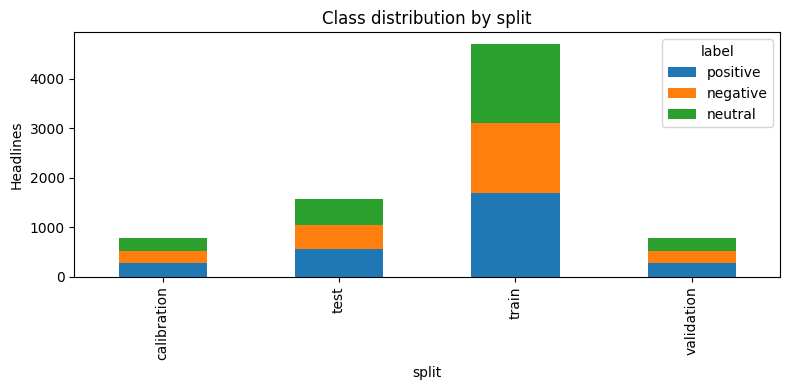

In [ ]:
csv_path = Path(DATA_CSV_OVERRIDE) if DATA_CSV_OVERRIDE else download_sentfin(DATA_DIR)
frame, data_audit = prepare_sentfin(csv_path)
frame = assign_duplicate_groups(frame, CFG.near_duplicate_similarity)
if QUICK_RUN:
    frame = frame.sample(n=min(1200, len(frame)), random_state=CFG.split_seed).reset_index(drop=True)
    data_audit["quick_run_sample_size"] = len(frame)

splits, split_summary = make_splits(frame, RUN_DIR / "splits", seed=CFG.split_seed)
RUN_DIR = initialize_run(CFG, splits, RUN_DIR, DEVICE)
save_json(RUN_DIR / "data_audit.json", data_audit)
save_json(RUN_DIR / "dataset_provenance.json", {
    "source": str(csv_path) if DATA_CSV_OVERRIDE else DATA_URL,
    "sha256": hashlib.sha256(csv_path.read_bytes()).hexdigest(),
    "pinned_commit": None if DATA_CSV_OVERRIDE else DATA_COMMIT,
})
display(pd.Series(data_audit, name="data audit").to_frame())
display(split_summary)

group_sets = {name: set(part.group_id) for name, part in splits.items()}
for a in group_sets:
    for b in group_sets:
        if a != b:
            assert group_sets[a].isdisjoint(group_sets[b])
print("Duplicate-group overlap across splits: 0")
split_summary[["positive", "negative", "neutral"]].plot.bar(stacked=True, figsize=(8, 4), ylabel="Headlines", title="Class distribution by split")
plt.tight_layout()
plt.savefig(RUN_DIR / "split_distribution.png", dpi=160)
plt.show()

## 3. Fine-tune the full FinBERT teacher

Train the **whole model** using only training examples. Keep the epoch with the highest **validation macro-F1**. Calibration and test labels are not used here.

The optimizer is AdamW with warmup, linear learning-rate decay, and gradient clipping. The teacher is saved before exit training begins.

In [ ]:
tokenizer, teacher = load_teacher(CFG, DEVICE)
tokenizer.save_pretrained(RUN_DIR / "tokenizer")
loaders = {
    name: make_loader(part, tokenizer, CFG, shuffle=(name == "train"))
    for name, part in splits.items()
}
teacher, teacher_history = train_stage(
    teacher, loaders["train"], loaders["validation"], CFG, RUN_DIR, DEVICE, stage="teacher",
)
display(teacher_history)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

... (3 outputs left out)

{'epoch': 2, 'train_loss': 0.2500046864658797, 'validation_macro_f1': 0.8802398596101376}


teacher 3/3:   0%|          | 0/294 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.14437864751231913, 'validation_macro_f1': 0.8730554219652317}


,epoch,train_loss,validation_macro_f1
0,1,0.496083,0.851967
1,2,0.250005,0.880240
2,3,0.144379,0.873055


## 4. Train the intermediate exit heads

Freeze the fine-tuned teacher's weights. Only the new pooler/classifier at layers **2, 4, and 8** can change. Each head learns from both:

- **Cross-entropy:** match the gold sentiment label.
- **Knowledge distillation:** imitate the full teacher's probability distribution.

The loss gives these signals equal weight and averages across the three exits. Distillation uses temperature 2. This is different from the calibration temperatures fitted next.

Choose the heads' best epoch using the average validation macro-F1 across exits. Training needs all layers to obtain the teacher's signal. **Dynamic inference actually returns early and skips remaining layers.**

In [ ]:
early_exit = EarlyExitFinBERT(teacher, exit_layers=CFG.exit_layers).to(DEVICE)
early_exit, heads_history = train_stage(
    early_exit, loaders["train"], loaders["validation"], CFG, RUN_DIR, DEVICE, stage="heads",
)
display(heads_history)
assert all(not parameter.requires_grad for parameter in early_exit.backbone.parameters())
print("Frozen backbone; trained intermediate heads:", early_exit.exit_layers)

heads 1/5:   0%|          | 0/294 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 1.581741570615444, 'validation_macro_f1': 0.5090611627989947}


heads 2/5:   0%|          | 0/294 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.2815002594269862, 'validation_macro_f1': 0.5769621817089211}


heads 3/5:   0%|          | 0/294 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.1484268277275318, 'validation_macro_f1': 0.6388190390383484}


... (2 outputs left out)

heads 5/5:   0%|          | 0/294 [00:00<?, ?it/s]

{'epoch': 5, 'train_loss': 1.0570624861992945, 'validation_macro_f1': 0.6536658183253707}


,epoch,train_loss,validation_macro_f1
0,1,1.581742,0.509061
1,2,1.281500,0.576962
2,3,1.148427,0.638819
3,4,1.085052,0.652359
4,5,1.057062,0.653666


Frozen backbone; trained intermediate heads: (2, 4, 8)


## 5. Calibrate each head's confidence

On the **calibration split only**, fit a positive temperature for each exit and the final head by minimizing negative log-likelihood (NLL). Record NLL, expected calibration error (ECE), and Brier score before and after.

The exit rule uses **maximum calibrated softmax probability**, not entropy. Temperature scaling rescales confidence; it does not guarantee correctness or fix distribution shift.

`all_logits()` runs all layers for quality scoring. Cached logits are never used to claim faster inference. The fitted temperatures are also applied during real dynamic inference.

,layer,temperature,before_nll,before_ece,before_brier,after_nll,after_ece,after_brier
0,2,0.814184,0.900939,0.045693,0.537741,0.895780,0.022738,0.535130
1,4,1.009660,0.851349,0.056402,0.506279,0.851334,0.052674,0.506274
2,8,1.074487,0.562025,0.019274,0.318384,0.560885,0.015503,0.318429
3,12,1.438868,0.390718,0.064307,0.199704,0.352043,0.044106,0.188806


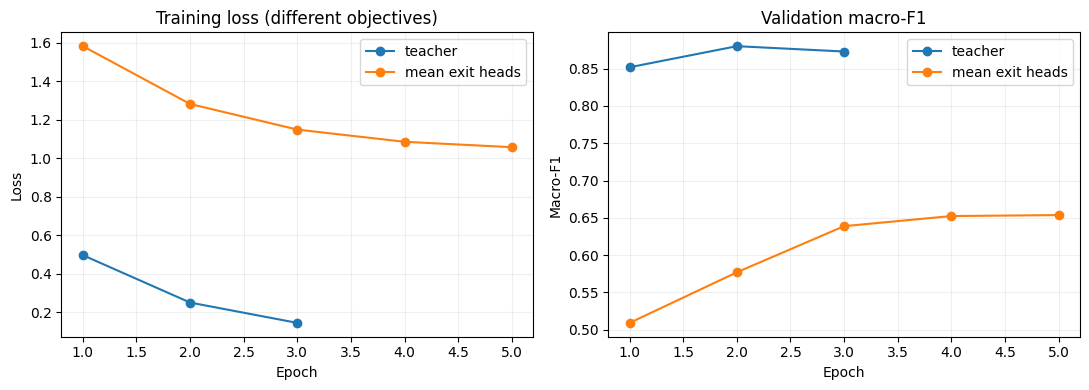

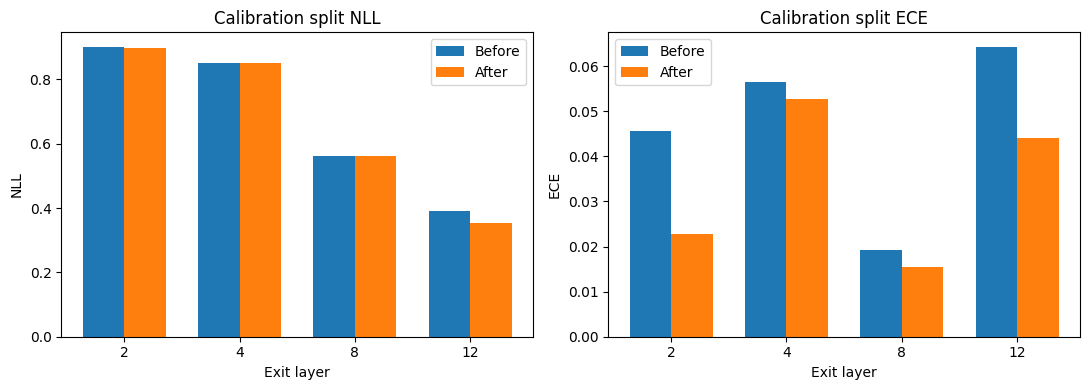

In [ ]:
calibration_logits, calibration_labels = collect_exit_logits(early_exit, loaders["calibration"], DEVICE)
temperatures, calibration_table = calibrate_heads(calibration_logits, calibration_labels)
early_exit.set_temperatures(temperatures)
save_json(RUN_DIR / "temperatures.json", temperatures)
calibration_table.to_csv(RUN_DIR / "calibration_metrics.csv", index=False)
display(calibration_table)
plot_training_and_calibration(teacher_history, heads_history, calibration_table, RUN_DIR)
plt.show()

## 6. Select the policy on validation data

Compare full FinBERT, static exits at layers 2/4/8, and a predefined grid of dynamic confidence thresholds. Compute quality on the full validation split and time real inference on the same validation subset for every policy.

| Timing mode | Included |
|---|---|
| Model-only | Model, exit checks, GPU synchronization, and prediction; input already on the GPU |
| End-to-end (e2e) | Tokenization, device transfer, model, exit checks, synchronization, and prediction |

Warmup, model loading, news feeds, network transport, queues, and trading execution are excluded. Policies run in randomized order on the same FP32 runtime. The full baseline does not execute intermediate classifiers.

Among policies within the validation F1 budget, choose the one with the lowest measured e2e median latency. **The full model or a static exit may win. Do not reselect after seeing test results.**

latency model 1/1:   0%|          | 0/128 [00:00<?, ?it/s]

latency e2e 1/1:   0%|          | 0/128 [00:00<?, ?it/s]

Selected on validation only: {'name': 'full', 'kind': 'full', 'layer': None, 'threshold': None}


,name,macro_f1,f1_drop_pp,mean_layers,e2e_p50_ms,e2e_p95_ms,e2e_p50_speedup
1,static_2,0.577382,30.285778,2.000000,2.303991,4.836938,3.973521
4,dynamic_0.5,0.652000,22.823996,3.452926,2.854683,9.774629,3.206997
2,static_4,0.603125,27.711480,4.000000,3.711513,6.676027,2.466637
5,dynamic_0.6,0.757653,12.258637,5.374046,4.864854,10.999660,1.881856
3,static_8,0.780490,9.974954,8.000000,6.383592,10.437802,1.434139
6,dynamic_0.7,0.811666,6.857395,7.330789,6.871140,12.948737,1.332378
7,dynamic_0.8,0.866867,1.337258,8.882952,7.424546,12.646539,1.233066
0,full,0.880240,0.000000,12.000000,9.154958,14.687332,1.000000
8,dynamic_0.85,0.874265,0.597438,9.567430,9.341182,13.105460,0.980064
9,dynamic_0.9,0.880649,-0.040871,10.229008,9.540575,12.410401,0.959581


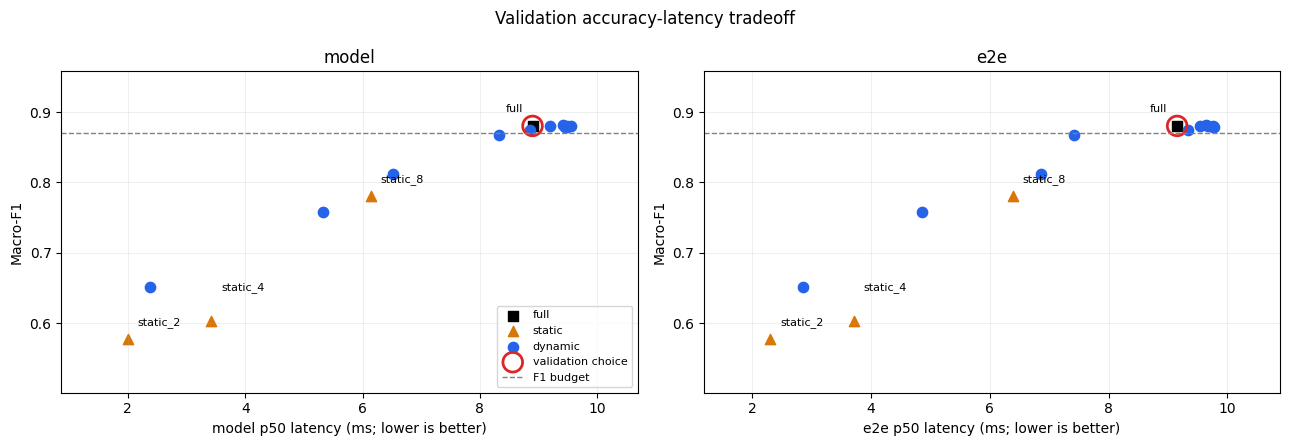

In [ ]:
policies = make_policies(early_exit.exit_layers, CFG.thresholds)
validation_raw, validation_labels = collect_exit_logits(early_exit, loaders["validation"], DEVICE)
validation_calibrated = apply_temperatures(validation_raw, temperatures)
validation_quality, validation_predictions, validation_depths = score_policies(
    validation_calibrated, validation_labels, policies, early_exit.exit_layers,
)
validation_latency, validation_timing_raw = measure_latency(
    early_exit, tokenizer, splits["validation"], policies, CFG,
    samples=CFG.validation_latency_samples, repeats=1,
)
validation_table = add_comparison_columns(validation_quality.merge(validation_latency, on="name", validate="one_to_one"))
chosen_policy = select_policy(validation_table, CFG.f1_drop_budget)
validation_table.to_csv(RUN_DIR / "validation_sweep.csv", index=False)
validation_timing_raw.to_csv(RUN_DIR / "validation_timing_raw.csv", index=False)
save_json(RUN_DIR / "selected_policy.json", chosen_policy)
save_json(RUN_DIR / "predeclared_policy_grid.json", policies)
print("Selected on validation only:", chosen_policy)
display(validation_table[["name", "macro_f1", "f1_drop_pp", "mean_layers", "e2e_p50_ms", "e2e_p95_ms", "e2e_p50_speedup"]].sort_values("e2e_p50_ms"))
plot_tradeoff(validation_table, "Validation accuracy-latency tradeoff", RUN_DIR / "validation_tradeoff.png", chosen_name=chosen_policy["name"], budget=CFG.f1_drop_budget)
plt.show()

## 7. Evaluate the frozen policies on the held-out test set

The dynamic candidate is fixed using validation only. If no dynamic candidate meets the budget, report the best-quality validation candidate as a diagnostic; keep the deployment choice from step 6.

Evaluate full/static/fixed-dynamic quality on **every test example**. Measure latency on the same random subset for all policies. `n_quality` counts quality examples; `n_latency_unique` counts different timed headlines; repeats are not new independent headlines.

The paired bootstrap resamples duplicate groups to estimate uncertainty in the F1 difference. Its interval is conditional on this trained model and does not include training-seed variability. p99 from 512 unique headlines is exploratory.

latency model 1/2:   0%|          | 0/512 [00:00<?, ?it/s]

latency model 2/2:   0%|          | 0/512 [00:00<?, ?it/s]

latency e2e 1/2:   0%|          | 0/512 [00:00<?, ?it/s]

latency e2e 2/2:   0%|          | 0/512 [00:00<?, ?it/s]

,name,selected_on_validation,accuracy,macro_f1,f1_drop_pp,mean_layers,model_p50_ms,e2e_p50_ms,e2e_p95_ms,e2e_p99_ms,e2e_p50_speedup,n_quality,n_latency_unique,n_latency_per_mode,f1_drop_ci_low,f1_drop_ci_high
0,full,True,0.879212,0.878955,0.000000,12.000000,8.930184,9.230459,15.241331,16.886842,1.000000,1573,512,1024,0.000000,0.000000
1,static_2,False,0.571519,0.561508,31.744717,2.000000,2.010048,2.317489,4.514532,5.902289,3.982956,1573,512,1024,0.293445,0.345728
2,static_4,False,0.614749,0.606744,27.221141,4.000000,3.391500,3.681533,6.799279,8.304935,2.507233,1573,512,1024,0.246522,0.298916
3,static_8,False,0.787667,0.787474,9.148079,8.000000,6.097713,6.430765,10.620692,12.465952,1.435359,1573,512,1024,0.071811,0.109199
4,dynamic_0.85,False,0.874126,0.873904,0.505109,9.602035,9.096739,9.358655,14.375715,17.025183,0.986302,1573,512,1024,-0.001399,0.012204


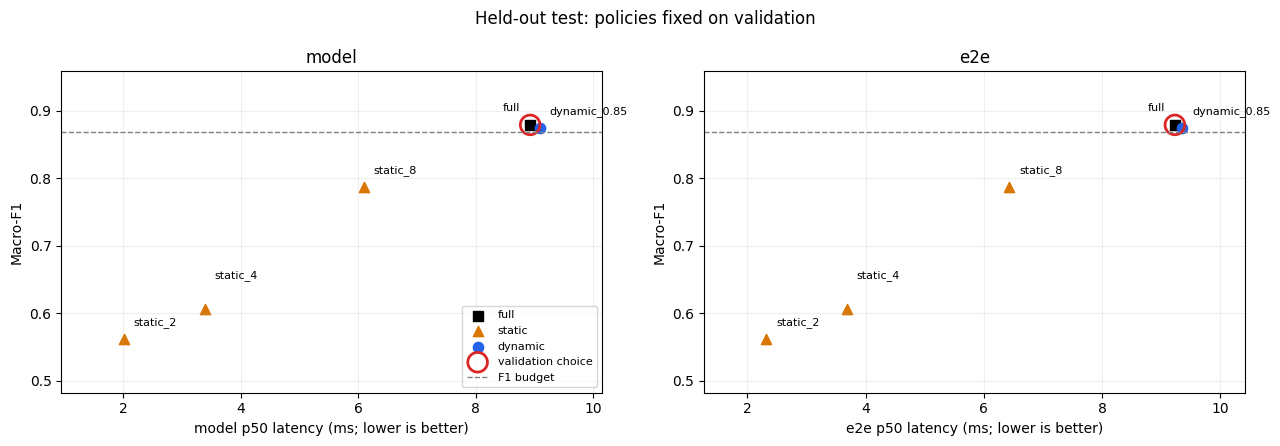

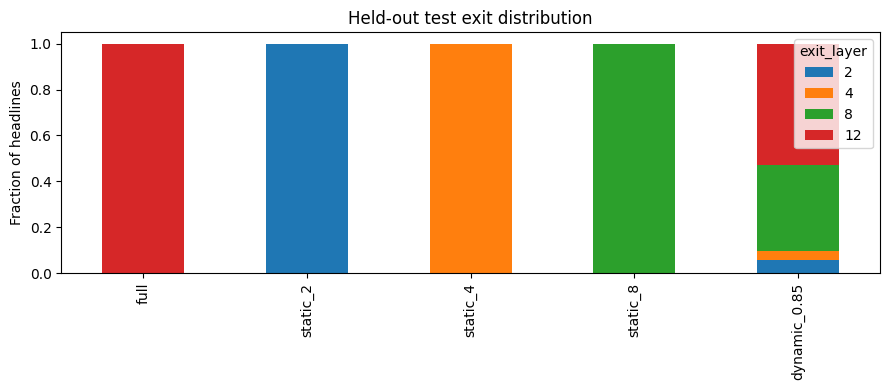

In [ ]:
dynamic_validation = validation_table[validation_table.kind == "dynamic"].copy()
full_validation_f1 = validation_table.loc[validation_table.name == "full", "macro_f1"].iloc[0]
feasible_dynamic = dynamic_validation[dynamic_validation.macro_f1 >= full_validation_f1 - CFG.f1_drop_budget]
if len(feasible_dynamic):
    candidate_name = feasible_dynamic.sort_values("e2e_p50_ms").iloc[0]["name"]
    dynamic_candidate_met_validation_budget = True
else:
    candidate_name = dynamic_validation.sort_values(["macro_f1", "e2e_p50_ms"], ascending=[False, True]).iloc[0]["name"]
    dynamic_candidate_met_validation_budget = False
test_policies = [p for p in policies if p["kind"] != "dynamic" or p["name"] == candidate_name]
save_json(RUN_DIR / "fixed_test_policies.json", {
    "policies": test_policies, "selected_policy": chosen_policy,
    "dynamic_candidate_met_validation_budget": dynamic_candidate_met_validation_budget,
})

test_raw, test_labels = collect_exit_logits(early_exit, loaders["test"], DEVICE)
test_calibrated = apply_temperatures(test_raw, temperatures)
test_quality, test_predictions, test_depths = score_policies(test_calibrated, test_labels, test_policies, early_exit.exit_layers)
test_latency, test_timing_raw = measure_latency(
    early_exit, tokenizer, splits["test"], test_policies, CFG, samples=CFG.test_latency_samples,
)
test_table = add_comparison_columns(test_quality.merge(test_latency, on="name", validate="one_to_one"))
intervals = bootstrap_f1_drops(
    test_labels.numpy(), test_predictions, groups=splits["test"].group_id.to_numpy(),
    repetitions=CFG.bootstrap_samples, seed=CFG.seed,
)
test_table = test_table.merge(intervals, on="name", validate="one_to_one")
test_table["selected_on_validation"] = test_table.name == chosen_policy["name"]
test_timing_raw.to_csv(RUN_DIR / "test_timing_raw.csv", index=False)
exit_distribution = save_test_reports(test_table, test_labels.numpy(), test_predictions, test_depths, splits["test"], RUN_DIR)
display(test_table[[
    "name", "selected_on_validation", "accuracy", "macro_f1", "f1_drop_pp", "mean_layers",
    "model_p50_ms", "e2e_p50_ms", "e2e_p95_ms", "e2e_p99_ms", "e2e_p50_speedup",
    "n_quality", "n_latency_unique", "n_latency_per_mode", "f1_drop_ci_low", "f1_drop_ci_high",
]])
plot_tradeoff(test_table, "Held-out test: policies fixed on validation", RUN_DIR / "test_tradeoff.png", chosen_name=chosen_policy["name"], budget=CFG.f1_drop_budget)
plt.show()
exit_distribution.T.plot.bar(stacked=True, figsize=(9, 4), ylabel="Fraction of headlines", title="Held-out test exit distribution")
plt.tight_layout()
plt.savefig(RUN_DIR / "test_exit_distribution.png", dpi=160)
plt.show()

## 8. Save, reload, and check a prediction

Save the trained heads, calibration temperatures, tokenizer, backbone, and chosen policy. Reload on CPU so a second full model is not placed on the GPU.

The check confirms that forcing the dynamic model through all layers matches the original full-model path. The demonstration headline is illustrative and is not an extra benchmark.

In [ ]:
deployment_dir = RUN_DIR / "deployment"
if not deployment_dir.exists():
    early_exit.save(deployment_dir, tokenizer, max_length=CFG.max_length)
save_json(deployment_dir / "selected_policy.json", chosen_policy)

# Reload on CPU to verify serialization without duplicating GPU memory use.
reloaded, reloaded_tokenizer, reloaded_max_length = EarlyExitFinBERT.load(deployment_dir, device="cpu")
example_text = "Company reports higher profits but warns of weaker demand."
cpu_tokens = reloaded_tokenizer(example_text, return_tensors="pt", truncation=True, max_length=reloaded_max_length)
with torch.inference_mode():
    original_full = reloaded.backbone(**cpu_tokens).logits / reloaded.temperatures[reloaded.depth]
    forced_full, _ = reloaded.predict_one(**cpu_tokens, threshold=math.inf)
    torch.testing.assert_close(original_full, forced_full, atol=1e-5, rtol=1e-4)
    demo_logits, demo_depth = infer_policy(reloaded, cpu_tokens, chosen_policy)
    demo_probs = demo_logits.softmax(-1)[0]
    demo = {
        "text": example_text, "policy": chosen_policy["name"], "exit_layer": demo_depth,
        "prediction": ID2LABEL[demo_probs.argmax().item()],
        "probabilities": {ID2LABEL[i]: float(p) for i, p in enumerate(demo_probs)},
    }
display(demo)
print("Local checkpoint reload and full-path equivalence: passed")
del reloaded

{'text': 'Company reports higher profits but warns of weaker demand.',
 'policy': 'full',
 'exit_layer': 12,
 'prediction': 'positive',
 'probabilities': {'positive': 0.6308736801147461,
  'negative': 0.3093632161617279,
  'neutral': 0.059763092547655106}}

Local checkpoint reload and full-path equivalence: passed


## 9. Export the results

Create two downloads:

- **Meeting results:** metrics, plots, split/audit records, raw timing, code, and experiment settings, without model weights.
- **Full checkpoint bundle:** everything needed to reload the model; several hundred MB.

Download the small meeting bundle before ending the Colab runtime. Local Colab storage is temporary. Archive generation and checkpoint loading are excluded from latency measurements.

In [ ]:
import zipfile

for source_name in ["early_exit_finbert.py", "sentfin_pipeline.py"]:
    shutil.copyfile(Path.cwd() / source_name, RUN_DIR / source_name)
save_json(RUN_DIR / "completion.json", {
    "status": "complete", "quick_run": QUICK_RUN, "selected_policy": chosen_policy,
    "test_metrics_used_for_selection": False,
    "inference_precision": "float32", "attention": "eager",
    "limitations": [
        "single-entity headlines only; no chronological or event-isolated holdout",
        "one training seed per run; group bootstrap is conditional on this model",
        "p99 timing is exploratory with the default sample size",
        "not a benchmark against an optimized compiled full-model serving engine",
        "sentiment classification does not establish trading profitability",
    ],
})
bundle_path = RUN_DIR.parent / f"{RUN_DIR.name}_results.zip"
with zipfile.ZipFile(bundle_path, "w", compression=zipfile.ZIP_STORED) as bundle:
    for path in sorted(RUN_DIR.rglob("*")):
        # deployment/backbone includes the same best teacher; omit the duplicate copy.
        if path.is_file() and "teacher" not in path.relative_to(RUN_DIR).parts and "tokenizer" not in path.relative_to(RUN_DIR).parts:
            bundle.write(path, arcname=str(path.relative_to(RUN_DIR)))
print(f"Results: {RUN_DIR}")
print(f"Bundle: {bundle_path} ({bundle_path.stat().st_size / 1e6:.1f} MB)")
display(FileLink(str(bundle_path)))

# Set True to download the large checkpoint bundle directly from Colab.
DOWNLOAD_RESULTS = False
if DOWNLOAD_RESULTS:
    from google.colab import files
    files.download(str(bundle_path))

# Small, portable evidence bundle for the meeting (no model weights).
meeting_path = RUN_DIR.parent / f"{RUN_DIR.name}_meeting_results.zip"
with zipfile.ZipFile(meeting_path, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(RUN_DIR.rglob("*")):
        relative = path.relative_to(RUN_DIR)
        if path.is_file() and not set(relative.parts) & {"deployment", "teacher", "tokenizer"} and path.suffix not in {".pt", ".bin", ".safetensors"}:
            bundle.write(path, arcname=str(relative))
print(f"Meeting bundle: {meeting_path} ({meeting_path.stat().st_size / 1e6:.2f} MB)")
display(FileLink(str(meeting_path)))
print("MEETING_RESULTS_JSON_BEGIN")
print(test_table.to_json(orient="records", indent=2))
print("MEETING_RESULTS_JSON_END")


Results: /content/sentfin_early_exit/sentfin_full_seed42_20261105
Bundle: /content/sentfin_early_exit/sentfin_full_seed42_20261105_results.zip (457.2 MB)


/content/sentfin_early_exit/sentfin_full_seed42_20261105_results.zip

Meeting bundle: /content/sentfin_early_exit/sentfin_full_seed42_20261105_meeting_results.zip (1.24 MB)


/content/sentfin_early_exit/sentfin_full_seed42_20261105_meeting_results.zip

MEETING_RESULTS_JSON_BEGIN
[
  {
    "name":"full",
    "kind":"full",
    "layer":null,
    "threshold":null,
    "accuracy":0.8792116974,
    "macro_f1":0.8789551692,
    "nll":0.3435555696,
    "ece":0.0418532173,
    "brier":0.1827086061,
    "n_quality":1573,
    "mean_layers":12.0,
    "early_exit_fraction":0.0,
    "disagreement_with_full":0.0,
    "n_latency_unique":512,
    "n_latency_per_mode":1024,
    "model_p50_ms":8.9301835,
    "model_p95_ms":14.52977365,
    "model_p99_ms":17.29765949,
    "e2e_p50_ms":9.2304585,
    "e2e_p95_ms":15.2413307,
    "e2e_p99_ms":16.88684178,
    "f1_drop_pp":0.0,
    "e2e_p50_speedup":1.0,
    "model_p50_speedup":1.0,
    "f1_drop_ci_low":0.0,
    "f1_drop_ci_high":0.0,
    "selected_on_validation":true
  },
  {
    "name":"static_2",
    "kind":"static",
    "layer":2.0,
    "threshold":null,
    "accuracy":0.5715193897,
    "macro_f1":0.5615079969,
    "nll":0.8975411654,
    "ece":0.0316769428,
    "brier":0.5377759337,
    "n_quality":1

## How to discuss the results

1. State the held-out macro-F1 and accuracy of the full model.
2. Compare the fixed dynamic candidate's quality and p50/p95 latency.
3. Check the exit distribution: how often did examples actually stop before layer 12?
4. Compare static exits. Do dynamic decisions add value beyond using one smaller fixed depth?
5. Report the selected policy, the quality budget, hardware, seed, sample counts, and limitations.

Fewer layers do not automatically mean lower wall-clock latency. Python routing and confidence checks add overhead. All policies here use the same FP32 eager runtime; this is not a comparison against an optimized compiled serving engine. Sentiment accuracy does not establish trading profitability.

SEntFiN is a single-entity financial-headline experiment with no chronological holdout. Financial PhraseBank and small-batch serving from the broader proposal are not implemented in this run. The exit rule is calibrated maximum probability, so the proposal's entropy wording should be reconciled before reporting a final method.

### References

- [SEntFiN data](https://github.com/pyRis/SEntFiN) and [paper](https://arxiv.org/html/2305.12257v1)
- [FinBERT model card](https://huggingface.co/ProsusAI/finbert)
- [DeeBERT](https://aclanthology.org/2020.acl-main.204/) and [FastBERT](https://aclanthology.org/2020.acl-main.537/)
- [Temperature scaling](https://proceedings.mlr.press/v70/guo17a.html)
- [Pinned BERT implementation](https://github.com/huggingface/transformers/blob/v4.48.3/src/transformers/models/bert/modeling_bert.py)

This is a research implementation inspired by CE/distillation and early exiting, not an exact reproduction of DeeBERT or FastBERT.

In [ ]:
# Meeting summary: read completed results without rerunning training.
summary = pd.read_csv(RUN_DIR / "test_comparison.csv")
dynamic_result = summary.loc[summary.kind == "dynamic"].iloc[0]
print(f"FULL EXPERIMENT COMPLETE | {torch.cuda.get_device_name(0)} | seed {CFG.seed}")
print(f"{sum(map(len, splits.values())):,} cleaned headlines | {len(splits['test']):,} test")
print(summary[["name", "macro_f1", "e2e_p50_ms", "e2e_p95_ms", "mean_layers"]].round(4).to_string(index=False))
print("Validation selected:", chosen_policy["name"])
print(f"Dynamic threshold {dynamic_result.threshold:g}: {100 * dynamic_result.early_exit_fraction:.1f}% early exits")
print(f"F1 loss: {dynamic_result.f1_drop_pp:.2f} percentage points | median speedup: {dynamic_result.e2e_p50_speedup:.3f}x")
print(f"Latency: {CFG.test_latency_samples} distinct test headlines, {CFG.timing_repeats} repeats per mode; FP32, batch 1")

FULL EXPERIMENT COMPLETE | Tesla T4 | seed 42
7,845 cleaned headlines | 1,573 test
        name  macro_f1  e2e_p50_ms  e2e_p95_ms  mean_layers
        full    0.8790      9.2305     15.2413       12.000
    static_2    0.5615      2.3175      4.5145        2.000
    static_4    0.6067      3.6815      6.7993        4.000
    static_8    0.7875      6.4308     10.6207        8.000
dynamic_0.85    0.8739      9.3587     14.3757        9.602
Validation selected: full
Dynamic threshold 0.85: 47.3% early exits
F1 loss: 0.51 percentage points | median speedup: 0.986x
Latency: 512 distinct test headlines, 2 repeats per mode; FP32, batch 1


In [ ]:
# Diagnose overhead and screen exit locations using VALIDATION only.
from sentfin_pipeline import synchronize
from torch.profiler import profile, ProfilerActivity, record_function
OPT_DIR = RUN_DIR / "overhead_optimization"
OPT_DIR.mkdir(exist_ok=True)
EXIT_SETS = [(8,), (4, 8), (2, 8), (2, 4, 8)]
THRESHOLD_GRID = tuple(round(x, 2) for x in np.arange(0.50, 1.00, 0.01))
save_json(OPT_DIR / "predeclared_search.json", {"exit_sets": EXIT_SETS, "thresholds": THRESHOLD_GRID, "f1_budget": 0.01, "selection_split": "validation"})
quality_parts = []
for exit_set in EXIT_SETS:
    candidates = [{"name": "exit" + "_".join(map(str, exit_set)) + f"_t{threshold:g}", "kind": "dynamic", "layer": None, "threshold": threshold} for threshold in THRESHOLD_GRID]
    quality, _, _ = score_policies(validation_calibrated, validation_labels, candidates, exit_set)
    quality["exit_layers"] = [exit_set] * len(quality)
    quality["f1_drop_pp"] = 100 * (full_validation_f1 - quality.macro_f1)
    quality_parts.append(quality)
validation_exit_search = pd.concat(quality_parts, ignore_index=True)
validation_exit_search.to_csv(OPT_DIR / "validation_exit_search.csv", index=False)
eligible = validation_exit_search[validation_exit_search.f1_drop_pp <= 1.0].sort_values(["mean_layers", "macro_f1"], ascending=[True, False])
print("Best validation candidates within the 1-point F1 budget:")
print(eligible.groupby("exit_layers", sort=False).head(2)[["name", "macro_f1", "f1_drop_pp", "mean_layers", "early_exit_fraction"]].to_string(index=False))
profile_tokens = [dict(tokenizer(text, return_tensors="pt", truncation=True, max_length=CFG.max_length).to(DEVICE)) for text in splits["validation"].text.iloc[:8]]
for tokens in profile_tokens:
    infer_policy(early_exit, tokens, {"kind": "dynamic", "threshold": 0.85})
synchronize(DEVICE)
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as inference_profile:
    for tokens in profile_tokens:
        with record_function("original_dynamic_prediction"):
            logits, _ = early_exit.predict_one(**tokens, threshold=0.85)
            logits.argmax(-1).item()
    synchronize(DEVICE)
profile_table = pd.DataFrame([{"operation": event.key, "calls": event.count, "self_cpu_us": event.self_cpu_time_total, "device_us": event.device_time_total} for event in inference_profile.key_averages()])
profile_table.to_csv(OPT_DIR / "original_profile.csv", index=False)
inference_profile.export_chrome_trace(str(OPT_DIR / "original_profile_trace.json"))
print("Profiler events for confidence checks and synchronization:")
print(profile_table[profile_table.operation.str.contains("item|local_scalar|Synchronize|original_dynamic_prediction", case=False)].to_string(index=False))


Best validation candidates within the 1-point F1 budget:
           name  macro_f1  f1_drop_pp  mean_layers  early_exit_fraction
  exit2_8_t0.78  0.872207    0.803325     9.038168             0.587786
  exit2_8_t0.79  0.872107    0.813251     9.101781             0.573791
exit2_4_8_t0.82  0.870779    0.946039     9.193384             0.536896
exit2_4_8_t0.83  0.870779    0.946039     9.292621             0.520356
  exit4_8_t0.81  0.870474    0.976594     9.358779             0.545802
  exit4_8_t0.82  0.871768    0.847222     9.475827             0.530534
    exit8_t0.78  0.873048    0.719236     9.709924             0.572519
    exit8_t0.79  0.874312    0.592819     9.760815             0.559796


/usr/local/lib/python3.13/dist-packages/torch/profiler/profiler.py:224: UserWarning: Warning: Profiler clears events at the end of each cycle.Only events from the current cycle will be reported.To keep events across cycles, set acc_events=True.
  _warn_once(


Profiler events for confidence checks and synchronization:
                  operation  calls  self_cpu_us  device_us
original_dynamic_prediction      8    62568.023  34063.267
original_dynamic_prediction      8        0.000 177693.422
                 aten::item     27      109.892     44.768
  aten::_local_scalar_dense     27     3143.706     44.768
      cudaStreamSynchronize     27      240.732      0.000
      cudaDeviceSynchronize      2       25.799      0.000


In [ ]:
%%writefile fast_early_exit.py
"""Readable inference optimization for a trained early-exit FinBERT.

No weights, temperatures, precision, or attention implementation are changed.
The faster route checks one useful exit and copies confidence + label together.
"""

from dataclasses import dataclass
import math
import time

import numpy as np
import pandas as pd
import torch


@dataclass(frozen=True)
class Prediction:
    label: int
    exit_layer: int


class SingleExitRunner:
    """Check one trained classifier, then either return or finish the model.

    This runner deliberately supports batch size 1, just like the original.
    A batch of unrelated requests would need a different routing design.
    """

    def __init__(self, model, exit_layer=8):
        if exit_layer not in model.exit_layers or model.training_steps == 0:
            raise ValueError("Choose a trained intermediate exit.")
        self.model = model.eval()
        self.exit_layer = exit_layer
        layers = tuple(model.backbone.bert.encoder.layer)
        self.prefix_layers = layers[:exit_layer]
        self.remaining_layers = layers[exit_layer:]

    @torch.inference_mode()
    def predict(self, tokens, threshold):
        """Return the predicted class and actual number of executed layers."""
        if not 0 <= threshold <= 1:
            raise ValueError("Confidence threshold must be between zero and one.")
        input_ids = tokens["input_ids"]
        if input_ids.ndim != 2 or input_ids.shape[0] != 1:
            raise ValueError("This inference path accepts one headline at a time.")

        bert = self.model.backbone.bert
        attention_mask = tokens.get("attention_mask")
        if attention_mask is None:
            attention_mask = torch.ones_like(input_ids)
        mask = bert.get_extended_attention_mask(attention_mask, input_ids.shape)
        hidden = bert.embeddings(
            input_ids=input_ids, token_type_ids=tokens.get("token_type_ids")
        )

        # Run only the first section. Do not compute the later layers yet.
        for layer in self.prefix_layers:
            hidden = layer(hidden, attention_mask=mask)[0]

        # The same trained head and temperature as the original experiment.
        logits = self.model.heads[str(self.exit_layer)](hidden)
        logits = logits / self.model.temperatures[self.exit_layer]
        confidence, label = logits.softmax(dim=-1).max(dim=-1)

        # Copy these two tiny values together. If we exit now, the label is
        # already available on the CPU; no second argmax/synchronization is needed.
        decision = torch.stack((confidence, label.to(confidence.dtype)), dim=-1)
        confidence_value, label_value = decision.cpu().tolist()[0]
        if confidence_value >= threshold:
            return Prediction(int(label_value), self.exit_layer)

        # Uncertain headline: continue from the existing layer-8 hidden state.
        for layer in self.remaining_layers:
            hidden = layer(hidden, attention_mask=mask)[0]
        pooled = bert.pooler(hidden)
        logits = self.model.backbone.classifier(self.model.backbone.dropout(pooled))
        logits = logits / self.model.temperatures[self.model.depth]
        return Prediction(int(logits.argmax(dim=-1).item()), self.model.depth)


@torch.inference_mode()
def predict_policy(model, runner, tokens, policy):
    """Give all implementations the same measured output: a class and depth."""
    if policy["kind"] == "full":
        logits = model.backbone(**tokens).logits
        logits = logits / model.temperatures[model.depth]
        return Prediction(int(logits.argmax(dim=-1).item()), model.depth)
    if policy["kind"] == "original":
        logits, depth = model.predict_one(**tokens, threshold=policy["threshold"])
        return Prediction(int(logits.argmax(dim=-1).item()), depth)
    if policy["kind"] == "single_exit":
        return runner.predict(tokens, policy["threshold"])
    raise ValueError(f"Unknown policy: {policy['kind']}")


def encode_headline(text, tokenizer, device, max_length):
    tokens = tokenizer(text, truncation=True, max_length=max_length, return_tensors="pt")
    return {name: value.to(device) for name, value in tokens.items()}


@torch.inference_mode()
def benchmark_policies(model, runner, tokenizer, frame, policies, *,
                       samples=512, repeats=3, seed=1743, max_length=96, warmup=10):
    """Paired, randomized real inference; no cached logits inside the timers.

    Model-only starts with GPU-resident tokens. End-to-end also includes the
    tokenizer and input transfer. Both include confidence checks and CPU labels.
    Every policy sees the same examples, repeats, precision, and hardware.
    """
    device = next(model.parameters()).device
    if device.type != "cuda":
        raise ValueError("Run the timing comparison on the Colab GPU.")
    if samples < 1 or repeats < 1:
        raise ValueError("Samples and repeats must be positive.")
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(frame), min(samples, len(frame)), replace=False)
    selected = frame.iloc[indices]
    texts = selected.text.tolist()
    row_ids = selected.row_id.astype(int).tolist()
    resident_tokens = [encode_headline(text, tokenizer, device, max_length) for text in texts]

    for policy in policies:
        for index in range(warmup):
            predict_policy(model, runner, resident_tokens[index % len(texts)], policy)
    torch.cuda.synchronize(device)

    records = []
    for mode in ("model", "e2e"):
        for repeat in range(repeats):
            for index in rng.permutation(len(texts)):
                for policy_index in rng.permutation(len(policies)):
                    policy = policies[policy_index]
                    torch.cuda.synchronize(device)
                    started = time.perf_counter_ns()
                    tokens = resident_tokens[index] if mode == "model" else encode_headline(
                        texts[index], tokenizer, device, max_length
                    )
                    prediction = predict_policy(model, runner, tokens, policy)
                    torch.cuda.synchronize(device)
                    milliseconds = (time.perf_counter_ns() - started) / 1e6
                    records.append({
                        "name": policy["name"], "mode": mode, "repeat": repeat,
                        "row_id": row_ids[index], "ms": milliseconds,
                        "prediction": prediction.label, "exit_layer": prediction.exit_layer,
                    })

    raw = pd.DataFrame(records)
    rows = []
    for policy in policies:
        row = {**policy, "n_latency_unique": len(texts),
               "n_latency_per_mode": len(texts) * repeats}
        for mode in ("model", "e2e"):
            values = raw[(raw.name == policy["name"]) & (raw["mode"] == mode)].ms
            row[f"{mode}_mean_ms"] = float(values.mean())
            for percentile in (50, 95, 99):
                row[f"{mode}_p{percentile}_ms"] = float(np.percentile(values, percentile))
        rows.append(row)
    return pd.DataFrame(rows), raw


@torch.inference_mode()
def forced_full_ablation(model, tokens, *, check_layers=(), copy_decisions=False):
    """Diagnostic only: do the exit work but always run all 12 layers.

    Comparing zero checks, head work only, and head work plus CPU copies helps
    separate the cost of the extra heads from synchronization. This function
    is never used to select an accuracy policy or to claim layer skipping.
    """
    bert = model.backbone.bert
    ids = tokens["input_ids"]
    mask = bert.get_extended_attention_mask(tokens["attention_mask"], ids.shape)
    hidden = bert.embeddings(input_ids=ids, token_type_ids=tokens.get("token_type_ids"))
    for number, layer in enumerate(bert.encoder.layer, start=1):
        hidden = layer(hidden, attention_mask=mask)[0]
        if number in check_layers:
            logits = model.heads[str(number)](hidden) / model.temperatures[number]
            confidence = logits.softmax(dim=-1).amax()
            if copy_decisions:
                confidence.item()
    logits = model.backbone.classifier(model.backbone.dropout(bert.pooler(hidden)))
    return int(logits.argmax(dim=-1).item())


Writing fast_early_exit.py


In [ ]:
# Measure the benefit of fewer checks. Choose the final threshold on validation.
from fast_early_exit import SingleExitRunner, benchmark_policies, forced_full_ablation
import time
runner = SingleExitRunner(early_exit, exit_layer=8)
# Reserve a 0.25-point validation margin below the requested 1-point limit.
safe_single = validation_exit_search[(validation_exit_search.exit_layers == (8,)) & (validation_exit_search.f1_drop_pp <= 0.75) & (validation_exit_search.early_exit_fraction >= 0.50)].copy()
assert len(safe_single), "No single-exit policy meets the predeclared safety margin."
validation_policies = [
    {"name": "full", "kind": "full", "threshold": None},
    {"name": "original_dynamic_0.85", "kind": "original", "threshold": 0.85},
    {"name": "single8_same_0.85", "kind": "single_exit", "threshold": 0.85},
] + [{"name": f"single8_t{row.threshold:g}", "kind": "single_exit", "threshold": float(row.threshold)} for row in safe_single.itertuples()]
save_json(OPT_DIR / "validation_timing_protocol.json", {"policies": validation_policies, "samples": 128, "repeats": 3, "selection_margin_pp": 0.75, "near_tie_tolerance": 0.02})
validation_benchmark, validation_benchmark_raw = benchmark_policies(early_exit, runner, tokenizer, splits["validation"], validation_policies, samples=128, repeats=3, max_length=CFG.max_length)
validation_benchmark_raw.to_csv(OPT_DIR / "validation_benchmark_raw.csv", index=False)
validation_benchmark.to_csv(OPT_DIR / "validation_benchmark.csv", index=False)
quality_for_selection = safe_single.rename(columns={"name": "search_name"}).copy()
quality_for_selection["name"] = quality_for_selection.threshold.map(lambda x: f"single8_t{x:g}")
selection_table = validation_benchmark.merge(quality_for_selection[["name", "macro_f1", "f1_drop_pp", "early_exit_fraction"]], on="name")
# Treat medians within 2% as near ties, then prefer higher validation quality.
fastest_median = selection_table.e2e_p50_ms.min()
near_ties = selection_table[selection_table.e2e_p50_ms <= 1.02 * fastest_median]
best_row = near_ties.sort_values(["macro_f1", "e2e_p50_ms"], ascending=[False, True]).iloc[0]
optimized_policy = {"name": "optimized_single8", "kind": "single_exit", "threshold": float(best_row.threshold), "exit_layer": 8}
save_json(OPT_DIR / "frozen_optimized_policy.json", {"policy": optimized_policy, "validation_macro_f1": float(best_row.macro_f1), "validation_drop_pp": float(best_row.f1_drop_pp), "selection_used_test_labels": False})
selection_table.to_csv(OPT_DIR / "validation_selection.csv", index=False)
print("Validation-only threshold comparison:")
print(selection_table[["name", "macro_f1", "f1_drop_pp", "early_exit_fraction", "e2e_p50_ms", "e2e_mean_ms"]].to_string(index=False))
print("Frozen optimized policy:", optimized_policy)

# Forced-full ablation: every case executes all layers and predicts the same class.
ablation_cases = [("no_exit_work", (), False), ("three_heads_gpu_only", (2, 4, 8), False), ("three_heads_with_cpu_checks", (2, 4, 8), True), ("one_head_gpu_only", (8,), False), ("one_head_with_cpu_check", (8,), True)]
ablation_records = []
ablation_tokens = [dict(tokenizer(text, return_tensors="pt", truncation=True, max_length=CFG.max_length).to(DEVICE)) for text in splits["validation"].text.iloc[:32]]
for _, layers, copy_values in ablation_cases:
    for tokens in ablation_tokens[:3]:
        forced_full_ablation(early_exit, tokens, check_layers=layers, copy_decisions=copy_values)
ablation_rng = np.random.default_rng(42)
for repeat in range(3):
    for index in ablation_rng.permutation(len(ablation_tokens)):
        for case_index in ablation_rng.permutation(len(ablation_cases)):
            name, layers, copy_values = ablation_cases[case_index]
            synchronize(DEVICE)
            started = time.perf_counter_ns()
            prediction = forced_full_ablation(early_exit, ablation_tokens[index], check_layers=layers, copy_decisions=copy_values)
            synchronize(DEVICE)
            ablation_records.append({"name": name, "sample": int(index), "repeat": repeat, "ms": (time.perf_counter_ns() - started) / 1e6, "prediction": prediction})
ablation_raw = pd.DataFrame(ablation_records)
assert ablation_raw.groupby(["sample", "repeat"]).prediction.nunique().max() == 1
ablation_summary = ablation_raw.groupby("name").ms.agg(["median", "mean"])
ablation_raw.to_csv(OPT_DIR / "ablation_raw.csv", index=False)
ablation_summary.to_csv(OPT_DIR / "ablation_summary.csv")
print("Forced-full ablation (milliseconds, identical predictions):")
print(ablation_summary.to_string())


Validation-only threshold comparison:
         name  macro_f1  f1_drop_pp  early_exit_fraction  e2e_p50_ms  e2e_mean_ms
single8_t0.78  0.873048    0.719236             0.572519   10.592390    10.849451
single8_t0.79  0.874312    0.592819             0.559796   10.733796    10.925805
 single8_t0.8  0.875575    0.466498             0.544529   10.566049    10.949075
single8_t0.81  0.876779    0.346048             0.529262   11.004050    10.926949
single8_t0.82  0.876779    0.346048             0.517812   11.131296    11.151850
single8_t0.83  0.875581    0.465836             0.501272   11.126724    11.238032
Frozen optimized policy: {'name': 'optimized_single8', 'kind': 'single_exit', 'threshold': 0.8, 'exit_layer': 8}
Forced-full ablation (milliseconds, identical predictions):
                                median       mean
name                                             
no_exit_work                 11.245161  14.645031
one_head_gpu_only            11.365091  16.235396
one_head_with_c

In [ ]:
# Freeze the policy first; then evaluate test quality and real latency.
from sentfin_pipeline import cached_policy_outputs, classification_scores
from fast_early_exit import encode_headline
print("Contemporaneous validation timing controls:")
print(validation_benchmark[["name", "e2e_p50_ms", "e2e_mean_ms"]].to_string(index=False))
print("Timed validation exit fractions:")
print(validation_benchmark_raw[validation_benchmark_raw['mode'] == "e2e"].groupby("name").exit_layer.apply(lambda x: (x < 12).mean()).to_string())
final_policies = [validation_policies[0], validation_policies[1], validation_policies[2], optimized_policy]
save_json(OPT_DIR / "fixed_test_protocol.json", {"policies": final_policies, "samples": 512, "repeats": 3, "test_set_reused": True, "threshold_frozen_before_this_evaluation": True})
quality_rows, final_predictions, final_depths = [], {}, {}
expected_test = {}
for policy in final_policies:
    if policy["kind"] == "full":
        predictions = test_predictions["full"].copy()
        depths = np.full(len(predictions), 12, dtype=int)
    elif policy["kind"] == "original":
        predictions = test_predictions["dynamic_0.85"].copy()
        depths = test_depths["dynamic_0.85"].copy()
    else:
        cached_logits, cached_depths = cached_policy_outputs(test_calibrated, {"kind": "dynamic", "threshold": policy["threshold"]}, (8,))
        predictions, depths = [], []
        for text in splits["test"].text:
            tokens = encode_headline(text, tokenizer, DEVICE, CFG.max_length)
            result = runner.predict(tokens, policy["threshold"])
            predictions.append(result.label)
            depths.append(result.exit_layer)
        predictions, depths = np.array(predictions), np.array(depths)
        assert np.array_equal(predictions, cached_logits.argmax(-1).numpy())
        assert np.array_equal(depths, cached_depths.numpy())
    final_predictions[policy["name"]] = predictions
    final_depths[policy["name"]] = depths
    quality_rows.append({"name": policy["name"], **classification_scores(test_labels.numpy(), predictions), "mean_layers": float(np.mean(depths)), "early_exit_fraction": float(np.mean(depths < 12))})
quality_results = pd.DataFrame(quality_rows)
full_test_f1 = quality_results.loc[quality_results.name == "full", "macro_f1"].iloc[0]
quality_results["f1_drop_pp"] = 100 * (full_test_f1 - quality_results.macro_f1)
assert quality_results.loc[quality_results.name == optimized_policy["name"], "f1_drop_pp"].iloc[0] <= 1.0, "The frozen policy missed the requested test F1 budget."
quality_results.to_csv(OPT_DIR / "test_quality.csv", index=False)
print("Test quality (all 1,573 examples; new single-exit predictions verified):")
print(quality_results.to_string(index=False))
final_benchmark, final_benchmark_raw = benchmark_policies(early_exit, runner, tokenizer, splits["test"], final_policies, samples=512, repeats=3, max_length=CFG.max_length)
final_benchmark_raw.to_csv(OPT_DIR / "test_benchmark_raw.csv", index=False)
final_results = final_benchmark.merge(quality_results, on="name")
full_median = final_results.loc[final_results.name == "full", "e2e_p50_ms"].iloc[0]
original_median = final_results.loc[final_results.name == "original_dynamic_0.85", "e2e_p50_ms"].iloc[0]
final_results["speedup_vs_full"] = full_median / final_results.e2e_p50_ms
final_results["speedup_vs_original"] = original_median / final_results.e2e_p50_ms
intervals = bootstrap_f1_drops(test_labels.numpy(), final_predictions, groups=splits["test"].group_id.to_numpy(), repetitions=1000, seed=42)
final_results = final_results.merge(intervals, on="name")
final_results.to_csv(OPT_DIR / "test_benchmark.csv", index=False)
prediction_frame = splits["test"][["row_id", "label", "group_id"]].copy()
for name in final_predictions:
    prediction_frame[name + "_prediction"] = final_predictions[name]
    prediction_frame[name + "_exit_layer"] = final_depths[name]
prediction_frame.to_csv(OPT_DIR / "test_predictions.csv", index=False)
print("Paired test benchmark: same GPU, inputs, FP32, randomized policy order:")
print(final_results[["name", "macro_f1", "f1_drop_pp", "mean_layers", "e2e_p50_ms", "e2e_p95_ms", "e2e_mean_ms", "speedup_vs_full", "speedup_vs_original"]].to_string(index=False))


Contemporaneous validation timing controls:
                 name  e2e_p50_ms  e2e_mean_ms
                 full   11.404781    12.910269
original_dynamic_0.85   11.695156    11.322025
    single8_same_0.85   11.139563    11.181252
        single8_t0.78   10.592390    10.849451
        single8_t0.79   10.733796    10.925805
         single8_t0.8   10.566049    10.949075
        single8_t0.81   11.004050    10.926949
        single8_t0.82   11.131296    11.151850
        single8_t0.83   11.126724    11.238032
Timed validation exit fractions:
name
full                     0.000000
original_dynamic_0.85    0.500000
single8_same_0.85        0.476562
single8_t0.78            0.578125
single8_t0.79            0.570312
single8_t0.8             0.570312
single8_t0.81            0.539062
single8_t0.82            0.523438
single8_t0.83            0.507812
Test quality (all 1,573 examples; new single-exit predictions verified):
                 name  accuracy  macro_f1  mean_layers  early_exit_fr

In [ ]:
# Verify every timed prediction, profile the new route, and save evidence.
expected_by_row = {int(row_id): index for index, row_id in enumerate(splits["test"].row_id)}
for row in final_benchmark_raw.itertuples():
    index = expected_by_row[int(row.row_id)]
    assert int(row.prediction) == int(final_predictions[row.name][index])
    assert int(row.exit_layer) == int(final_depths[row.name][index])
with profile(activities=[ProfilerActivity.CPU, ProfilerActivity.CUDA]) as optimized_profile:
    for tokens in profile_tokens:
        with record_function("optimized_single_exit_prediction"):
            runner.predict(tokens, optimized_policy["threshold"])
    synchronize(DEVICE)
optimized_profile_table = pd.DataFrame([{"operation": event.key, "calls": event.count, "self_cpu_us": event.self_cpu_time_total, "device_us": event.device_time_total} for event in optimized_profile.key_averages()])
optimized_profile_table.to_csv(OPT_DIR / "optimized_profile.csv", index=False)
optimized_profile.export_chrome_trace(str(OPT_DIR / "optimized_profile_trace.json"))
shutil.copyfile("fast_early_exit.py", OPT_DIR / "fast_early_exit.py")
save_json(OPT_DIR / "environment.json", environment_info(DEVICE))
optimized_result = final_results.loc[final_results.name == optimized_policy["name"]].iloc[0]
save_json(OPT_DIR / "verification.json", {"status": "passed", "test_macro_f1_drop_pp": float(optimized_result.f1_drop_pp), "requested_budget_pp": 1.0, "quality_budget_met": bool(optimized_result.f1_drop_pp <= 1.0), "selection_used_test_labels": False, "test_set_reused": True, "new_single_exit_real_quality_predictions_checked": 2 * len(splits["test"]), "timed_predictions_and_depths_checked": len(final_benchmark_raw), "cached_rule_matches_real_inference": True, "local_correctness_tests_passed": 10, "source_sha256": hashlib.sha256(Path("fast_early_exit.py").read_bytes()).hexdigest(), "weights_and_temperatures_changed": False, "precision": "FP32 eager", "timing_repeats_per_mode": 3, "timing_unique_test_headlines": 512})
optimization_archive = RUN_DIR.parent / "finbert_optimization_results_20261105.zip"
with zipfile.ZipFile(optimization_archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(OPT_DIR.rglob("*")):
        if path.is_file():
            bundle.write(path, arcname=str(path.relative_to(OPT_DIR)))
print("OPTIMIZATION COMPLETE - quality budget verified")
print(final_results[["name", "macro_f1", "f1_drop_pp", "e2e_p50_ms", "e2e_mean_ms", "speedup_vs_full"]].round(4).to_string(index=False))
print("Threshold selected on validation:", optimized_policy["threshold"])
print("New route: one check at layer 8; confidence and label copied together.")
print("All", len(final_benchmark_raw), "timed predictions and exit depths matched the saved quality results.")
print("Optimized profiler synchronization events:")
print(optimized_profile_table[optimized_profile_table.operation.str.contains("item|Synchronize", case=False)].to_string(index=False))
print("Download archive:", optimization_archive, "bytes:", optimization_archive.stat().st_size)


OPTIMIZATION COMPLETE - quality budget verified
                 name  macro_f1  f1_drop_pp  e2e_p50_ms  e2e_mean_ms  speedup_vs_full
                 full    0.8790      0.0000     11.6119      14.8857           1.0000
original_dynamic_0.85    0.8739      0.5051     11.8034      12.8956           0.9838
    single8_same_0.85    0.8732      0.5751     11.3815      12.8730           1.0202
    optimized_single8    0.8718      0.7197     11.2796      12.6601           1.0295
Threshold selected on validation: 0.8
New route: one check at layer 8; confidence and label copied together.
All 12288 timed predictions and exit depths matched the saved quality results.
Optimized profiler synchronization events:
            operation  calls  self_cpu_us  device_us
cudaStreamSynchronize     10       49.080      0.000
           aten::item      2        6.701      3.264
cudaDeviceSynchronize      2       10.524      0.000
Download archive: /content/sentfin_early_exit/finbert_optimization_results_2026

In [ ]:
# Inspect the layer-8 output weights and TRAINING failures before proposing edits.
# This collects forward-pass features only. There is no backward pass or optimizer.
from sklearn.metrics import confusion_matrix
import copy

EDIT_DIR = RUN_DIR / "weight_edit_experiment"
EDIT_DIR.mkdir(exist_ok=True)
head8 = early_exit.heads["8"][-1]
original_head_weight = head8.weight.detach().cpu().clone()
original_head_bias = head8.bias.detach().cpu().clone()
features_by_split, logits_by_split, labels_by_split = {}, {}, {}
for split_name in ("train", "calibration", "validation"):
    pooled_features = []
    handle = early_exit.heads["8"][0].register_forward_hook(
        lambda module, inputs, output: pooled_features.append(output.detach().cpu())
    )
    try:
        ordered_loader = make_loader(splits[split_name], tokenizer, CFG, shuffle=False)
        raw_logits, ordered_labels = collect_exit_logits(early_exit, ordered_loader, DEVICE)
    finally:
        handle.remove()
    features_by_split[split_name] = torch.cat(pooled_features)
    logits_by_split[split_name] = raw_logits
    labels_by_split[split_name] = ordered_labels
    reconstructed = features_by_split[split_name] @ original_head_weight.T + original_head_bias
    torch.testing.assert_close(reconstructed, raw_logits[8], atol=2e-5, rtol=2e-5)

train_features = features_by_split["train"]
train_labels = labels_by_split["train"]
train_logits8 = logits_by_split["train"][8]
train_predictions8 = train_logits8.argmax(-1)
train_confidence8 = (train_logits8 / early_exit.temperatures[8].cpu()).softmax(-1).amax(-1)
training_confusion = confusion_matrix(train_labels, train_predictions8, labels=[0, 1, 2])
pd.DataFrame(training_confusion, index=["true_" + ID2LABEL[i] for i in range(3)],
             columns=["pred_" + ID2LABEL[i] for i in range(3)]).to_csv(EDIT_DIR / "training_confusion.csv")
print("Layer-8 classifier bias:", original_head_bias.tolist())
print("Classifier weight-row norms:", original_head_weight.norm(dim=1).tolist())
print("Training confusion (rows=truth, columns=prediction):")
print(training_confusion)
print("Training class counts:", torch.bincount(train_labels, minlength=3).tolist())
print("Predicted class counts:", torch.bincount(train_predictions8, minlength=3).tolist())

off_diagonal = training_confusion.copy()
np.fill_diagonal(off_diagonal, 0)
target_class, mistaken_class = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
target_class, mistaken_class = int(target_class), int(mistaken_class)
error_mask = (train_labels == target_class) & (train_predictions8 == mistaken_class)
correct_mask = (train_labels == mistaken_class) & (train_predictions8 == mistaken_class)
error_center = train_features[error_mask].mean(0)
correct_center = train_features[correct_mask].mean(0)
direction = error_center - correct_center
direction = direction / direction.norm()
projection_scale = (train_features @ direction).std().clamp_min(1e-6)
projection_center = ((error_center + correct_center) / 2) @ direction

print("Largest systematic confusion:", ID2LABEL[target_class], "->", ID2LABEL[mistaken_class])
print("Error-group examples:", int(error_mask.sum()), "Correct comparison examples:", int(correct_mask.sum()))
print("Projection standard deviation:", float(projection_scale))
print("Existing class-boundary coefficient along this direction:",
      float((original_head_weight[target_class] - original_head_weight[mistaken_class]) @ direction))
example_indices = torch.where(error_mask)[0][:8].tolist()
examples = splits["train"].iloc[example_indices][["row_id", "text", "label"]].copy()
examples["predicted_label"] = mistaken_class
examples.to_csv(EDIT_DIR / "training_error_examples.csv", index=False)
print(examples[["text", "label", "predicted_label"]].to_string(index=False))
save_json(EDIT_DIR / "inspection.json", {
    "target_class": ID2LABEL[target_class], "mistaken_class": ID2LABEL[mistaken_class],
    "error_group_size": int(error_mask.sum()), "comparison_group_size": int(correct_mask.sum()),
    "classifier_bias": original_head_bias.tolist(),
    "weight_row_norms": original_head_weight.norm(dim=1).tolist(),
    "original_model_parameters": sum(parameter.numel() for parameter in early_exit.parameters()),
    "no_gradients_or_optimizer_used": True, "test_labels_inspected_for_edit": False,
})


Layer-8 classifier bias: [0.0021440384443849325, -0.0005456334911286831, -0.0009863476734608412]
Classifier weight-row norms: [0.8595824241638184, 0.8918184638023376, 0.7998589873313904]
Training confusion (rows=truth, columns=prediction):
[[1472  111  114]
 [ 141 1162  105]
 [ 169  110 1320]]
Training class counts: [1697, 1408, 1599]
Predicted class counts: [1782, 1383, 1539]
Largest systematic confusion: neutral -> positive
Error-group examples: 169 Correct comparison examples: 1472
Projection standard deviation: 2.9453558921813965
Existing class-boundary coefficient along this direction: 1.065865159034729
                                                    text  label  predicted_label
                               ZEE Q2 net at Rs 216.3 cr      2                0
      Wonderla Holidays IPO subscribed 98% on second day      2                0
            Strong deals crucial for Wipro's growth push      2                0
            VRL Logistics IPO grey market premium at 38%    

In [ ]:
%%writefile weight_edit.py
"""Small, reversible classifier edits inspired by weight-space programming.

These are data-informed analytical edits, not a replication of MIT's Qwen edit.
They use no backward pass or gradient optimizer. Training examples define an
error direction; calibration and validation decide whether an edit is useful.
"""

from dataclasses import dataclass
import math
import torch


@dataclass
class ClassifierPatch:
    name: str
    weight_delta: torch.Tensor
    bias_delta: torch.Tensor
    explanation: str

    @property
    def changed_parameters(self):
        return int(self.weight_delta.ne(0).sum() + self.bias_delta.ne(0).sum())


def direction_patch(weight, bias, direction, center, scale, *,
                    target_class, mistaken_class, strength):
    """Favor the true class along a specific training-error direction.

    The output score change is:
        target:   +strength * (features @ direction - center) / scale
        mistaken: -strength * (features @ direction - center) / scale

    Other class rows are unchanged. The bias makes the change zero at the
    midpoint between the error examples and correctly classified examples.
    """
    if not math.isfinite(strength) or not float(scale) > 0:
        raise ValueError("Require a finite strength and positive projection scale.")
    if direction.ndim != 1 or direction.numel() != weight.shape[1]:
        raise ValueError("Direction width must match the classifier input width.")
    if target_class == mistaken_class:
        raise ValueError("The true and mistaken classes must be different.")
    delta_weight = torch.zeros_like(weight)
    delta_bias = torch.zeros_like(bias)
    adjustment = strength * direction / scale
    delta_weight[target_class] = adjustment
    delta_weight[mistaken_class] = -adjustment
    offset = strength * center / scale
    delta_bias[target_class] = -offset
    delta_bias[mistaken_class] = offset
    return ClassifierPatch(
        f"direction_{strength:g}", delta_weight, delta_bias,
        "Move the mistaken/true class boundary along the training-error direction."
    )


def prior_bias_patch(weight, bias, labels, logits, temperature, *, strength):
    """Bias-only control: correct the training class-prior mismatch."""
    actual = torch.bincount(labels, minlength=len(bias)).float()
    actual = actual / actual.sum()
    predicted = (logits / temperature).softmax(-1).mean(0)
    adjustment = (actual.clamp_min(1e-6) / predicted.clamp_min(1e-6)).log()
    adjustment = adjustment - adjustment.mean()
    # Store the change in raw-logit units; temperature is applied at inference.
    delta_bias = strength * temperature * adjustment
    return ClassifierPatch(
        f"bias_prior_{strength:g}", torch.zeros_like(weight), delta_bias,
        "Shift three output biases toward the observed training class proportions."
    )


def patched_logits(features, base_weight, base_bias, patch):
    return features @ (base_weight + patch.weight_delta).T + base_bias + patch.bias_delta


@torch.no_grad()
def set_classifier_patch(classifier, base_weight, base_bias, patch):
    """Set absolute edited values, so calling twice does not accumulate edits."""
    classifier.weight.copy_((base_weight + patch.weight_delta).to(classifier.weight))
    classifier.bias.copy_((base_bias + patch.bias_delta).to(classifier.bias))


Writing weight_edit.py


In [ ]:
# Select edits using training, calibration, and VALIDATION only. No test queries.
from weight_edit import direction_patch, prior_bias_patch, patched_logits
from sentfin_pipeline import fit_temperature

STRENGTHS = [0.125, 0.25, 0.5, 1.0]
patches = [direction_patch(original_head_weight, original_head_bias, direction,
                          projection_center, projection_scale,
                          target_class=target_class, mistaken_class=mistaken_class, strength=0.0)]
patches[0].name = "unchanged"
for strength in STRENGTHS:
    patches.append(direction_patch(original_head_weight, original_head_bias, direction,
                                   projection_center, projection_scale,
                                   target_class=target_class, mistaken_class=mistaken_class,
                                   strength=strength))
for strength in [0.25, 0.5, 1.0]:
    patches.append(prior_bias_patch(original_head_weight, original_head_bias,
                                    train_labels, train_logits8,
                                    early_exit.temperatures[8].cpu(), strength=strength))
opposite = direction_patch(original_head_weight, original_head_bias, direction,
                           projection_center, projection_scale,
                           target_class=target_class, mistaken_class=mistaken_class, strength=-0.25)
opposite.name = "opposite_direction_control"
patches.append(opposite)
EDIT_THRESHOLD_GRID = [round(value, 2) for value in np.arange(0.60, 0.96, 0.01)]
save_json(EDIT_DIR / "predeclared_protocol.json", {
    "patches": [patch.name for patch in patches], "fixed_threshold": 0.8,
    "threshold_grid": EDIT_THRESHOLD_GRID, "validation_drop_budget_pp": 0.75,
    "minimum_accuracy_gain_pp": 0.1, "maximum_coverage_loss": 0.02,
    "minimum_coverage_gain": 0.02, "no_test_labels_for_selection": True,
    "opposite_direction_is_diagnostic_only": True,
    "method": "Training-error direction edit or bias-only prior correction; no gradients; per-candidate temperature fitted on calibration split.",
})

fixed_rows, sweep_tables, temperatures_by_patch = [], [], {}
for patch in patches:
    edited_calibration_logits = patched_logits(features_by_split["calibration"], original_head_weight, original_head_bias, patch)
    temperature = fit_temperature(edited_calibration_logits, labels_by_split["calibration"])
    temperatures_by_patch[patch.name] = temperature
    edited_validation_logits = patched_logits(features_by_split["validation"], original_head_weight, original_head_bias, patch)
    policy_logits = {8: edited_validation_logits / temperature,
                     12: logits_by_split["validation"][12] / early_exit.temperatures[12].cpu()}
    policies_for_edit = [{"name": f"{patch.name}_t{threshold:g}", "kind": "dynamic", "layer": None, "threshold": threshold}
                         for threshold in EDIT_THRESHOLD_GRID]
    sweep, _, _ = score_policies(policy_logits, labels_by_split["validation"], policies_for_edit, (8,))
    sweep["patch"] = patch.name
    sweep["f1_drop_pp"] = 100*(full_validation_f1-sweep.macro_f1)
    sweep_tables.append(sweep)
    fixed = sweep.loc[np.isclose(sweep.threshold, 0.8)].iloc[0]
    fixed_rows.append({"patch": patch.name, "changed_parameters": patch.changed_parameters,
                       "temperature": temperature,
                       "head8_macro_f1": classification_scores(labels_by_split["validation"].numpy(), edited_validation_logits.argmax(-1).numpy())["macro_f1"],
                       "dynamic_macro_f1": float(fixed.macro_f1),
                       "early_exit_fraction": float(fixed.early_exit_fraction),
                       "f1_drop_pp": float(fixed.f1_drop_pp)})

fixed_edit_table = pd.DataFrame(fixed_rows)
edit_sweep = pd.concat(sweep_tables, ignore_index=True)
fixed_edit_table.to_csv(EDIT_DIR / "validation_fixed_threshold.csv", index=False)
edit_sweep.to_csv(EDIT_DIR / "validation_threshold_sweep.csv", index=False)
save_json(EDIT_DIR / "temperatures_by_patch.json", temperatures_by_patch)
baseline_fixed = fixed_edit_table.loc[fixed_edit_table.patch == "unchanged"].iloc[0]
positive_candidates = fixed_edit_table[~fixed_edit_table.patch.isin(["unchanged", "opposite_direction_control"])].copy()
accuracy_candidates = positive_candidates[
    (positive_candidates.dynamic_macro_f1 >= baseline_fixed.dynamic_macro_f1 + 0.001) &
    (positive_candidates.early_exit_fraction >= baseline_fixed.early_exit_fraction - 0.02) &
    (positive_candidates.f1_drop_pp <= 0.75)
]
eligible_speed = edit_sweep[(edit_sweep.f1_drop_pp <= 0.75) & (edit_sweep.patch != "opposite_direction_control")]
baseline_speed = eligible_speed[eligible_speed.patch == "unchanged"].sort_values(
    ["early_exit_fraction", "macro_f1"], ascending=[False, False]).iloc[0]
speed_candidates = eligible_speed[(eligible_speed.patch != "unchanged") &
    (eligible_speed.early_exit_fraction >= baseline_speed.early_exit_fraction + 0.02)]

selected_edit_trials = []
if len(accuracy_candidates):
    chosen = accuracy_candidates.sort_values(["dynamic_macro_f1", "early_exit_fraction"], ascending=[False, False]).iloc[0]
    selected_edit_trials.append({"purpose": "accuracy", "patch": str(chosen.patch), "threshold": 0.8})
if len(speed_candidates):
    chosen = speed_candidates.sort_values(["early_exit_fraction", "macro_f1"], ascending=[False, False]).iloc[0]
    trial = {"purpose": "coverage", "patch": str(chosen.patch), "threshold": float(chosen.threshold)}
    if not any(t["patch"] == trial["patch"] and t["threshold"] == trial["threshold"] for t in selected_edit_trials):
        selected_edit_trials.append(trial)
save_json(EDIT_DIR / "frozen_trials.json", {"trials": selected_edit_trials,
    "unchanged_threshold_control": float(baseline_speed.threshold),
    "unchanged_best_budget_coverage": float(baseline_speed.early_exit_fraction),
    "test_labels_used_for_selection": False})

print("Validation results at the SAME threshold 0.80:")
print(fixed_edit_table.to_string(index=False))
print("Best unchanged coverage under the validation budget:", float(baseline_speed.early_exit_fraction), "threshold:", float(baseline_speed.threshold))
print("Frozen candidates for test evaluation:", selected_edit_trials)
if not selected_edit_trials:
    print("No edit met the predeclared validation improvement rule. Keep the current model.")


Validation results at the SAME threshold 0.80:
                     patch  changed_parameters  temperature  head8_macro_f1  dynamic_macro_f1  early_exit_fraction  f1_drop_pp
                 unchanged                   0     1.074487        0.780490          0.875575             0.544529    0.466498
           direction_0.125                1538     1.117122        0.773832          0.875729             0.543257    0.451049
            direction_0.25                1538     1.165434        0.772349          0.873336             0.534351    0.690354
             direction_0.5                1538     1.276255        0.761746          0.872139             0.520356    0.810064
               direction_1                1538     1.542027        0.752677          0.865850             0.488550    1.438998
           bias_prior_0.25                   3     1.073999        0.780490          0.875575             0.544529    0.466498
            bias_prior_0.5                   3     1.073573     

In [ ]:
# Apply the closest trial to an actual MODEL COPY, verify it, and preserve results.
from weight_edit import set_classifier_patch

trial_patch = next(patch for patch in patches if patch.name == "direction_0.125")
edited_model = copy.deepcopy(early_exit).eval()
set_classifier_patch(edited_model.heads["8"][-1], original_head_weight, original_head_bias, trial_patch)
edited_temperature = temperatures_by_patch[trial_patch.name]
edited_model.set_temperatures({8: edited_temperature})
torch.testing.assert_close(early_exit.heads["8"][-1].weight.cpu(), original_head_weight, atol=0, rtol=0)
torch.testing.assert_close(early_exit.heads["8"][-1].bias.cpu(), original_head_bias, atol=0, rtol=0)

validation_loader = make_loader(splits["validation"], tokenizer, CFG, shuffle=False)
real_edited_logits, real_validation_labels = collect_exit_logits(edited_model, validation_loader, DEVICE)
expected_raw = patched_logits(features_by_split["validation"], original_head_weight, original_head_bias, trial_patch)
torch.testing.assert_close(real_edited_logits[8], expected_raw, atol=2e-5, rtol=2e-5)
torch.testing.assert_close(real_edited_logits[12], logits_by_split["validation"][12], atol=2e-5, rtol=2e-5)

edited_runner = SingleExitRunner(edited_model, exit_layer=8)
expected_calibrated = {8: expected_raw / edited_temperature,
                       12: logits_by_split["validation"][12] / early_exit.temperatures[12].cpu()}
expected_logits, expected_depths = cached_policy_outputs(expected_calibrated, {"kind": "dynamic", "threshold": 0.8}, (8,))
actual_predictions, actual_depths = [], []
for text in splits["validation"].text:
    result = edited_runner.predict(encode_headline(text, tokenizer, DEVICE, CFG.max_length), 0.8)
    actual_predictions.append(result.label)
    actual_depths.append(result.exit_layer)
assert np.array_equal(actual_predictions, expected_logits.argmax(-1).numpy())
assert np.array_equal(actual_depths, expected_depths.numpy())

truth = real_validation_labels.numpy()
old_head_predictions = logits_by_split["validation"][8].argmax(-1).numpy()
change_rows = []
for patch in patches:
    predictions = patched_logits(features_by_split["validation"], original_head_weight, original_head_bias, patch).argmax(-1).numpy()
    change_rows.append({"patch": patch.name,
                       "head_errors_fixed": int(((old_head_predictions != truth) & (predictions == truth)).sum()),
                       "previously_correct_head_predictions_broken": int(((old_head_predictions == truth) & (predictions != truth)).sum())})
change_table = pd.DataFrame(change_rows)
change_table.to_csv(EDIT_DIR / "validation_error_changes.csv", index=False)

torch.save({"weight_delta": trial_patch.weight_delta, "bias_delta": trial_patch.bias_delta,
            "temperature": edited_temperature}, EDIT_DIR / "rejected_direction_0.125_patch.pt")
shutil.copyfile("weight_edit.py", EDIT_DIR / "weight_edit.py")
best_row = fixed_edit_table.loc[fixed_edit_table.patch == trial_patch.name].iloc[0]
save_json(EDIT_DIR / "verification.json", {
    "result": "no_edit_adopted", "adopted": False,
    "primary_model_unchanged": True, "real_model_copy_was_edited": True,
    "real_validation_predictions_and_depths_verified": len(actual_predictions),
    "only_layer8_classifier_parameters_changed": trial_patch.changed_parameters,
    "total_model_parameters": sum(parameter.numel() for parameter in early_exit.parameters()),
    "full_depth_logits_unchanged": True,
    "gradient_steps": 0, "optimizer_steps": 0,
    "trial_count_including_unchanged_and_opposite_controls": len(patches),
    "unchanged_validation_dynamic_macro_f1": float(baseline_fixed.dynamic_macro_f1),
    "trial_validation_dynamic_macro_f1": float(best_row.dynamic_macro_f1),
    "gain_percentage_points": float(100*(best_row.dynamic_macro_f1-baseline_fixed.dynamic_macro_f1)),
    "predeclared_minimum_gain_percentage_points": 0.1,
    "patch_selected_for_test": False, "new_test_evaluation_performed": False,
    "timing_benchmark_performed": False,
    "source_sha256": hashlib.sha256(Path("weight_edit.py").read_bytes()).hexdigest(),
    "reference": "https://rikiyat.github.io/blog/weight-space-programming/",
    "method_note": "A data-informed gradient-free classifier edit, not a replication of the Qwen-specific loop-direction edit.",
})
weight_edit_archive = RUN_DIR.parent / "finbert_weight_edit_experiment_20261105.zip"
with zipfile.ZipFile(weight_edit_archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(EDIT_DIR.rglob("*")):
        if path.is_file():
            bundle.write(path, arcname=str(path.relative_to(EDIT_DIR)))

print("WEIGHT-EDIT EXPERIMENT: NO VALIDATED IMPROVEMENT")
print("Reference: MIT CSAIL Weight-Space Programming, November 2, 2026")
print("Targeted training error: neutral headlines mistaken for positive")
print("Trial parameters edited:", trial_patch.changed_parameters)
print("Unchanged validation macro-F1:", round(float(baseline_fixed.dynamic_macro_f1), 6))
print("Best trial validation macro-F1:", round(float(best_row.dynamic_macro_f1), 6))
print("Gain:", round(float(100*(best_row.dynamic_macro_f1-baseline_fixed.dynamic_macro_f1)), 4), "percentage points")
print("Required gain before test evaluation: 0.1 percentage point")
print("Actual edited-copy predictions and exit depths verified:", len(actual_predictions))
print("Primary checkpoint unchanged; current optimized model retained.")
print("No new test score or speedup is claimed for the rejected edit.")
print("Validation head-error changes:")
print(change_table.to_string(index=False))
print("Archive:", weight_edit_archive)


WEIGHT-EDIT EXPERIMENT: NO VALIDATED IMPROVEMENT
Reference: MIT CSAIL Weight-Space Programming, November 2, 2026
Targeted training error: neutral headlines mistaken for positive
Trial parameters edited: 1538
Unchanged validation macro-F1: 0.875575
Best trial validation macro-F1: 0.875729
Gain: 0.0154 percentage points
Required gain before test evaluation: 0.1 percentage point
Actual edited-copy predictions and exit depths verified: 786
Primary checkpoint unchanged; current optimized model retained.
No new test score or speedup is claimed for the rejected edit.
Validation head-error changes:
                     patch  head_errors_fixed  previously_correct_head_predictions_broken
                 unchanged                  0                                           0
           direction_0.125                  2                                           7
            direction_0.25                  9                                          15
             direction_0.5                

In [ ]:
%%writefile layer8_training.py
"""Train the layer-8 head while keeping the full FinBERT teacher unchanged.

The teacher's layer-8 [CLS] vectors are cached once. The existing head uses
only that token, so caching saves training time without changing its inputs.
Inference still runs real transformer layers; cached features are never timed.
"""
from dataclasses import dataclass
import copy
import math

import numpy as np
import pandas as pd
import torch
from torch.nn import functional as F
from sklearn.metrics import f1_score


@dataclass(frozen=True)
class Recipe:
    name: str
    epochs: int = 40
    learning_rate: float = 1e-4
    gold_weight: float = 0.5
    temperature: float = 2.0
    correct_teacher_only: bool = False
    representation_weight: float = 0.0
    batch_size: int = 64
    seed: int = 3142


def distillation_loss(student_logits, teacher_logits, labels, *,
                      gold_weight=0.5, temperature=2.0,
                      correct_teacher_only=False):
    """Learn gold labels and softened teacher probabilities.

    With filtering enabled, examples the teacher gets wrong use gold labels
    alone. This avoids asking the small head to copy known teacher mistakes.
    The T-squared factor keeps gradient sizes comparable across temperatures.
    """
    if not 0 <= gold_weight <= 1 or not temperature > 0:
        raise ValueError("Require gold_weight in [0, 1] and temperature > 0.")
    gold_loss = F.cross_entropy(student_logits, labels, reduction="none")
    teacher_logits = teacher_logits.detach()
    teacher_probabilities = (teacher_logits / temperature).softmax(-1)
    imitation_loss = F.kl_div(
        (student_logits / temperature).log_softmax(-1),
        teacher_probabilities, reduction="none"
    ).sum(-1) * temperature**2
    if correct_teacher_only:
        imitate = teacher_logits.argmax(-1).eq(labels).to(gold_loss.dtype)
    else:
        imitate = torch.ones_like(gold_loss)
    imitation_weight = (1 - gold_weight) * imitate
    return ((1 - imitation_weight) * gold_loss + imitation_weight * imitation_loss).mean()


@torch.no_grad()
def cache_teacher_features(model, loader, device):
    """Collect one [CLS] vector and the teacher's outputs per headline."""
    model.eval()
    rows = {key: [] for key in ("cls", "teacher_logits", "teacher_pooled", "labels")}
    for batch in loader:
        labels = batch["labels"]
        tokens = {key: value.to(device) for key, value in batch.items() if key != "labels"}
        result = model.backbone(**tokens, output_hidden_states=True, return_dict=True)
        rows["cls"].append(result.hidden_states[8][:, 0].detach().cpu())
        rows["teacher_logits"].append(result.logits.detach().cpu())
        rows["teacher_pooled"].append(model.backbone.bert.pooler(result.hidden_states[-1]).cpu())
        rows["labels"].append(labels.cpu())
    return {key: torch.cat(values) for key, values in rows.items()}


@torch.no_grad()
def head_outputs(head, features, device, batch_size=256):
    head.eval()
    return torch.cat([
        head(part.to(device).unsqueeze(1)).cpu()
        for part in features.split(batch_size)
    ])


def train_head(initial_head, train, validation, recipe, device):
    """Continue a copy of the head; choose its epoch by layer-8 validation F1.

    Only TRAINING features/labels enter backward(). Validation labels choose
    the checkpoint. Calibration and test data never enter this function.
    """
    torch.manual_seed(recipe.seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(recipe.seed)
    head = copy.deepcopy(initial_head).to(device)
    head.requires_grad_(True)
    train = {key: value.to(device) for key, value in train.items()}
    parameters = list(head.parameters())
    optimizer = torch.optim.AdamW(parameters, lr=recipe.learning_rate, weight_decay=0.01)
    steps_per_epoch = math.ceil(len(train["labels"]) / recipe.batch_size)
    total_steps = steps_per_epoch * recipe.epochs
    warmup_steps = max(1, int(0.05 * total_steps))
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda step: min((step + 1) / warmup_steps,
                                    max(0.0, (total_steps - step) / (total_steps - warmup_steps)))
    )
    initial_logits = head_outputs(head, validation["cls"], device)
    best_f1 = float(f1_score(validation["labels"], initial_logits.argmax(-1), average="macro"))
    best_state = {key: value.detach().cpu().clone() for key, value in head.state_dict().items()}
    best_epoch = 0
    history = [{"epoch": 0, "train_loss": None, "validation_head8_macro_f1": best_f1}]
    for epoch in range(1, recipe.epochs + 1):
        head.train()
        order = torch.randperm(len(train["labels"]), device=device)
        total_loss = 0.0
        for indices in order.split(recipe.batch_size):
            optimizer.zero_grad(set_to_none=True)
            hidden = train["cls"][indices].unsqueeze(1)
            pooled = head[0](hidden)
            logits = head[2](head[1](pooled))
            loss = distillation_loss(
                logits, train["teacher_logits"][indices], train["labels"][indices],
                gold_weight=recipe.gold_weight, temperature=recipe.temperature,
                correct_teacher_only=recipe.correct_teacher_only,
            )
            if recipe.representation_weight:
                # Match the teacher's feature direction, independent of scale.
                alignment = 1 - F.cosine_similarity(pooled, train["teacher_pooled"][indices], dim=-1)
                loss = loss + recipe.representation_weight * alignment.mean()
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite training loss.")
            loss.backward()
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            optimizer.step()
            scheduler.step()
            total_loss += float(loss.detach()) * len(indices)
        logits = head_outputs(head, validation["cls"], device)
        score = float(f1_score(validation["labels"], logits.argmax(-1), average="macro"))
        history.append({"epoch": epoch, "train_loss": total_loss / len(order),
                        "validation_head8_macro_f1": score})
        if score > best_f1:
            best_f1, best_epoch = score, epoch
            best_state = {key: value.detach().cpu().clone() for key, value in head.state_dict().items()}
        if epoch % 10 == 0 or epoch == 1:
            print(f"{recipe.name}: epoch {epoch}/{recipe.epochs}, head-8 validation F1={score:.6f}, best={best_f1:.6f}", flush=True)
    head.load_state_dict(best_state)
    return head.eval(), pd.DataFrame(history), best_epoch


Writing layer8_training.py


In [ ]:
# Continue training ONLY the layer-8 pooler/classifier. Keep all 12 layers frozen.
from layer8_training import Recipe, cache_teacher_features, head_outputs, train_head
from sentfin_pipeline import fit_temperature, probability_metrics
from dataclasses import asdict
import copy

TRAIN8_DIR = RUN_DIR / "layer8_training"
TRAIN8_DIR.mkdir(exist_ok=True)
RECIPES = [
    Recipe("longer_standard", gold_weight=0.5),
    Recipe("filtered_distillation", gold_weight=0.75, correct_teacher_only=True),
    Recipe("representation_distillation", gold_weight=0.5, representation_weight=0.1),
]
TRAIN8_THRESHOLDS = [round(float(value), 2) for value in np.arange(0.50, 1.00, 0.01)]
save_json(TRAIN8_DIR / "predeclared_protocol.json", {
    "recipes": [asdict(recipe) for recipe in RECIPES],
    "initial_checkpoint": "Original five-epoch heads, not the rejected weight edit",
    "checkpoint_selection": "Best layer-8 validation macro-F1 per recipe, including epoch zero",
    "threshold_grid": TRAIN8_THRESHOLDS,
    "validation_drop_budget_pp": 0.25,
    "selection": "Most early exits under the 0.25-point validation budget; ties prefer higher F1",
    "test_fallback": "If the frozen candidate exceeds 1 pp test loss, retain the previous optimized model; do not retune on test",
    "training_split_only_for_gradients": True,
    "temperature_fitting_split": "calibration",
    "test_set_reused_from_earlier_development": True,
    "architecture_and_inference_precision_unchanged": True,
})
print("Predeclared protocol saved. No test data used for training or selection.", flush=True)
head8_before_training = {key: value.detach().cpu().clone() for key, value in early_exit.heads["8"].state_dict().items()}
training8_cache = {}
for split_name in ("train", "validation", "calibration"):
    training8_cache[split_name] = cache_teacher_features(
        early_exit, make_loader(splits[split_name], tokenizer, CFG, shuffle=False), DEVICE
    )
    print("Cached frozen teacher features:", split_name, len(training8_cache[split_name]["labels"]), flush=True)
    torch.testing.assert_close(training8_cache[split_name]["teacher_logits"], logits_by_split[split_name][12], atol=2e-5, rtol=2e-5)
    expected_head = head_outputs(early_exit.heads["8"], training8_cache[split_name]["cls"], DEVICE)
    torch.testing.assert_close(expected_head, logits_by_split[split_name][8], atol=2e-5, rtol=2e-5)

trained8_heads = {"previous_head": copy.deepcopy(early_exit.heads["8"]).eval()}
training8_rows, training8_histories = [], []
for recipe in RECIPES:
    trained_head, history, best_epoch = train_head(
        early_exit.heads["8"], training8_cache["train"], training8_cache["validation"], recipe, DEVICE
    )
    trained8_heads[recipe.name] = trained_head
    history["recipe"] = recipe.name
    history.to_csv(TRAIN8_DIR / f"{recipe.name}_history.csv", index=False)
    training8_histories.append(history)
    torch.save(trained_head.state_dict(), TRAIN8_DIR / f"{recipe.name}_head.pt")
    training8_rows.append({"recipe": recipe.name, "best_additional_epoch": int(best_epoch),
                           "validation_head8_macro_f1": float(history.validation_head8_macro_f1.max())})
training8_summary = pd.DataFrame(training8_rows)
training8_summary.to_csv(TRAIN8_DIR / "training_summary.csv", index=False)

training8_sweeps, training8_temperatures, training8_calibration = [], {}, []
for name, head in trained8_heads.items():
    raw_calibration = head_outputs(head, training8_cache["calibration"]["cls"], DEVICE)
    raw_validation = head_outputs(head, training8_cache["validation"]["cls"], DEVICE)
    temperature = fit_temperature(raw_calibration, training8_cache["calibration"]["labels"])
    training8_temperatures[name] = temperature
    training8_calibration.append({"recipe": name, "temperature": temperature,
        **{"before_"+key: value for key, value in probability_metrics(raw_calibration, training8_cache["calibration"]["labels"]).items()},
        **{"after_"+key: value for key, value in probability_metrics(raw_calibration/temperature, training8_cache["calibration"]["labels"]).items()}})
    calibrated = {8: raw_validation / temperature,
                  12: training8_cache["validation"]["teacher_logits"] / early_exit.temperatures[12].cpu()}
    policies8 = [{"name": f"{name}_t{threshold:g}", "kind": "dynamic", "layer": None, "threshold": threshold}
                 for threshold in TRAIN8_THRESHOLDS]
    sweep, _, _ = score_policies(calibrated, training8_cache["validation"]["labels"], policies8, (8,))
    sweep["recipe"] = name
    sweep["head8_macro_f1"] = classification_scores(training8_cache["validation"]["labels"], raw_validation.argmax(-1))["macro_f1"]
    sweep["f1_drop_pp"] = 100 * (full_validation_f1 - sweep.macro_f1)
    training8_sweeps.append(sweep)
training8_validation = pd.concat(training8_sweeps, ignore_index=True)
training8_validation.to_csv(TRAIN8_DIR / "validation_threshold_sweep.csv", index=False)
pd.DataFrame(training8_calibration).to_csv(TRAIN8_DIR / "calibration.csv", index=False)
save_json(TRAIN8_DIR / "temperatures.json", training8_temperatures)
eligible8 = training8_validation[training8_validation.f1_drop_pp <= 0.25].copy()
assert len(eligible8), "No candidate met the predeclared validation safety margin."
best8 = eligible8.sort_values(["early_exit_fraction", "macro_f1"], ascending=[False, False]).iloc[0]
selected8 = {"name": "trained_single8", "recipe": str(best8.recipe), "threshold": float(best8.threshold),
             "temperature": float(training8_temperatures[best8.recipe]), "exit_layer": 8,
             "validation_macro_f1": float(best8.macro_f1), "validation_drop_pp": float(best8.f1_drop_pp),
             "validation_exit_fraction": float(best8.early_exit_fraction),
             "selected_before_new_test_evaluation": True}
save_json(TRAIN8_DIR / "frozen_policy.json", selected8)
torch.save(trained8_heads[selected8["recipe"]].state_dict(), TRAIN8_DIR / "selected_head.pt")
for key, value in early_exit.heads["8"].state_dict().items():
    torch.testing.assert_close(value.cpu(), head8_before_training[key], atol=0, rtol=0)
print("TRAINING SUMMARY:")
print(training8_summary.to_string(index=False))
print("Best validation choices per recipe under a 0.25-point safety budget:")
print(eligible8.sort_values(["early_exit_fraction", "macro_f1"], ascending=[False, False]).groupby("recipe",sort=False).head(1)[["recipe", "threshold", "head8_macro_f1", "macro_f1", "f1_drop_pp", "early_exit_fraction"]].to_string(index=False))
print("Frozen selected policy:", selected8)
print("Original teacher and original exit head preserved.")


Predeclared protocol saved. No test data used for training or selection.
Cached frozen teacher features: train 4704
Cached frozen teacher features: validation 786
Cached frozen teacher features: calibration 782
longer_standard: epoch 1/40, head-8 validation F1=0.775108, best=0.780490
longer_standard: epoch 10/40, head-8 validation F1=0.797956, best=0.801749
longer_standard: epoch 20/40, head-8 validation F1=0.802797, best=0.803358
longer_standard: epoch 30/40, head-8 validation F1=0.800748, best=0.807153
longer_standard: epoch 40/40, head-8 validation F1=0.802129, best=0.807153
filtered_distillation: epoch 1/40, head-8 validation F1=0.782726, best=0.782726
filtered_distillation: epoch 10/40, head-8 validation F1=0.805568, best=0.805568
filtered_distillation: epoch 20/40, head-8 validation F1=0.802827, best=0.805568
filtered_distillation: epoch 30/40, head-8 validation F1=0.800845, best=0.805706
filtered_distillation: epoch 40/40, head-8 validation F1=0.800960, best=0.805706
representat

In [ ]:
%%writefile paired_benchmark.py
"""Time real callable inference routes on the same GPU and headline sample."""
from dataclasses import dataclass
from collections.abc import Callable
import time
import numpy as np
import pandas as pd
import torch
from fast_early_exit import Prediction, encode_headline


@dataclass(frozen=True)
class Route:
    name: str
    predict: Callable[[dict], Prediction]


@torch.inference_mode()
def benchmark_routes(routes, tokenizer, frame, device, *, samples=512,
                     repeats=3, seed=8143, max_length=96, warmup=10):
    """Randomize route order within each headline; include CPU label reads.

    Model timing starts with GPU-resident tokens. End-to-end timing includes
    tokenization and input transfer. Warmup and model loading are excluded.
    No cached features or logits are passed to the timed prediction function.
    """
    if device.type != "cuda":
        raise ValueError("The benchmark requires a CUDA GPU.")
    if not routes or samples < 1 or repeats < 1:
        raise ValueError("Require routes, positive samples and positive repeats.")
    rng = np.random.default_rng(seed)
    selected = frame.iloc[rng.choice(len(frame), min(samples, len(frame)), replace=False)]
    texts, row_ids = selected.text.tolist(), selected.row_id.astype(int).tolist()
    resident_tokens = [encode_headline(text, tokenizer, device, max_length) for text in texts]
    for route in routes:
        for index in range(warmup):
            route.predict(resident_tokens[index % len(texts)])
    torch.cuda.synchronize(device)
    records = []
    for mode in ("model", "e2e"):
        for repeat in range(repeats):
            for index in rng.permutation(len(texts)):
                for route_index in rng.permutation(len(routes)):
                    route = routes[route_index]
                    torch.cuda.synchronize(device)
                    started = time.perf_counter_ns()
                    tokens = resident_tokens[index] if mode == "model" else encode_headline(
                        texts[index], tokenizer, device, max_length)
                    result = route.predict(tokens)
                    torch.cuda.synchronize(device)
                    elapsed = (time.perf_counter_ns() - started) / 1e6
                    records.append({"name": route.name, "mode": mode, "repeat": repeat,
                                    "row_id": row_ids[index], "ms": elapsed,
                                    "prediction": result.label, "exit_layer": result.exit_layer})
    raw = pd.DataFrame(records)
    rows = []
    for route in routes:
        row = {"name": route.name, "n_latency_unique": len(texts),
               "n_latency_per_mode": len(texts) * repeats}
        for mode in ("model", "e2e"):
            values = raw.loc[(raw.name == route.name) & (raw["mode"] == mode), "ms"]
            row[f"{mode}_mean_ms"] = float(values.mean())
            for percentile in (50, 95, 99):
                row[f"{mode}_p{percentile}_ms"] = float(np.percentile(values, percentile))
        rows.append(row)
    return pd.DataFrame(rows), raw


Writing paired_benchmark.py


In [ ]:
# Freeze the choice above, then evaluate quality and latency without retuning.
from paired_benchmark import Route, benchmark_routes
from fast_early_exit import Prediction

improved8_model = copy.deepcopy(early_exit).eval()
# Both routes use the identical frozen backbone, including its memory storage.
improved8_model.backbone = early_exit.backbone
improved8_model.heads["8"].load_state_dict(trained8_heads[selected8["recipe"]].state_dict())
improved8_model.set_temperatures({8: selected8["temperature"]})
improved8_runner = SingleExitRunner(improved8_model, exit_layer=8)
assert improved8_model.backbone is early_exit.backbone
assert all(not parameter.requires_grad for parameter in early_exit.backbone.parameters())
for key, value in early_exit.heads["8"].state_dict().items():
    torch.testing.assert_close(value.cpu(), head8_before_training[key], atol=0, rtol=0)
save_json(TRAIN8_DIR / "fixed_test_protocol.json", {
    "frozen_policy": selected8, "test_set_reused": True,
    "quality_examples": len(splits["test"]), "timing_samples": 512,
    "timing_repeats_per_mode": 3, "timing_seed": 8143,
    "routes": ["full", "previous_single8", "trained_single8"],
    "precision": "FP32 eager", "batch_size": 1,
    "all_routes_share_identical_frozen_backbone": True,
})
# Obtain fresh logits for an independent check of real dynamic predictions.
improved8_test_raw, improved8_test_labels = collect_exit_logits(improved8_model, make_loader(splits["test"], tokenizer, CFG, shuffle=False), DEVICE)
torch.testing.assert_close(improved8_test_raw[12], test_raw[12], atol=2e-5, rtol=2e-5)
expected8_logits, expected8_depths = cached_policy_outputs(
    {8: improved8_test_raw[8] / selected8["temperature"],
     12: improved8_test_raw[12] / early_exit.temperatures[12].cpu()},
    {"kind": "dynamic", "threshold": selected8["threshold"]}, (8,))
actual8_predictions, actual8_depths = [], []
for text in splits["test"].text:
    result = improved8_runner.predict(encode_headline(text, tokenizer, DEVICE, CFG.max_length), selected8["threshold"])
    actual8_predictions.append(result.label)
    actual8_depths.append(result.exit_layer)
actual8_predictions, actual8_depths = np.array(actual8_predictions), np.array(actual8_depths)
assert np.array_equal(actual8_predictions, expected8_logits.argmax(-1).numpy())
assert np.array_equal(actual8_depths, expected8_depths.numpy())
train8_predictions = {"full": test_predictions["full"],
                      "previous_single8": final_predictions["optimized_single8"],
                      "trained_single8": actual8_predictions}
train8_depths = {"full": np.full(len(splits["test"]),12),
                 "previous_single8": final_depths["optimized_single8"],
                 "trained_single8": actual8_depths}
train8_quality = pd.DataFrame([
    {"name": name, **classification_scores(improved8_test_labels.numpy(), predictions),
     "mean_layers": float(np.mean(train8_depths[name])),
     "early_exit_fraction": float(np.mean(train8_depths[name] == 8))}
    for name, predictions in train8_predictions.items()
])
full8_f1 = float(train8_quality.loc[train8_quality.name == "full", "macro_f1"].iloc[0])
train8_quality["f1_drop_pp"] = 100 * (full8_f1 - train8_quality.macro_f1)
train8_quality["within_1pp_budget"] = train8_quality.f1_drop_pp <= 1.0
train8_quality.to_csv(TRAIN8_DIR / "test_quality.csv", index=False)
print("Frozen-policy test quality (all 1,573 headlines):", flush=True)
print(train8_quality.to_string(index=False), flush=True)
print("Layer-8 standalone test macro-F1, old -> new:", classification_scores(test_labels, test_raw[8].argmax(-1))["macro_f1"], "->", classification_scores(improved8_test_labels, improved8_test_raw[8].argmax(-1))["macro_f1"], flush=True)

@torch.inference_mode()
def full8_predict(tokens):
    logits = early_exit.backbone(**tokens).logits
    return Prediction(int(logits.argmax(-1).item()), 12)

routes8 = [Route("full", full8_predict),
           Route("previous_single8", lambda tokens: runner.predict(tokens, 0.8)),
           Route("trained_single8", lambda tokens: improved8_runner.predict(tokens, selected8["threshold"]))]
train8_latency, train8_raw = benchmark_routes(routes8, tokenizer, splits["test"], DEVICE,
    samples=512, repeats=3, seed=8143, max_length=CFG.max_length)
train8_raw.to_csv(TRAIN8_DIR / "test_benchmark_raw.csv", index=False)
train8_results = train8_quality.merge(train8_latency, on="name", validate="one_to_one")
full8_median = float(train8_results.loc[train8_results.name == "full", "e2e_p50_ms"].iloc[0])
previous8_median = float(train8_results.loc[train8_results.name == "previous_single8", "e2e_p50_ms"].iloc[0])
train8_results["speedup_vs_full"] = full8_median / train8_results.e2e_p50_ms
train8_results["speedup_vs_previous"] = previous8_median / train8_results.e2e_p50_ms
train8_intervals = bootstrap_f1_drops(improved8_test_labels.numpy(), train8_predictions,
    groups=splits["test"].group_id.to_numpy(), repetitions=1000, seed=42)
train8_results = train8_results.merge(train8_intervals, on="name", validate="one_to_one")
train8_results.to_csv(TRAIN8_DIR / "test_benchmark.csv", index=False)
print("FRESH PAIRED BENCHMARK:")
print(train8_results[["name", "macro_f1", "f1_drop_pp", "early_exit_fraction", "e2e_p50_ms", "e2e_mean_ms", "e2e_p95_ms", "speedup_vs_full", "speedup_vs_previous"]].to_string(index=False))


Frozen-policy test quality (all 1,573 headlines):
            name  accuracy  macro_f1  mean_layers  early_exit_fraction  f1_drop_pp  within_1pp_budget
            full  0.879212  0.878955    12.000000             0.000000    0.000000               True
previous_single8  0.872219  0.871758     9.894469             0.526383    0.719702               True
 trained_single8  0.875397  0.875099    10.329307             0.417673    0.385644               True
Layer-8 standalone test macro-F1, old -> new: 0.7874743794403732 -> 0.8206648614299632
FRESH PAIRED BENCHMARK:
            name  macro_f1  f1_drop_pp  early_exit_fraction  e2e_p50_ms  e2e_mean_ms  e2e_p95_ms  speedup_vs_full  speedup_vs_previous
            full  0.878955    0.000000             0.000000   11.440359    15.040112   30.766492         1.000000             0.984554
previous_single8  0.871758    0.719702             0.526383   11.263649    12.798936   26.059926         1.015689             1.000000
 trained_single8  0.875099

In [ ]:
%%writefile load_trained_exit.py
"""Load the original checkpoint plus the improved layer-8 head.

Example (after extracting both result archives):
    model, tokenizer, runner, threshold = load_trained_exit(
        "original_results/deployment", "layer8_results"
    )
    tokens = encode_headline("Company profits increased.", tokenizer, "cuda", 96)
    result = runner.predict(tokens, threshold)

Use the same frozen backbone that produced the original full experiment.
The head is a small overlay; there is no need to download a duplicate backbone.
"""
from pathlib import Path
import hashlib
import json
import torch
from early_exit_finbert import EarlyExitFinBERT
from fast_early_exit import SingleExitRunner, encode_headline


def load_trained_exit(original_deployment, result_directory, device="cuda"):
    base, results = Path(original_deployment), Path(result_directory)
    verification = json.loads((results / "verification.json").read_text())
    if not verification["candidate_test_budget_met"]:
        raise ValueError("The candidate did not meet the quality budget; keep the previous route.")
    actual_hash = hashlib.sha256((base / "backbone/model.safetensors").read_bytes()).hexdigest()
    if actual_hash != verification["base_backbone_file_sha256"]:
        raise ValueError("This head requires the exact backbone from the full experiment.")
    checkpoint = results / "selected_head.pt"
    if hashlib.sha256(checkpoint.read_bytes()).hexdigest() != verification["head_checkpoint_sha256"]:
        raise ValueError("Layer-8 checkpoint checksum mismatch.")
    policy = json.loads((results / "frozen_policy.json").read_text())
    model, tokenizer, max_length = EarlyExitFinBERT.load(base, device=device)
    model.heads["8"].load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))
    model.set_temperatures({8: policy["temperature"]})
    model.eval()
    return model, tokenizer, SingleExitRunner(model, 8), policy["threshold"]


Writing load_trained_exit.py


In [ ]:
# Verify every timed class/depth, reload the head, and export the full evidence.
import hashlib
import zipfile

row8_lookup = {int(row_id): index for index, row_id in enumerate(splits["test"].row_id)}
for row in train8_raw.itertuples():
    index = row8_lookup[int(row.row_id)]
    assert int(row.prediction) == int(train8_predictions[row.name][index])
    assert int(row.exit_layer) == int(train8_depths[row.name][index])
assert len(train8_raw) == 512 * 3 * 2 * 3
assert train8_raw.groupby(["name", "mode", "repeat"]).row_id.nunique().eq(512).all()
reloaded8_head = copy.deepcopy(early_exit.heads["8"])
reloaded8_head.load_state_dict(torch.load(TRAIN8_DIR / "selected_head.pt", map_location=DEVICE, weights_only=True))
reloaded8_logits = head_outputs(reloaded8_head, training8_cache["validation"]["cls"], DEVICE)
chosen8_logits = head_outputs(improved8_model.heads["8"], training8_cache["validation"]["cls"], DEVICE)
torch.testing.assert_close(reloaded8_logits, chosen8_logits, atol=0, rtol=0)
for key, value in early_exit.heads["8"].state_dict().items():
    torch.testing.assert_close(value.cpu(), head8_before_training[key], atol=0, rtol=0)

predictions8_frame = splits["test"][["row_id", "label", "group_id"]].copy()
for name, prediction in train8_predictions.items():
    predictions8_frame[name + "_prediction"] = prediction
    predictions8_frame[name + "_exit_layer"] = train8_depths[name]
predictions8_frame.to_csv(TRAIN8_DIR / "test_predictions.csv", index=False)
train8_repeat_summary = train8_raw.groupby(["mode", "repeat", "name"]).ms.agg(["median", "mean"])
train8_repeat_summary.to_csv(TRAIN8_DIR / "benchmark_by_repeat.csv")

# Paired headline bootstrap: conditional timing uncertainty for this GPU session.
e2e8 = train8_raw[train8_raw["mode"] == "e2e"]
values8 = e2e8.pivot(index=["row_id", "repeat"], columns="name", values="ms")
ids8 = values8.index.get_level_values("row_id").unique().to_numpy()
cubes8 = {name: values8[name].unstack("repeat").loc[ids8].to_numpy() for name in train8_predictions}
bootstrap8_rng = np.random.default_rng(42)
ratio8_samples = {name: [] for name in ("full", "previous_single8")}
for _ in range(1000):
    sampled8 = bootstrap8_rng.integers(0, len(ids8), len(ids8))
    candidate8_median = float(np.median(cubes8["trained_single8"][sampled8]))
    for reference8 in ratio8_samples:
        ratio8_samples[reference8].append(float(np.median(cubes8[reference8][sampled8])) / candidate8_median)
ratio8_intervals = {reference: {"low": float(np.percentile(values, 2.5)), "high": float(np.percentile(values, 97.5))}
                    for reference, values in ratio8_samples.items()}
save_json(TRAIN8_DIR / "timing_bootstrap.json", {"resampling_unit": "headline with all paired repeats",
    "repetitions": 1000, "speedup_intervals": ratio8_intervals,
    "limitation": "Conditional on this GPU session, not independent hardware reruns"})
new8_row = train8_results.loc[train8_results.name == "trained_single8"].iloc[0]
old8_row = train8_results.loc[train8_results.name == "previous_single8"].iloc[0]
new8_passes = bool(new8_row.within_1pp_budget)
selected8_deployment = "trained_single8" if new8_passes else "previous_single8"
save_json(TRAIN8_DIR / "deployment_decision.json", {
    "recommended_quality_policy": selected8_deployment,
    "candidate_passes_observed_test_budget": new8_passes,
    "threshold_changed_after_test": False,
    "primary_original_checkpoint_preserved": True,
    "speed_choice": "Keep previous_single8 if its lower latency matters more than the candidate's quality gain",
})
standalone8 = {
    "previous_validation_head8_macro_f1": float(training8_validation.loc[training8_validation.recipe == "previous_head", "head8_macro_f1"].iloc[0]),
    "selected_validation_head8_macro_f1": float(training8_validation.loc[training8_validation.recipe == selected8["recipe"], "head8_macro_f1"].iloc[0]),
    "previous_test_head8_macro_f1": classification_scores(test_labels, test_raw[8].argmax(-1))["macro_f1"],
    "selected_test_head8_macro_f1": classification_scores(improved8_test_labels, improved8_test_raw[8].argmax(-1))["macro_f1"],
}
save_json(TRAIN8_DIR / "standalone_head_quality.json", standalone8)
for source in ("layer8_training.py", "paired_benchmark.py", "fast_early_exit.py", "early_exit_finbert.py", "sentfin_pipeline.py", "load_trained_exit.py"):
    shutil.copyfile(source, TRAIN8_DIR / source)
save_json(TRAIN8_DIR / "environment.json", environment_info(DEVICE))
save_json(TRAIN8_DIR / "verification.json", {
    "status": "passed", "candidate_test_budget_met": new8_passes,
    "requested_macro_f1_drop_pp": 1.0, "candidate_test_macro_f1_drop_pp": float(new8_row.f1_drop_pp),
    "training_examples": len(splits["train"]), "validation_examples": len(splits["validation"]),
    "calibration_examples": len(splits["calibration"]), "test_examples": len(splits["test"]),
    "trained_parameter_count": sum(parameter.numel() for parameter in improved8_model.heads["8"].parameters()),
    "backbone_frozen_and_shared": True, "original_head_unchanged": True,
    "head_checkpoint_reload_matches": True,
    "feature_cache_matches_original_head_outputs": True,
    "new_real_dynamic_predictions_and_depths_verified": len(actual8_predictions),
    "timed_predictions_and_depths_verified": len(train8_raw),
    "test_set_reused": True, "no_threshold_tuning_on_test": True,
    "inference_precision": "FP32 eager", "training_recipes": len(RECIPES),
    "additional_epochs_per_recipe": 40, "seed": 3142,
    "local_loss_and_training_tests_passed": 3,
    "source_sha256": {source: hashlib.sha256(Path(source).read_bytes()).hexdigest()
                      for source in ("layer8_training.py", "paired_benchmark.py")},
    "head_checkpoint_sha256": hashlib.sha256((TRAIN8_DIR / "selected_head.pt").read_bytes()).hexdigest(),
    "base_backbone_file_sha256": hashlib.sha256((RUN_DIR / "deployment/backbone/model.safetensors").read_bytes()).hexdigest(),
})
if new8_passes:
    from load_trained_exit import load_trained_exit
    loaded8_model, loaded8_tokenizer, loaded8_runner, loaded8_threshold = load_trained_exit(
        RUN_DIR / "deployment", TRAIN8_DIR, device="cuda")
    check8_tokens = encode_headline(splits["validation"].text.iloc[0], loaded8_tokenizer, DEVICE, CFG.max_length)
    assert loaded8_runner.predict(check8_tokens, loaded8_threshold) == improved8_runner.predict(check8_tokens, selected8["threshold"])
    del loaded8_model, loaded8_runner
    print("Full base-checkpoint plus improved-head reload: passed")
training8_archive = RUN_DIR.parent / "finbert_layer8_training_results_20261105.zip"
with zipfile.ZipFile(training8_archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(TRAIN8_DIR.rglob("*")):
        if path.is_file():
            bundle.write(path, arcname=str(path.relative_to(TRAIN8_DIR)))
print("LAYER-8 TRAINING AND BENCHMARK COMPLETE")
print("Selected recipe:", selected8["recipe"], "threshold:", selected8["threshold"])
print(train8_results[["name", "macro_f1", "f1_drop_pp", "early_exit_fraction", "e2e_p50_ms", "e2e_mean_ms", "e2e_p95_ms"]].round(6).to_string(index=False))
print("Observed 1 percentage point quality limit met:", new8_passes)
print("Real dynamic predictions verified:", len(actual8_predictions))
print("Timed predictions and exit depths verified:", len(train8_raw))
print("Layer-8 head quality:", standalone8)
print("F1-drop confidence interval, in percentage points:", 100*float(new8_row.f1_drop_ci_low), 100*float(new8_row.f1_drop_ci_high))
print("Original checkpoint preserved; selected head reload verified.")
print("Archive:", training8_archive, "bytes:", training8_archive.stat().st_size)


Full base-checkpoint plus improved-head reload: passed
LAYER-8 TRAINING AND BENCHMARK COMPLETE
Selected recipe: filtered_distillation threshold: 0.9
            name  macro_f1  f1_drop_pp  early_exit_fraction  e2e_p50_ms  e2e_mean_ms  e2e_p95_ms
            full  0.878955    0.000000             0.000000    11.44036    15.040112   30.766492
previous_single8  0.871758    0.719702             0.526383    11.26365    12.798936   26.059926
 trained_single8  0.875099    0.385644             0.417673    11.37346    13.468360   28.842227
Observed 1 percentage point quality limit met: True
Real dynamic predictions verified: 1573
Timed predictions and exit depths verified: 9216
Layer-8 head quality: {'previous_validation_head8_macro_f1': 0.7804903163940571, 'selected_validation_head8_macro_f1': 0.8057056099502736, 'previous_test_head8_macro_f1': 0.7874743794403732, 'selected_test_head8_macro_f1': 0.8206648614299632}
F1-drop confidence interval, in percentage points: -0.0012341195112391954 0.837

In [ ]:
%%writefile fixed_depth.py
"""Build a fixed-depth FinBERT with one classifier and no exit decisions.

A truncated model is not dynamic early exit. Every input runs exactly the
chosen number of layers, then one sentiment classifier. No confidence value
is copied to the CPU halfway through the model.
"""
import copy
import torch
from torch import nn


def make_fixed_depth(backbone, depth=8, trained_head=None):
    """Copy a backbone, remove later layers, and optionally replace its head.

    trained_head is the existing [BertPooler, Dropout, Linear] exit head.
    Supplying it replaces the ordinary final pooler and classifier. It does
    not add a second classifier. Without it, the original final head is reused
    at the earlier depth; that head may not understand the earlier features.
    The source model and source head are preserved.
    """
    if not isinstance(depth, int) or not 1 <= depth <= len(backbone.bert.encoder.layer):
        raise ValueError("Depth must be an existing positive transformer layer count.")
    model = copy.deepcopy(backbone)
    model.bert.encoder.layer = nn.ModuleList(list(model.bert.encoder.layer)[:depth])
    model.config.num_hidden_layers = depth
    model.bert.config.num_hidden_layers = depth
    if trained_head is not None:
        if len(trained_head) != 3:
            raise ValueError("Expected a pooler, dropout, and classifier head.")
        model.bert.pooler = copy.deepcopy(trained_head[0])
        model.dropout = copy.deepcopy(trained_head[1])
        model.classifier = copy.deepcopy(trained_head[2])
    model.requires_grad_(False)
    return model.eval()


@torch.inference_mode()
def collect_fixed_logits(model, loader, device):
    """Quality scoring in batches; not a latency measurement."""
    scores, labels = [], []
    for batch in loader:
        labels.append(batch["labels"].cpu())
        inputs = {key: value.to(device) for key, value in batch.items() if key != "labels"}
        scores.append(model(**inputs).logits.cpu())
    return torch.cat(scores), torch.cat(labels)


Writing fixed_depth.py


In [ ]:
# Diagnostic: maximize speed by removing dynamic routing.
# Both fixed-depth variants have exactly one classifier, called once.
from fixed_depth import make_fixed_depth, collect_fixed_logits
from paired_benchmark import Route, benchmark_routes
from fast_early_exit import Prediction

FIXED_DIR = RUN_DIR / "fixed_depth_speed_test"
FIXED_DIR.mkdir(exist_ok=True)
save_json(FIXED_DIR / "protocol.json", {
    "purpose": "Diagnostic speed-versus-quality comparison, not a new deployment selection",
    "routes": ["full12", "dynamic8_quality", "fixed8_trained_head", "fixed8_reused_final_head"],
    "depth": 8, "no_new_training": True, "no_threshold_tuning": True,
    "existing_dynamic_threshold": selected8["threshold"],
    "fixed_routes_classifier_calls": 1, "fixed_routes_mid_model_cpu_decisions": 0,
    "quality_examples": len(splits["test"]), "timing_samples": 512,
    "timing_repeats_per_mode": 3, "timing_seed": 9143,
    "inference": "FP32 eager, batch size 1, same Colab T4",
    "original_1pp_quality_requirement_retained": True,
    "test_set_reused": True,
    "failed_quality_candidates_will_not_replace_current_model": True,
})
fixed8_trained = make_fixed_depth(early_exit.backbone, 8, improved8_model.heads["8"])
fixed8_reused = make_fixed_depth(early_exit.backbone, 8)
assert len(early_exit.backbone.bert.encoder.layer) == 12
assert fixed8_trained.config.num_hidden_layers == fixed8_reused.config.num_hidden_layers == 8
fixed8_models = {"fixed8_trained_head": fixed8_trained, "fixed8_reused_final_head": fixed8_reused}
fixed8_predictions = {"full12": train8_predictions["full"],
                      "dynamic8_quality": train8_predictions["trained_single8"]}
fixed8_depths = {"full12": train8_depths["full"],
                 "dynamic8_quality": train8_depths["trained_single8"]}
for name, model in fixed8_models.items():
    scores, labels = collect_fixed_logits(model, make_loader(splits["test"], tokenizer, CFG, shuffle=False), DEVICE)
    assert torch.equal(labels, test_labels)
    if name == "fixed8_trained_head":
        torch.testing.assert_close(scores, improved8_test_raw[8], atol=2e-5, rtol=2e-5)
    fixed8_predictions[name] = scores.argmax(-1).numpy()
    fixed8_depths[name] = np.full(len(labels), 8)
fixed8_quality = pd.DataFrame([
    {"name": name, **classification_scores(test_labels, predictions),
     "mean_layers": float(np.mean(fixed8_depths[name]))}
    for name, predictions in fixed8_predictions.items()
])
fixed8_full_f1 = float(fixed8_quality.loc[fixed8_quality.name == "full12", "macro_f1"].iloc[0])
fixed8_quality["f1_drop_pp"] = 100*(fixed8_full_f1-fixed8_quality.macro_f1)
fixed8_quality["within_1pp_budget"] = fixed8_quality.f1_drop_pp <= 1.0
fixed8_quality.to_csv(FIXED_DIR / "test_quality.csv", index=False)
print("NO-ROUTING QUALITY (all 1,573 test headlines):", flush=True)
print(fixed8_quality.to_string(index=False), flush=True)

@torch.inference_mode()
def predict_fixed8(model, tokens):
    scores = model(**tokens).logits
    return Prediction(int(scores.argmax(-1).item()), len(model.bert.encoder.layer))

fixed8_routes = [
    Route("full12", lambda tokens: predict_fixed8(early_exit.backbone, tokens)),
    Route("dynamic8_quality", lambda tokens: improved8_runner.predict(tokens, selected8["threshold"])),
    Route("fixed8_trained_head", lambda tokens: predict_fixed8(fixed8_trained, tokens)),
    Route("fixed8_reused_final_head", lambda tokens: predict_fixed8(fixed8_reused, tokens)),
]
fixed8_latency, fixed8_raw = benchmark_routes(fixed8_routes, tokenizer, splits["test"], DEVICE,
    samples=512, repeats=3, seed=9143, max_length=CFG.max_length)
fixed8_raw.to_csv(FIXED_DIR / "test_benchmark_raw.csv", index=False)
fixed8_results = fixed8_quality.merge(fixed8_latency, on="name", validate="one_to_one")
full8_timing = fixed8_results.loc[fixed8_results.name == "full12"].iloc[0]
fixed8_results["median_latency_reduction_pct"] = 100*(1-fixed8_results.e2e_p50_ms/float(full8_timing.e2e_p50_ms))
fixed8_results["mean_latency_reduction_pct"] = 100*(1-fixed8_results.e2e_mean_ms/float(full8_timing.e2e_mean_ms))
fixed8_results.to_csv(FIXED_DIR / "test_benchmark.csv", index=False)
print("FIXED-DEPTH SPEED TEST:")
print(fixed8_results[["name", "macro_f1", "f1_drop_pp", "e2e_p50_ms", "e2e_mean_ms", "median_latency_reduction_pct", "mean_latency_reduction_pct", "within_1pp_budget"]].to_string(index=False))


NO-ROUTING QUALITY (all 1,573 test headlines):
                    name  accuracy  macro_f1  mean_layers  f1_drop_pp  within_1pp_budget
                  full12  0.879212  0.878955    12.000000    0.000000               True
        dynamic8_quality  0.875397  0.875099    10.329307    0.385644               True
     fixed8_trained_head  0.820725  0.820665     8.000000    5.829031              False
fixed8_reused_final_head  0.335664  0.167539     8.000000   71.141590              False
FIXED-DEPTH SPEED TEST:
                    name  macro_f1  f1_drop_pp  e2e_p50_ms  e2e_mean_ms  median_latency_reduction_pct  mean_latency_reduction_pct  within_1pp_budget
                  full12  0.878955    0.000000   11.362106    12.329772                      0.000000                    0.000000               True
        dynamic8_quality  0.875099    0.385644   11.225119    11.012371                      1.205648                   10.684717               True
     fixed8_trained_head  0.820665   

In [ ]:
# Verify all measured predictions, summarize uncertainty, and export diagnostics.
import zipfile
import hashlib
from torch import nn

fixed8_row_lookup = {int(row_id): index for index, row_id in enumerate(splits["test"].row_id)}
for row in fixed8_raw.itertuples():
    index = fixed8_row_lookup[int(row.row_id)]
    assert int(row.prediction) == int(fixed8_predictions[row.name][index])
    assert int(row.exit_layer) == int(fixed8_depths[row.name][index])
assert len(fixed8_raw) == 512 * 3 * 2 * 4
fixed8_raw.groupby(["mode", "repeat", "name"]).ms.agg(["median", "mean"]).to_csv(FIXED_DIR / "benchmark_by_repeat.csv")
prediction_fixed = splits["test"][["row_id", "label", "group_id"]].copy()
for name, predictions in fixed8_predictions.items():
    prediction_fixed[name + "_prediction"] = predictions
    prediction_fixed[name + "_exit_layer"] = fixed8_depths[name]
prediction_fixed.to_csv(FIXED_DIR / "test_predictions.csv", index=False)

# Confirm fixed-depth routes execute only one classifier, once per prediction.
fixed8_classifier_calls = {}
fixed8_parameter_counts = {}
for name, model in fixed8_models.items():
    classifiers = [module for module in model.modules() if isinstance(module, nn.Linear) and module.out_features == 3]
    assert len(classifiers) == 1
    calls = []
    handle = model.classifier.register_forward_hook(lambda module, args, output: calls.append(1))
    try:
        for text in splits["validation"].text.iloc[:8]:
            predict_fixed8(model, encode_headline(text, tokenizer, DEVICE, CFG.max_length))
    finally:
        handle.remove()
    assert len(calls) == 8
    fixed8_classifier_calls[name] = {"classifier_modules": len(classifiers), "calls_for_8_predictions": len(calls)}
    fixed8_parameter_counts[name] = sum(parameter.numel() for parameter in model.parameters())
for key, value in early_exit.heads["8"].state_dict().items():
    torch.testing.assert_close(value.cpu(), head8_before_training[key], atol=0, rtol=0)
assert len(early_exit.backbone.bert.encoder.layer) == 12

# Resample headlines with all paired route measurements and repeats kept together.
end_fixed = fixed8_raw[fixed8_raw["mode"] == "e2e"]
wide_fixed = end_fixed.pivot(index=["row_id", "repeat"], columns="name", values="ms")
unique_fixed = wide_fixed.index.get_level_values("row_id").unique().to_numpy()
arrays_fixed = {name: wide_fixed[name].unstack("repeat").loc[unique_fixed].to_numpy() for name in fixed8_predictions}
rng_fixed = np.random.default_rng(42)
bootstrap_fixed = {name: {"median": [], "mean": []} for name in fixed8_predictions if name != "full12"}
for _ in range(1000):
    indices = rng_fixed.integers(0, len(unique_fixed), len(unique_fixed))
    reference = arrays_fixed["full12"][indices]
    for name, summaries in bootstrap_fixed.items():
        candidate = arrays_fixed[name][indices]
        summaries["median"].append(100*(1-float(np.median(candidate))/float(np.median(reference))))
        summaries["mean"].append(100*(1-float(np.mean(candidate))/float(np.mean(reference))))
bootstrap_fixed_intervals = {name: {kind: {"low_pct": float(np.percentile(values,2.5)), "high_pct": float(np.percentile(values,97.5))}
    for kind, values in summaries.items()} for name, summaries in bootstrap_fixed.items()}
save_json(FIXED_DIR / "latency_reduction_bootstrap.json", {
    "reference": "full12", "unit": "paired headline with all repeats", "repetitions": 1000,
    "intervals": bootstrap_fixed_intervals, "conditional_on_this_gpu_session": True})
source_fixed = Path("fixed_depth.py")
shutil.copyfile(source_fixed, FIXED_DIR / source_fixed.name)
shutil.copyfile("paired_benchmark.py", FIXED_DIR / "paired_benchmark.py")
save_json(FIXED_DIR / "environment.json", environment_info(DEVICE))
fixed8_quality_budget = dict(zip(fixed8_results.name, fixed8_results.within_1pp_budget.astype(bool)))
save_json(FIXED_DIR / "verification.json", {
    "status": "passed", "diagnostic_only": True,
    "new_fixed_depth_quality_examples": 2*len(splits["test"]),
    "timed_predictions_and_executed_depths_checked": len(fixed8_raw),
    "trained_fixed8_logits_match_original_trained_layer8": True,
    "only_one_classifier_per_fixed_depth_model": fixed8_classifier_calls,
    "parameter_counts": fixed8_parameter_counts,
    "full12_parameter_count": sum(parameter.numel() for parameter in early_exit.backbone.parameters()),
    "full_classifier_parameter_count": sum(parameter.numel() for parameter in early_exit.backbone.classifier.parameters()),
    "mid_model_confidence_checks_in_fixed_routes": 0,
    "original_full_model_and_exit_heads_preserved": True,
    "test_quality_budget_met_by_route": fixed8_quality_budget,
    "no_new_training_or_test_selection": True, "test_set_reused": True,
    "local_correctness_tests_passed": 5,
    "source_sha256": hashlib.sha256(source_fixed.read_bytes()).hexdigest(),
})
fixed8_archive = RUN_DIR.parent / "finbert_fixed_depth_results_20261105.zip"
with zipfile.ZipFile(fixed8_archive, "w", compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(FIXED_DIR.rglob("*")):
        if path.is_file():
            bundle.write(path, path.relative_to(FIXED_DIR))
print("FIXED-DEPTH TEST COMPLETE - NO CONFIDENCE CHECKS")
print(fixed8_results[["name", "macro_f1", "f1_drop_pp", "e2e_p50_ms", "e2e_mean_ms", "mean_latency_reduction_pct"]].round(4).to_string(index=False))
print("Original 1-point quality budget:", fixed8_quality_budget)
print("Classifier calls: exactly one per fixed-depth prediction.")
print("All", len(fixed8_raw), "timed predictions and depths verified.")
print("Original 12-layer model preserved. Failed-quality routes are diagnostics only.")
print("Archive:", fixed8_archive, "bytes:", fixed8_archive.stat().st_size)


FIXED-DEPTH TEST COMPLETE - NO CONFIDENCE CHECKS
                    name  macro_f1  f1_drop_pp  e2e_p50_ms  e2e_mean_ms  mean_latency_reduction_pct
                  full12    0.8790      0.0000     11.3621      12.3298                      0.0000
        dynamic8_quality    0.8751      0.3856     11.2251      11.0124                     10.6847
     fixed8_trained_head    0.8207      5.8290      7.9827       8.6442                     29.8916
fixed8_reused_final_head    0.1675     71.1416      7.9600       8.6260                     30.0394
Original 1-point quality budget: {'full12': True, 'dynamic8_quality': True, 'fixed8_trained_head': False, 'fixed8_reused_final_head': False}
Classifier calls: exactly one per fixed-depth prediction.
All 12288 timed predictions and depths verified.
Original 12-layer model preserved. Failed-quality routes are diagnostics only.
Archive: /content/sentfin_early_exit/finbert_fixed_depth_results_20261105.zip bytes: 118756


In [ ]:
%%writefile train_compact_student.py
"""Adapt an eight-layer student end to end, using one sentiment classifier.

Teacher predictions are cached from the original 12-layer model on TRAINING
headlines only. Unlike head-only training, this updates all student layers so
the eighth layer can become the final representation. The teacher is untouched.
"""
import copy
import math
from pathlib import Path

import pandas as pd
import torch
from torch.utils.data import DataLoader, Dataset
from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup
from layer8_training import distillation_loss
from sentfin_pipeline import HeadlineDataset, classification_scores, collect_teacher_logits


class DistillationDataset(Dataset):
    """Keep each headline paired with its teacher scores when shuffling."""
    def __init__(self, frame, tokenizer, max_length, teacher_logits):
        self.headlines = HeadlineDataset(frame, tokenizer, max_length)
        if teacher_logits.ndim != 2 or teacher_logits.shape != (len(frame), 3):
            raise ValueError("Require three teacher scores for every training headline.")
        self.teacher_logits = teacher_logits.detach().float().cpu()

    def __len__(self):
        return len(self.headlines)

    def __getitem__(self, index):
        return {**self.headlines[index], "teacher_logits": self.teacher_logits[index]}


class DistillationCollator:
    def __init__(self, tokenizer):
        self.padding = DataCollatorWithPadding(tokenizer)

    def __call__(self, examples):
        teacher = torch.stack([example["teacher_logits"] for example in examples])
        tokens = [{key: value for key, value in example.items() if key != "teacher_logits"}
                  for example in examples]
        return {**self.padding(tokens), "teacher_logits": teacher}


def train_compact_student(initial_model, train_frame, teacher_logits, tokenizer,
                          validation_loader, device, output_directory, *,
                          epochs=5, batch_size=16, learning_rate=2e-5,
                          max_length=96, seed=4142):
    """Train a copy, choosing one checkpoint by validation macro-F1 only."""
    torch.manual_seed(seed)
    if device.type == "cuda":
        torch.cuda.manual_seed_all(seed)
    model = copy.deepcopy(initial_model).to(device)
    model.requires_grad_(True)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(
        DistillationDataset(train_frame, tokenizer, max_length, teacher_logits),
        batch_size=batch_size, shuffle=True, generator=generator, num_workers=0,
        collate_fn=DistillationCollator(tokenizer))
    parameters = list(model.parameters())
    optimizer = torch.optim.AdamW(parameters, lr=learning_rate, weight_decay=0.01)
    steps = epochs * len(loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(steps * 0.1), steps)
    mixed_precision = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=mixed_precision)
    directory = Path(output_directory)
    directory.mkdir(parents=True, exist_ok=True)
    checkpoint = directory / "best_student"
    initial_logits, labels = collect_teacher_logits(model, validation_loader, device)
    best_f1 = classification_scores(labels, initial_logits.argmax(-1))["macro_f1"]
    best_epoch = 0
    model.save_pretrained(checkpoint, safe_serialization=True)
    history = [{"epoch": 0, "train_loss": None, "validation_macro_f1": best_f1}]
    for epoch in range(1, epochs + 1):
        model.train()
        total_loss = 0.0
        for batch in loader:
            batch = {key: value.to(device) for key, value in batch.items()}
            teacher = batch.pop("teacher_logits")
            labels = batch.pop("labels")
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=mixed_precision):
                logits = model(**batch).logits
                loss = distillation_loss(logits.float(), teacher, labels,
                    gold_weight=0.75, temperature=2.0, correct_teacher_only=True)
            if not torch.isfinite(loss):
                raise FloatingPointError("Non-finite student loss.")
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(parameters, 1.0)
            old_scale = scaler.get_scale()
            scaler.step(optimizer)
            scaler.update()
            if scaler.get_scale() >= old_scale:
                scheduler.step()
            total_loss += float(loss.detach()) * len(labels)
        logits, labels = collect_teacher_logits(model, validation_loader, device)
        score = classification_scores(labels, logits.argmax(-1))["macro_f1"]
        history.append({"epoch": epoch, "train_loss": total_loss / len(train_frame),
                        "validation_macro_f1": score})
        if score > best_f1:
            best_f1, best_epoch = score, epoch
            model.save_pretrained(checkpoint, safe_serialization=True)
        pd.DataFrame(history).to_csv(directory / "student_history.csv", index=False)
        print(f"Compact student epoch {epoch}/{epochs}: validation F1={score:.6f}, best={best_f1:.6f}", flush=True)
    del optimizer, scheduler, scaler
    model.load_state_dict(type(model).from_pretrained(checkpoint, attn_implementation="eager", local_files_only=True).state_dict())
    model.requires_grad_(False)
    return model.eval(), pd.DataFrame(history), best_epoch


Writing train_compact_student.py


In [ ]:
%%writefile spread_student.py
"""Keep eight transformer blocks spread across the teacher's twelve blocks.

This is fixed-depth compression, not dynamic early exit. Including the final
block keeps a direct connection to the teacher's final representation, but
removing blocks still changes inputs to later blocks and requires adaptation.
"""
import copy
from torch import nn


def make_spread_student(backbone, kept_layers=(0, 1, 3, 4, 6, 7, 9, 11)):
    """Layer numbers here are zero-based; preserve their original order."""
    count = len(backbone.bert.encoder.layer)
    if not kept_layers or any(not isinstance(layer,int) or layer < 0 or layer >= count for layer in kept_layers):
        raise ValueError("Choose existing integer layer indices.")
    if tuple(sorted(set(kept_layers))) != tuple(kept_layers):
        raise ValueError("Keep unique layers in increasing order.")
    student = copy.deepcopy(backbone)
    original_layers = list(student.bert.encoder.layer)
    student.bert.encoder.layer = nn.ModuleList([original_layers[index] for index in kept_layers])
    student.config.num_hidden_layers = len(kept_layers)
    student.bert.config.num_hidden_layers = len(kept_layers)
    student.requires_grad_(False)
    return student.eval()


Overwriting spread_student.py


In [ ]:
# Train a genuine eight-layer student, with ONE final classifier.
# This is a separate experiment from the failed cut-only diagnostics above.
from train_compact_student import train_compact_student
from sentfin_pipeline import collect_teacher_logits

STUDENT_DIR = RUN_DIR / "compact8_student"
STUDENT_DIR.mkdir(exist_ok=True)
save_json(STUDENT_DIR / "predeclared_protocol.json", {
    "architecture": "First 8 original transformer layers plus the selected trained layer-8 pooler/classifier",
    "initial_head": selected8["recipe"], "classifier_count": 1,
    "trainable": "All student layers, embeddings, pooler, classifier; original teacher untouched",
    "epochs": 5, "learning_rate": 2e-5, "batch_size": 16,
    "training_seed": 4142, "weight_decay": 0.01, "warmup_fraction": 0.1,
    "loss": "75% gold CE + 25% T=2 teacher KL when teacher is correct; gold CE alone on teacher errors",
    "checkpoint_selection": "Best validation macro-F1, including epoch zero",
    "teacher_targets": "Cached original full-teacher predictions, training headlines only",
    "no_dynamic_confidence_checks": True,
    "test_quality_budget_pp": 1.0,
    "deployment_rule": "Retain current quality-compliant route if student misses 1 pp; no retuning on test",
    "test_set_reused": True,
})
assert torch.equal(training8_cache["train"]["labels"], torch.tensor(splits["train"].label.to_numpy()))
compact8_student, compact8_history, compact8_best_epoch = train_compact_student(
    fixed8_trained, splits["train"], training8_cache["train"]["teacher_logits"], tokenizer,
    make_loader(splits["validation"], tokenizer, CFG, shuffle=False), DEVICE, STUDENT_DIR,
    epochs=5, batch_size=16, learning_rate=2e-5, max_length=CFG.max_length, seed=4142,
)
compact8_val_logits, compact8_val_labels = collect_teacher_logits(
    compact8_student, make_loader(splits["validation"], tokenizer, CFG, shuffle=False), DEVICE)
compact8_val_f1 = classification_scores(compact8_val_labels, compact8_val_logits.argmax(-1))["macro_f1"]
compact8_cal_logits, compact8_cal_labels = collect_teacher_logits(
    compact8_student, make_loader(splits["calibration"], tokenizer, CFG, shuffle=False), DEVICE)
compact8_temperature = fit_temperature(compact8_cal_logits, compact8_cal_labels)
# No confidence threshold is needed; calibration cannot change the predicted class.
compact8_frozen = {"name": "compact8_student", "depth": 8, "classifier_count": 1,
    "best_epoch": int(compact8_best_epoch), "validation_macro_f1": float(compact8_val_f1),
    "validation_drop_pp": float(100*(full_validation_f1-compact8_val_f1)),
    "temperature": float(compact8_temperature), "threshold": None,
    "selection_used_test_labels": False, "frozen_before_test_evaluation": True}
save_json(STUDENT_DIR / "frozen_student.json", compact8_frozen)
tokenizer.save_pretrained(STUDENT_DIR / "best_student")
print("COMPACT STUDENT TRAINING COMPLETE")
print(compact8_history.to_string(index=False))
print("Frozen student:", compact8_frozen)
print("No new test evaluation yet. Original teacher preserved.")


Compact student epoch 1/5: validation F1=0.852821, best=0.852821
Compact student epoch 2/5: validation F1=0.870231, best=0.870231
Compact student epoch 3/5: validation F1=0.865289, best=0.870231
Compact student epoch 4/5: validation F1=0.866274, best=0.870231
Compact student epoch 5/5: validation F1=0.868717, best=0.870231
COMPACT STUDENT TRAINING COMPLETE
 epoch  train_loss  validation_macro_f1
     0         NaN             0.805706
     1    0.470383             0.852821
     2    0.242118             0.870231
     3    0.135119             0.865289
     4    0.093047             0.866274
     5    0.070225             0.868717
Frozen student: {'name': 'compact8_student', 'depth': 8, 'classifier_count': 1, 'best_epoch': 2, 'validation_macro_f1': 0.8702309236947791, 'validation_drop_pp': 1.0008935915358563, 'temperature': 1.4026948982005434, 'threshold': None, 'selection_used_test_labels': False, 'frozen_before_test_evaluation': True}
No new test evaluation yet. Original teacher pres

In [ ]:
# One bounded architecture comparison, still using validation data only.
from spread_student import make_spread_student

PREFIX_STUDENT_DIR = STUDENT_DIR
prefix8_student = compact8_student
prefix8_frozen = compact8_frozen
SPREAD_DIR = RUN_DIR / "spread8_student"
SPREAD_DIR.mkdir(exist_ok=True)
KEPT_LAYERS = (0, 1, 3, 4, 6, 7, 9, 11)
save_json(SPREAD_DIR / "predeclared_protocol.json", {
    "extension_reason": "Prefix-eight student validation F1 remained about 1 pp below full; no new student test labels inspected",
    "architecture": "Keep eight teacher blocks spread across the full depth, plus the original final pooler/classifier",
    "kept_layers_zero_based": list(KEPT_LAYERS),
    "kept_layers_one_based": [layer+1 for layer in KEPT_LAYERS],
    "classifier_count": 1, "epochs": 5, "learning_rate": 2e-5, "batch_size": 16,
    "seed": 4142, "loss": "Same filtered gold/teacher distillation as prefix student",
    "candidate_count": 2,
    "selection": "Choose prefix-eight or spread-eight by highest validation F1; equal compute depth",
    "selection_uses_test_labels": False, "test_budget_pp": 1.0,
    "test_fallback": "Retain current quality-compliant dynamic route if chosen student misses 1 pp",
})
spread8_initial = make_spread_student(early_exit.backbone, KEPT_LAYERS)
spread8_student, spread8_history, spread8_best_epoch = train_compact_student(
    spread8_initial, splits["train"], training8_cache["train"]["teacher_logits"], tokenizer,
    make_loader(splits["validation"], tokenizer, CFG, shuffle=False), DEVICE, SPREAD_DIR,
    epochs=5, batch_size=16, learning_rate=2e-5, max_length=CFG.max_length, seed=4142,
)
spread8_val_logits, spread8_val_labels = collect_teacher_logits(
    spread8_student, make_loader(splits["validation"], tokenizer, CFG, shuffle=False), DEVICE)
spread8_val_f1 = classification_scores(spread8_val_labels, spread8_val_logits.argmax(-1))["macro_f1"]
spread8_cal_logits, spread8_cal_labels = collect_teacher_logits(
    spread8_student, make_loader(splits["calibration"], tokenizer, CFG, shuffle=False), DEVICE)
spread8_temperature = fit_temperature(spread8_cal_logits, spread8_cal_labels)
spread8_frozen = {"name":"compact8_student", "architecture":"spread_eight", "depth":8,
    "kept_layers_one_based":[layer+1 for layer in KEPT_LAYERS], "classifier_count":1,
    "best_epoch":int(spread8_best_epoch), "validation_macro_f1":float(spread8_val_f1),
    "validation_drop_pp":float(100*(full_validation_f1-spread8_val_f1)),
    "temperature":float(spread8_temperature), "threshold":None,
    "selection_used_test_labels":False, "frozen_before_test_evaluation":True}
save_json(SPREAD_DIR / "frozen_student.json", spread8_frozen)
tokenizer.save_pretrained(SPREAD_DIR / "best_student")
student8_validation_comparison = pd.DataFrame([
    {"architecture":"prefix_eight", **prefix8_frozen},
    spread8_frozen])
student8_validation_comparison.to_csv(SPREAD_DIR/"architecture_validation_comparison.csv",index=False)
if spread8_val_f1 > prefix8_frozen["validation_macro_f1"]:
    STUDENT_DIR = SPREAD_DIR
    compact8_student = spread8_student
    compact8_frozen = spread8_frozen
    compact8_val_logits = spread8_val_logits
    compact8_history = spread8_history
else:
    compact8_frozen["architecture"] = "prefix_eight"
    save_json(STUDENT_DIR/"frozen_student.json",compact8_frozen)
save_json(SPREAD_DIR/"final_validation_selection.json",{
    "chosen_architecture":compact8_frozen["architecture"],
    "selected_before_student_test_evaluation":True,"chosen":compact8_frozen})
print("TWO-ARCHITECTURE VALIDATION COMPARISON:")
print(student8_validation_comparison[["architecture","best_epoch","validation_macro_f1","validation_drop_pp"]].to_string(index=False))
print("Frozen selected student:",compact8_frozen)


Compact student epoch 1/5: validation F1=0.872217, best=0.872217
Compact student epoch 2/5: validation F1=0.862887, best=0.872217
Compact student epoch 3/5: validation F1=0.872556, best=0.872556
Compact student epoch 4/5: validation F1=0.874505, best=0.874505
Compact student epoch 5/5: validation F1=0.877719, best=0.877719
TWO-ARCHITECTURE VALIDATION COMPARISON:
architecture  best_epoch  validation_macro_f1  validation_drop_pp
prefix_eight           2             0.870231            1.000894
spread_eight           5             0.877719            0.252086
Frozen selected student: {'name': 'compact8_student', 'architecture': 'spread_eight', 'depth': 8, 'kept_layers_one_based': [1, 2, 4, 5, 7, 8, 10, 12], 'classifier_count': 1, 'best_epoch': 5, 'validation_macro_f1': 0.877718999378227, 'validation_drop_pp': 0.2520860231910671, 'temperature': 1.591064375223921, 'threshold': None, 'selection_used_test_labels': False, 'frozen_before_test_evaluation': True}


In [ ]:
# Evaluate the frozen compact checkpoint once, then measure a fresh paired run.
@torch.inference_mode()
def predict_fixed8(model,tokens):
    scores=model(**tokens).logits
    return Prediction(int(scores.argmax(-1).item()),len(model.bert.encoder.layer))
# Preserve the complete selected checkpoint before the longer timing run.
student8_checkpoint_archive=RUN_DIR.parent/"finbert_compact8_student_checkpoint_20261105.zip"
with zipfile.ZipFile(student8_checkpoint_archive,"w",compression=zipfile.ZIP_STORED) as bundle:
    for path in sorted((STUDENT_DIR/"best_student").rglob("*")):
        if path.is_file():
            bundle.write(path,path.relative_to(STUDENT_DIR))
    for name in ("frozen_student.json","predeclared_protocol.json"):
        bundle.write(STUDENT_DIR/name,name)
print("Selected student checkpoint ready to download:",student8_checkpoint_archive,
      "bytes:",student8_checkpoint_archive.stat().st_size,flush=True)
student8_test_logits, student8_test_labels = collect_teacher_logits(
    compact8_student, make_loader(splits["test"], tokenizer, CFG, shuffle=False), DEVICE)
assert torch.equal(student8_test_labels, test_labels)
student8_predictions = {
    "full12": train8_predictions["full"],
    "dynamic8_quality": train8_predictions["trained_single8"],
    "compact8_student": student8_test_logits.argmax(-1).numpy(),
}
student8_depths = {
    "full12": train8_depths["full"],
    "dynamic8_quality": train8_depths["trained_single8"],
    "compact8_student": np.full(len(test_labels),8),
}
# Include the two cut-only diagnostics in the same fresh timing run.
for diagnostic_name, diagnostic_model in (("fixed8_trained_head",fixed8_trained),("fixed8_reused_final_head",fixed8_reused)):
    diagnostic_logits,diagnostic_labels=collect_fixed_logits(diagnostic_model,make_loader(splits["test"],tokenizer,CFG,shuffle=False),DEVICE)
    assert torch.equal(diagnostic_labels,test_labels)
    student8_predictions[diagnostic_name]=diagnostic_logits.argmax(-1).numpy()
    student8_depths[diagnostic_name]=np.full(len(test_labels),8)
student8_quality = pd.DataFrame([
    {"name": name, **classification_scores(test_labels, predictions),
     "mean_layers": float(np.mean(student8_depths[name]))}
    for name, predictions in student8_predictions.items()])
student8_full_f1 = float(student8_quality.loc[student8_quality.name == "full12", "macro_f1"].iloc[0])
student8_quality["f1_drop_pp"] = 100*(student8_full_f1-student8_quality.macro_f1)
student8_quality["within_1pp_budget"] = student8_quality.f1_drop_pp <= 1.0
student8_quality.to_csv(STUDENT_DIR / "test_quality.csv", index=False)
save_json(STUDENT_DIR / "fixed_benchmark_protocol.json", {
    "frozen_student": compact8_frozen, "samples":512, "repeats_per_mode":3,
    "seed":10143, "batch_size":1, "inference":"FP32 eager",
    "routes":["full12","dynamic8_quality","compact8_student","fixed8_trained_head","fixed8_reused_final_head"],
    "no_test_retuning":True, "test_set_reused":True})
print("COMPACT STUDENT TEST QUALITY:", flush=True)
print(student8_quality.to_string(index=False), flush=True)
student8_routes = [
    Route("full12", lambda tokens: predict_fixed8(early_exit.backbone, tokens)),
    Route("dynamic8_quality", lambda tokens: improved8_runner.predict(tokens, selected8["threshold"])),
    Route("compact8_student", lambda tokens: predict_fixed8(compact8_student, tokens)),
    Route("fixed8_trained_head",lambda tokens:predict_fixed8(fixed8_trained,tokens)),
    Route("fixed8_reused_final_head",lambda tokens:predict_fixed8(fixed8_reused,tokens)),
]
student8_latency, student8_raw = benchmark_routes(student8_routes, tokenizer, splits["test"], DEVICE,
    samples=512, repeats=3, seed=10143, max_length=CFG.max_length)
student8_raw.to_csv(STUDENT_DIR / "test_benchmark_raw.csv", index=False)
student8_results = student8_quality.merge(student8_latency,on="name",validate="one_to_one")
student8_full_timing = student8_results.loc[student8_results.name=="full12"].iloc[0]
student8_results["median_latency_reduction_pct"] = 100*(1-student8_results.e2e_p50_ms/float(student8_full_timing.e2e_p50_ms))
student8_results["mean_latency_reduction_pct"] = 100*(1-student8_results.e2e_mean_ms/float(student8_full_timing.e2e_mean_ms))
# Bootstrap uses the name 'full' as its reference, so rename only for that helper.
student8_f1_intervals = bootstrap_f1_drops(test_labels.numpy(),
    {("full" if name=="full12" else name): values for name,values in student8_predictions.items()},
    groups=splits["test"].group_id.to_numpy(),repetitions=1000,seed=42)
student8_f1_intervals["name"] = student8_f1_intervals.name.replace({"full":"full12"})
student8_results = student8_results.merge(student8_f1_intervals,on="name",validate="one_to_one")
student8_results.to_csv(STUDENT_DIR / "test_benchmark.csv",index=False)
print("COMPACT STUDENT PAIRED BENCHMARK:")
print(student8_results[["name","macro_f1","f1_drop_pp","e2e_p50_ms","e2e_mean_ms","median_latency_reduction_pct","mean_latency_reduction_pct","within_1pp_budget"]].to_string(index=False))


Selected student checkpoint ready to download: /content/finbert_compact8_student_checkpoint_20261105.zip bytes: 325496586
COMPACT STUDENT TEST QUALITY:
                    name  accuracy  macro_f1  mean_layers  f1_drop_pp  within_1pp_budget
                  full12  0.879212  0.878955    12.000000    0.000000               True
        dynamic8_quality  0.875397  0.875099    10.329307    0.385644               True
        compact8_student  0.876033  0.876573     8.000000    0.238176               True
     fixed8_trained_head  0.820725  0.820665     8.000000    5.829031              False
fixed8_reused_final_head  0.335664  0.167539     8.000000   71.141590              False
COMPACT STUDENT PAIRED BENCHMARK:
                    name  macro_f1  f1_drop_pp  e2e_p50_ms  e2e_mean_ms  median_latency_reduction_pct  mean_latency_reduction_pct  within_1pp_budget
                  full12  0.878955    0.000000    9.545202    10.329340                      0.000000                    0.000000  

In [ ]:
# Verify the final student benchmark, checkpoint reload, and classifier count.
from transformers import BertForSequenceClassification

student8_lookup = {int(row_id):index for index,row_id in enumerate(splits["test"].row_id)}
for row in student8_raw.itertuples():
    index=student8_lookup[int(row.row_id)]
    assert int(row.prediction)==int(student8_predictions[row.name][index])
    assert int(row.exit_layer)==int(student8_depths[row.name][index])
assert len(student8_raw)==512*3*2*5
student8_raw.groupby(["mode","repeat","name"]).ms.agg(["median","mean"]).to_csv(STUDENT_DIR/"benchmark_by_repeat.csv")
student8_prediction_frame=splits["test"][["row_id","label","group_id"]].copy()
for name,prediction in student8_predictions.items():
    student8_prediction_frame[name+"_prediction"]=prediction
    student8_prediction_frame[name+"_exit_layer"]=student8_depths[name]
student8_prediction_frame.to_csv(STUDENT_DIR/"test_predictions.csv",index=False)

reloaded_student8=BertForSequenceClassification.from_pretrained(
    STUDENT_DIR/"best_student",attn_implementation="eager",local_files_only=True).to(DEVICE).eval()
reload8_logits,reload8_labels=collect_teacher_logits(reloaded_student8,
    make_loader(splits["validation"],tokenizer,CFG,shuffle=False),DEVICE)
torch.testing.assert_close(reload8_logits,compact8_val_logits,atol=0,rtol=0)
assert len(reloaded_student8.bert.encoder.layer)==8
assert len([module for module in reloaded_student8.modules() if isinstance(module,nn.Linear) and module.out_features==3])==1
# Recheck the full teacher against its original saved validation logits.
teacher8_check,teacher8_labels=collect_teacher_logits(early_exit.backbone,
    make_loader(splits["validation"],tokenizer,CFG,shuffle=False),DEVICE)
torch.testing.assert_close(teacher8_check,validation_raw[12],atol=0,rtol=0)
assert len(early_exit.backbone.bert.encoder.layer)==12
for key,value in early_exit.heads["8"].state_dict().items():
    torch.testing.assert_close(value.cpu(),head8_before_training[key],atol=0,rtol=0)
del reloaded_student8

end_student8=student8_raw[student8_raw["mode"]=="e2e"]
wide_student8=end_student8.pivot(index=["row_id","repeat"],columns="name",values="ms")
ids_student8=wide_student8.index.get_level_values("row_id").unique().to_numpy()
arrays_student8={name:wide_student8[name].unstack("repeat").loc[ids_student8].to_numpy() for name in student8_predictions}
rng_student8=np.random.default_rng(42)
reductions_student8={name:{"median":[],"mean":[]} for name in student8_predictions if name!="full12"}
for _ in range(1000):
    indices=rng_student8.integers(0,len(ids_student8),len(ids_student8))
    reference=arrays_student8["full12"][indices]
    for name,values in reductions_student8.items():
        candidate=arrays_student8[name][indices]
        values["median"].append(100*(1-float(np.median(candidate))/float(np.median(reference))))
        values["mean"].append(100*(1-float(candidate.mean())/float(reference.mean())))
intervals_student8={name:{kind:{"low_pct":float(np.percentile(values,2.5)),"high_pct":float(np.percentile(values,97.5))}
    for kind,values in estimates.items()} for name,estimates in reductions_student8.items()}
save_json(STUDENT_DIR/"latency_reduction_bootstrap.json",{"reference":"full12","unit":"paired headline with all repeats",
    "repetitions":1000,"intervals":intervals_student8,"conditional_on_this_gpu_session":True})
student8_result=student8_results.loc[student8_results.name=="compact8_student"].iloc[0]
student8_passes=bool(student8_result.within_1pp_budget)
save_json(STUDENT_DIR/"verification.json",{
    "status":"passed","student_quality_budget_met":student8_passes,
    "student_test_macro_f1":float(student8_result.macro_f1),"student_test_drop_pp":float(student8_result.f1_drop_pp),
    "requested_drop_budget_pp":1.0,"checkpoint_reload_verified_on_validation_examples":len(reload8_labels),
    "original_teacher_logits_unchanged_on_validation_examples":len(teacher8_labels),
    "original_exit_head_unchanged":True,"student_layers":8,"student_classifier_modules":1,
    "mid_model_confidence_checks":0,"new_test_quality_examples":len(test_labels),
    "timed_predictions_and_depths_verified":len(student8_raw),"test_set_reused":True,
    "test_labels_used_for_training_or_checkpoint_selection":False,"seed":4142,"architecture_candidates_selected_on_validation":2,
    "student_parameters":sum(parameter.numel() for parameter in compact8_student.parameters()),
    "frozen_student":compact8_frozen,"local_correctness_tests_passed":7,
    "checkpoint_bundle_sha256":hashlib.sha256(student8_checkpoint_archive.read_bytes()).hexdigest(),
    "checkpoint_sha256":hashlib.sha256((STUDENT_DIR/"best_student/model.safetensors").read_bytes()).hexdigest(),
    "precision":"FP32 eager inference, AMP training",
})
save_json(STUDENT_DIR/"deployment_decision.json",{
    "student_passes_observed_quality_requirement":student8_passes,
    "recommendation":"compact8_student" if student8_passes else "retain_dynamic8_quality",
    "no_submission_or_external_deployment_performed":True,
    "test_set_is_development_evidence_not_fresh_final_holdout":True})
for source in ("fixed_depth.py","spread_student.py","train_compact_student.py","paired_benchmark.py","layer8_training.py"):
    shutil.copyfile(source,STUDENT_DIR/source)
if STUDENT_DIR != PREFIX_STUDENT_DIR:
    shutil.copyfile(PREFIX_STUDENT_DIR/"student_history.csv", STUDENT_DIR/"prefix8_student_history.csv")
    shutil.copyfile(PREFIX_STUDENT_DIR/"predeclared_protocol.json", STUDENT_DIR/"prefix8_protocol.json")
else:
    shutil.copyfile(SPREAD_DIR/"student_history.csv",STUDENT_DIR/"spread8_student_history.csv")
    shutil.copyfile(SPREAD_DIR/"architecture_validation_comparison.csv",STUDENT_DIR/"architecture_validation_comparison.csv")
save_json(STUDENT_DIR/"environment.json",environment_info(DEVICE))
student8_results_archive=RUN_DIR.parent/"finbert_compact8_student_results_20261105.zip"
with zipfile.ZipFile(student8_results_archive,"w",compression=zipfile.ZIP_DEFLATED) as bundle:
    for path in sorted(STUDENT_DIR.rglob("*")):
        if path.is_file() and "best_student" not in path.relative_to(STUDENT_DIR).parts:
            bundle.write(path,path.relative_to(STUDENT_DIR))
student8_checkpoint_archive=RUN_DIR.parent/"finbert_compact8_student_checkpoint_20261105.zip"
# The full checkpoint archive was saved before timing and is preserved as-is.
assert student8_checkpoint_archive.exists()
print("COMPACT 8-LAYER STUDENT: TRAINING AND BENCHMARK COMPLETE")
print(student8_results[["name","macro_f1","f1_drop_pp","e2e_p50_ms","e2e_mean_ms","median_latency_reduction_pct"]].round(4).to_string(index=False))
print("One final classifier; no confidence checks or dynamic fallback.")
print("Original 1-point quality limit met:",student8_passes)
print("Saved student reload and original teacher preservation: passed.")
print("Timed predictions and depths verified:",len(student8_raw))
print("Results archive:",student8_results_archive)
print("Checkpoint archive:",student8_checkpoint_archive,"bytes:",student8_checkpoint_archive.stat().st_size)


COMPACT 8-LAYER STUDENT: TRAINING AND BENCHMARK COMPLETE
                    name  macro_f1  f1_drop_pp  e2e_p50_ms  e2e_mean_ms  median_latency_reduction_pct
                  full12    0.8790      0.0000      9.5452      10.3293                        0.0000
        dynamic8_quality    0.8751      0.3856      9.4256       9.2700                        1.2529
        compact8_student    0.8766      0.2382      6.7681       7.3351                       29.0944
     fixed8_trained_head    0.8207      5.8290      6.7861       7.3357                       28.9054
fixed8_reused_final_head    0.1675     71.1416      6.7807       7.3519                       28.9622
One final classifier; no confidence checks or dynamic fallback.
Original 1-point quality limit met: True
Saved student reload and original teacher preservation: passed.
Timed predictions and depths verified: 15360
Results archive: /content/finbert_compact8_student_results_20261105.zip
Checkpoint archive: /content/finbert_compact8

In [ ]:
# A short English summary of the verified measurements above.
print("FINAL RESULT: COMPACT FINBERT WITH ONE CLASSIFIER")
print("All timings below are from the same fresh paired GPU benchmark.")
print()
labels = {"full12": "Full 12 layers", "dynamic8_quality": "Dynamic early exit", "compact8_student": "Compact 8 layers"}
print(f"{'Model':<21} {'Macro-F1':>9} {'Drop (pp)':>10} {'Median ms':>11} {'Mean ms':>9}")
for name, label in labels.items():
    row = student8_results.loc[student8_results.name == name].iloc[0]
    print(f"{label:<21} {100*row.macro_f1:>8.2f}% {row.f1_drop_pp:>10.2f} {row.e2e_p50_ms:>11.2f} {row.e2e_mean_ms:>9.2f}")
student_row = student8_results.loc[student8_results.name == "compact8_student"].iloc[0]
print()
print(f"Compact student: {student_row.median_latency_reduction_pct:.1f}% lower median latency than full.")
print(f"Observed macro-F1 drop: {student_row.f1_drop_pp:.2f} pp; requested limit: 1.00 pp.")
print("One final classifier. No confidence checks. No dynamic fallback.")
print("Quality: 1,573 headlines. Timed predictions verified: 15,360.")
print(f"95% F1-drop interval: {100*student_row.f1_drop_ci_low:.2f} to {100*student_row.f1_drop_ci_high:.2f} pp.")
print("One student seed; reused development test set. Confirm on a fresh holdout.")
print("Original teacher preserved. Saved student reload verified.")


FINAL RESULT: COMPACT FINBERT WITH ONE CLASSIFIER
All timings below are from the same fresh paired GPU benchmark.

Model                  Macro-F1  Drop (pp)   Median ms   Mean ms
Full 12 layers           87.90%       0.00        9.55     10.33
Dynamic early exit       87.51%       0.39        9.43      9.27
Compact 8 layers         87.66%       0.24        6.77      7.34

Compact student: 29.1% lower median latency than full.
Observed macro-F1 drop: 0.24 pp; requested limit: 1.00 pp.
One final classifier. No confidence checks. No dynamic fallback.
Quality: 1,573 headlines. Timed predictions verified: 15,360.
95% F1-drop interval: -0.92 to 1.34 pp.
One student seed; reused development test set. Confirm on a fresh holdout.
Original teacher preserved. Saved student reload verified.
